# ENSO storylines of dry springs in the extratropical Andes and SESA, and the SAM pathway (SALLJ mediator)

*Variant of `02_enso_storylines_sam_pathways_noSACZ.ipynb` (26 October 2026) with the **South American low-level jet (SALLJ)** added as a third mediator next to S-SAM and A-SAM (no SACZ). SALLJ index: SON −v850 averaged over 20–15°S, 65–60°W (positive = stronger northerly jet), from SEAS5 (`storylines_data/seas5_v850/`) and ERA5 (`era5_v850_SALLJ_monthly.nc`); like the SAMs it is set by ENSO, IOD and SPV. Figures in `storylines_figs/enso_sam_SALLJ/`, tables in `storylines_data/enso_sam_SALLJ/`. The markdown interpretation text is copied from the SACZ version and has not been rewritten: trust the numbers in the cell outputs.*

*Notebook version 2, 20 October 2026: extended to 1981–2022 (the 1981–2016 version is frozen in
`02_enso_storylines_sam_pathways_1981-2016.ipynb`, figures in `storylines_figs/enso_sam_1981-2016/`). Plan:
`enso_storylines_sam_plan.md`. Built from `Codes/02_enso_storylines_sam_pathways.py` (`# %%` cells).*

**Aim.** Reproduce the storyline method of Chan et al. (2024, NHESS 24, 1065–1078) for
austral spring (SON) precipitation in the **extratropical Andes** and **southeastern South America
(SESA)**, then add a pathway analysis:

1. **Chan et al. step by step**: pool the SEAS5 hindcast springs as "plausible springs" (UNSEEN),
   test their fidelity against ERA5, condition on ENSO (El Niño and La Niña), and within each phase
   form storylines from the combinations of the IOD and the stratospheric polar vortex (SPV).
2. **Pathways**: in this study the influence of ENSO, IOD and SPV is mediated by the SAM. A linear path model
   (the regressions of `Regression_maps_hindcast.ipynb`, refitted on the same hindcast springs) splits
   each storyline's precipitation anomaly into a **direct** part, a part **through the SAM** set by the
   drivers, and a part from the **SAM that the drivers do not explain** (the "unforced" SAM).
3. **Extra spring drying from the SAM**: how much of each storyline's dry risk comes from the
   unforced SAM, and how much information (in bits) travels through each pathway.

| Chan et al. (UK, DJF) | here (SA, SON) |
|---|---|
| 25 members × 3 leads × 38 winters | 3 inits (Jun, Jul, Aug) × 42 springs (1981–2022): 25 members 1981–2016, 51 members 2017–2022 = 3618 |
| fidelity: moments, lead stability, member independence | the same, against ERA5 |
| condition on La Niña, k-means on NAO, EA, vortex, ... | El Niño and La Niña, IOD ± × SPV weak/strong quadrants (k-means as a check) |
| histograms per cluster, MSLP composites, observed analogue | the same |
| — | path model, decomposition by storyline, residual-SAM drying, information by pathway |

**Settled choices** (19 Oct 2026; period extended 20 Oct 2026): 1981–2022, all members (25 up to 2016, 51 from 2017), inits Jun–Aug;
observed precipitation from `era5_tp_SA_seasons.nc` and observed SPV from `era5_u50_60S_monthly.nc` (the earlier files end in 2018); relative Niño3.4,
El Niño/La Niña = member SON anomaly > +0.5 K / < −0.5 K; IOD = DMI; SPV = zonal-mean u at 60°S,
50 hPa; SAM = symmetric and asymmetric SAM (S-SAM, A-SAM) as in this study; storylines = sign quadrants of
IOD and SPV; "dry" = below the 20th percentile of the pooled hindcast springs; linear trend removed;
regressions refitted on the hindcast.

In [1]:
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "Codes" else Path.cwd()
DATA = ROOT / "storylines_data"
HIND = ROOT / "Hindcast_data_ready"
FIGS = ROOT / "storylines_figs" / "enso_sam_SALLJ"
FIGS.mkdir(parents=True, exist_ok=True)
OUT = DATA / "enso_sam_SALLJ"
OUT.mkdir(parents=True, exist_ok=True)

YEARS = (1981, 2022)
INITS = [6, 7, 8]                      # SON = leads 4-6, 3-5, 2-4
N_MEM = 51                             # all members (25 before 2017, 51 from 2017)
N_HC = 25                              # members present in every year
MIN_FRAC = 2 / 25                      # Section 8: plausible storyline = at least 8 % of the members
SON = [9, 10, 11]
ENSO_THR = 0.5                         # K, relative Nino3.4
DRY_Q = 0.20                           # dry = below the 20th percentile
INNER = 0.20                           # Section 4: inner share of the IOD and SPV distributions left out
N_BOOT = 500
RNG = np.random.default_rng(1)

REGIONS = {"AndesN": dict(lat=(-47, -30), lon=(284, 290), name="Andes 30–47°S"),
           "AndesS": dict(lat=(-55, -47), lon=(284, 290), name="Andes 47–55°S"),
           "SESA": dict(lat=(-32, -20), lon=(298, 311), name="SE South America")}
RK, NR = list(REGIONS), len(REGIONS)
DRIVERS = ["ENSO", "IOD", "SPV"]
SAMS = ["S_SAM", "A_SAM"]
MEDS = SAMS + ["SALLJ"]                 # mediators in the path model: the two SAM indices and the SALLJ (no SACZ)
SALLJ_BOX = dict(lat=(-20, -15), lon=(-65, -60))  # 20-15S, 65-60W; index = -v850 (positive = stronger northerly jet)
SACZ_BOX = dict(lat=(-25, -15), lon=(310, 325))  # 25-15S, 50-35W, land and ocean
PHASES = ["El Niño", "La Niña"]
QUADS = ["IOD+ / weak SPV", "IOD+ / strong SPV", "IOD− / weak SPV", "IOD− / strong SPV"]

# figure style: recessive axes, fixed colour per storyline (never by rank)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titlesize": 10,
                     "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "legend.frameon": False, "font.size": 9})
QCOL = dict(zip(QUADS, ["#eb6834", "#eda100", "#1baf7a", "#2a78d6"]))
PCOL = {"El Niño": "#e34948", "La Niña": "#2a78d6"}
GREY, INK = "#c3c2b7", "#0b0b0b"


def savefig(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

## 1. Data

One row per **plausible spring** = (year, init month, member). All indices are SON means.

* `ENSO`: relative Niño3.4 (K), `IOD`: DMI (K), from `storylines_data/drivers_monthly_seas5_51m.nc`
  (anomalies relative to 1981–2016 for each init month and lead).
* `SPV`: zonal-mean u at 60°S, 50 hPa (m/s), from `storylines_data/spv_monthly_seas5.nc`.
* `S_SAM`, `A_SAM`: symmetric and asymmetric SAM from `Hindcast_data_ready/SAM_ready_SON.nc`
  (regression of Z500 anomalies on the zonal-mean and asymmetric parts of EOF1). Only real samples are kept
  (month of init = init month). The indices are linear projections, so re-centring them per init
  month and detrending is the same as computing them from per-init anomaly fields.
* Precipitation: land-only, cos(lat)-weighted box means of `storylines_data/regional_son_seas5.nc`
  (mm/day). Northern Andes 47–30°S and southern Andes 55–47°S, both 76–70°W (the earlier single 55–35°S box mixed opposite
  ENSO responses, Section 11); SESA 32–20°S, 62–49°W.

Processing (every variable, each init month separately): remove the mean, remove the linear trend in
year, divide by the standard deviation. The variables with suffix `_z` are these standardised anomalies.
The ENSO phases use the K anomaly, which has no trend removed (the relative index already excludes the
warming trend).

In [2]:
def son_from_monthly(da):
    """SON mean from monthly lead data -> DataFrame indexed by (year, init_month, number)."""
    frt = pd.DatetimeIndex(da.forecast_reference_time.values)
    out = []
    for m in INITS:
        sel = (frt.month == m) & (frt.year >= YEARS[0]) & (frt.year <= YEARS[1])
        x = da.isel(forecast_reference_time=np.where(sel)[0], number=slice(0, N_MEM))
        x = x.sel(forecastMonth=[mm - m + 1 for mm in SON]).mean("forecastMonth")
        s = x.to_series().reset_index()
        s["year"] = pd.DatetimeIndex(s.forecast_reference_time).year
        s["init_month"] = m
        out.append(s.drop(columns="forecast_reference_time"))
    return pd.concat(out).set_index(["year", "init_month", "number"]).iloc[:, 0]


drv = xr.open_dataset(DATA / "drivers_monthly_seas5_51m.nc")
spv = xr.open_dataset(DATA / "spv_monthly_seas5.nc")
df = pd.DataFrame({"ENSO": son_from_monthly(drv["nino34_rel"]),
                   "IOD": son_from_monthly(drv["dmi"]),
                   "SPV": son_from_monthly(spv["spv"]),
                   "SAM_GW": son_from_monthly(drv["sam"])})

# S-SAM / A-SAM: stacked `sample` file with NaN padding -> keep real samples only
sam = xr.open_dataset(HIND / "SAM_ready_SON.nc")
s = sam[SAMS].to_dataframe().reset_index()
s["year"] = pd.DatetimeIndex(s.forecast_reference_time).year
s = s[(pd.DatetimeIndex(s.forecast_reference_time).month == s.init_month) & s.init_month.isin(INITS)
      & s.year.between(*YEARS) & (s.number < N_MEM)]
df = df.join(s.set_index(["year", "init_month", "number"])[SAMS])


def box_mean(da, land, reg):
    la, lo = reg["lat"], reg["lon"]
    d = da.sel(latitude=slice(la[1], la[0]), longitude=slice(lo[0], lo[1]))
    m = land.sel(latitude=d.latitude, longitude=d.longitude)
    return d.where(m).weighted(np.cos(np.deg2rad(d.latitude))).mean(["latitude", "longitude"])


reg = xr.open_dataset(DATA / "regional_son_seas5.nc")
frt = pd.DatetimeIndex(reg.forecast_reference_time.values)
use = np.where(np.isin(frt.month, INITS) & (frt.year >= YEARS[0]) & (frt.year <= YEARS[1]))[0]
reg = reg.isel(forecast_reference_time=use, number=slice(0, N_MEM))
for r, spec in REGIONS.items():
    p = box_mean(reg["tp"], reg["land"], spec).load()
    p = p.assign_coords(year=("forecast_reference_time", frt[use].year),
                        init_month=("forecast_reference_time", frt[use].month))
    p = p.to_dataframe(name="P").reset_index().set_index(["year", "init_month", "number"])["P"]
    df[f"P_{r}"] = p
vj = []
for f in sorted((DATA / "seas5_v850").glob("seas5_v850_SALLJ_*.nc")):
    v = xr.open_dataset(f)["v"].squeeze("pressure_level", drop=True)
    v = v.sel(latitude=slice(SALLJ_BOX["lat"][1], SALLJ_BOX["lat"][0]), longitude=slice(*SALLJ_BOX["lon"]))
    vj.append(-v.weighted(np.cos(np.deg2rad(v.latitude))).mean(["latitude", "longitude"]).load())
vj = xr.concat(vj, "forecast_reference_time", join="outer")      # 25 members before 2017, 51 after
df["SALLJ"] = son_from_monthly(vj)
print("SALLJ (−v850, m/s) by init month:", df.groupby("init_month").SALLJ.mean().round(2).to_dict())

df = df[df[["ENSO", "P_SESA"]].notna().all(axis=1)].sort_index()       # members 25-50 exist only from 2017
print(df.shape, "springs;", df.isna().sum().sum(), "missing values")
print("springs per year (1981, 2016, 2017, 2022):", [int((df.index.get_level_values("year") == y).sum()) for y in (1981, 2016, 2017, 2022)])
print(df.groupby("init_month").size())


def detrend_std(x, years):
    """Remove mean and linear trend in year, divide by std (NaN-aware)."""
    ok = np.isfinite(x)
    b = np.polyfit(years[ok], x[ok], 1)
    a = x - np.polyval(b, years)
    return a / np.nanstd(a)


VARS = DRIVERS + MEDS + ["SAM_GW"] + [f"P_{r}" for r in REGIONS]
def by_init(v, func):
    return df.groupby("init_month", group_keys=False)[v].apply(
        lambda x: pd.Series(func(x.values, x.index.get_level_values("year").values), index=x.index))


for v in VARS:
    df[f"{v}_z"] = by_init(v, detrend_std)

# precipitation as percent of normal (detrended, model climatology per init month)
for r in REGIONS:
    clim = df.groupby("init_month")[f"P_{r}"].transform("mean")
    anom = df.groupby("init_month", group_keys=False)[f"P_{r}"].apply(
        lambda x: pd.Series(x.values - np.polyval(np.polyfit(x.index.get_level_values("year"), x.values, 1),
                                                   x.index.get_level_values("year")), index=x.index))
    df[f"P_{r}_pct"] = 100 * (clim + anom) / clim

df["phase"] = np.select([df.ENSO > ENSO_THR, df.ENSO < -ENSO_THR], PHASES, "Neutral")
df["quad"] = np.select([(df.IOD_z >= 0) & (df.SPV_z < 0), (df.IOD_z >= 0) & (df.SPV_z >= 0),
                        (df.IOD_z < 0) & (df.SPV_z < 0)], QUADS[:3], QUADS[3])
for r in REGIONS:
    thr = df[f"P_{r}_z"].quantile(DRY_Q)
    df[f"dry_{r}"] = df[f"P_{r}_z"] < thr
print(df.phase.value_counts())
print("corr S_SAM vs Gong-Wang SAM: %.2f, A_SAM vs Gong-Wang: %.2f, S_SAM vs A_SAM: %.2f" % (
    df.S_SAM_z.corr(df.SAM_GW_z), df.A_SAM_z.corr(df.SAM_GW_z), df.S_SAM_z.corr(df.A_SAM_z)))

SALLJ (−v850, m/s) by init month: {6: 3.29, 7: 3.33, 8: 3.27}
(3618, 10) springs; 0 missing values
springs per year (1981, 2016, 2017, 2022): [75, 75, 153, 153]
init_month
6    1206
7    1206
8    1206
dtype: int64
phase
Neutral    1766
La Niña    1064
El Niño     788
Name: count, dtype: int64
corr S_SAM vs Gong-Wang SAM: 0.97, A_SAM vs Gong-Wang: 0.51, S_SAM vs A_SAM: 0.44


### Observations (ERA5 and others), 1981–2022

* precipitation: ERA5 SON, the same boxes (`storylines_data/era5_tp_SA_seasons.nc`: ERA5 0.25° averaged onto the SEAS5 1° grid,
  as in notebooks 03–05; the earlier T42 file ends in 2018);
* ENSO: NOAA relative ONI (RONI), SON; IOD: DMI from ERSSTv5, SON (1981–2022 monthly climatology);
* SPV: ERA5 zonal-mean u(60°S, 50 hPa), SON mean of the monthly anomalies (`storylines_data/era5_u50_60S_monthly.nc`);
* S-SAM, A-SAM: this study's ERA5 indices (`data_ready/5.csv`, the SON Andes table; the drivers are the same in
  `7.csv`, SESA). That table leaves out 2002 and 2019 (SH stratospheric warming years), so the observed
  S-SAM and A-SAM are missing for 2002 and 2019. The fits that need them use the other 40 springs.

All are detrended and standardised over 1981–2022 like the hindcast.

In [3]:
era = xr.open_dataset(DATA / "era5_tp_SA_seasons.nc").rename(tp_SON="tp").sel(year=slice(*YEARS))
obs = pd.DataFrame({f"P_{r}": box_mean(era["tp"], era["land"], spec).to_series() for r, spec in REGIONS.items()})
_vj = xr.open_dataset(DATA / "era5_v850_SALLJ_monthly.nc")["v"].squeeze("pressure_level", drop=True)
_vj = _vj.sel(latitude=slice(SALLJ_BOX["lat"][1], SALLJ_BOX["lat"][0]), longitude=slice(*SALLJ_BOX["lon"]))
_vj = -_vj.weighted(np.cos(np.deg2rad(_vj.latitude))).mean(["latitude", "longitude"])
obs["SALLJ"] = _vj.where(_vj["valid_time.month"].isin(SON), drop=True).groupby("valid_time.year").mean().to_series()

roni = pd.read_csv(DATA / "RONI.ascii.txt", sep=r"\s+")
obs["ENSO"] = roni[roni.SEAS == "SON"].set_index("YR")["ANOM"]

sst = xr.open_dataset(DATA / "ersst5_sst.mnmean.nc")["sst"]
sst = sst.sel(time=slice(f"{YEARS[0]}-01", f"{YEARS[1]}-12"))


def sst_box(la, lo):
    d = sst.sel(lat=slice(*sorted(la)[::1 if sst.lat[0] < sst.lat[-1] else -1]), lon=slice(*lo))
    return d.weighted(np.cos(np.deg2rad(d.lat))).mean(["lat", "lon"])


dmi = sst_box((-10, 10), (50, 70)) - sst_box((-10, 0), (90, 110))
dmi = dmi.groupby("time.month") - dmi.groupby("time.month").mean()
dmi = dmi.where(dmi["time.month"].isin(SON), drop=True)
obs["IOD"] = dmi.groupby("time.year").mean().to_series()
u50 = xr.open_dataset(DATA / "era5_u50_60S_monthly.nc")["u"].sel(latitude=-60.0).squeeze(drop=True).mean("longitude")
u50 = u50.groupby("valid_time.month") - u50.sel(valid_time=slice(f"{YEARS[0]}", f"{YEARS[1]}")).groupby("valid_time.month").mean()
obs["SPV"] = u50.where(u50["valid_time.month"].isin(SON), drop=True).groupby("valid_time.year").mean().to_series()
obs = obs.join(pd.read_csv(ROOT / "data_ready" / "5.csv", index_col=0)[SAMS])
obs = obs.loc[YEARS[0]:YEARS[1]]
for v in DRIVERS + MEDS + [f"P_{r}" for r in REGIONS]:
    obs[f"{v}_z"] = detrend_std(obs[v].values, obs.index.values)
obs["phase"] = np.select([obs.ENSO > ENSO_THR, obs.ENSO < -ENSO_THR], PHASES, "Neutral")
obs["quad"] = np.select([(obs.IOD_z >= 0) & (obs.SPV_z < 0), (obs.IOD_z >= 0) & (obs.SPV_z >= 0),
                         (obs.IOD_z < 0) & (obs.SPV_z < 0)], QUADS[:3], QUADS[3])
for r in REGIONS:
    obs[f"dry_{r}"] = obs[f"P_{r}_z"] < obs[f"P_{r}_z"].quantile(DRY_Q)
print(obs.isna().sum().sum(), "missing;", obs.phase.value_counts().to_dict())
obs[["ENSO", "IOD", "SPV", "S_SAM", "A_SAM", "SALLJ"] + [f"P_{r}" for r in REGIONS] + ["phase", "quad"]].round(2)

8 missing; {'Neutral': 15, 'La Niña': 15, 'El Niño': 12}


,ENSO,IOD,SPV,S_SAM,A_SAM,SALLJ,P_AndesN,P_AndesS,P_SESA,phase,quad
year,,,,,,,,,,,
1981,-0.17,-0.41,-0.21,-0.15,-0.85,2.86,3.04,5.91,3.78,Neutral,IOD− / strong SPV
1982,2.03,0.52,-3.11,-0.17,-1.75,4.39,4.43,4.75,5.64,El Niño,IOD+ / weak SPV
1983,-0.90,0.09,-1.11,1.05,0.41,2.35,2.69,6.10,4.80,La Niña,IOD+ / weak SPV
1984,-0.61,-0.32,-0.67,0.12,0.01,3.84,4.03,4.94,4.87,La Niña,IOD− / strong SPV
1985,-0.18,0.13,1.33,1.42,0.51,2.52,3.58,4.81,3.62,Neutral,IOD+ / strong SPV
1986,1.00,0.46,-2.74,0.81,-1.00,3.10,3.27,4.35,4.74,El Niño,IOD+ / weak SPV
1987,1.20,0.23,8.41,0.52,-0.54,2.41,2.96,4.49,4.24,El Niño,IOD+ / strong SPV
1988,-1.71,-0.44,-10.31,-1.75,0.62,2.60,2.57,5.85,3.93,La Niña,IOD− / weak SPV
1989,-0.23,-0.47,0.75,0.15,0.95,2.08,2.15,5.31,3.92,Neutral,IOD− / strong SPV


**Sanity check against known years.** El Niño springs should include 1982, 1987, 1997, 2002, 2006, 2009, 2015;
La Niña 1988, 1998, 1999, 2007, 2010, 2011. Positive IOD: 1994, 1997, 2006, 2015 (2019 is outside the period).
Weak spring vortex (early breakdown): 2002 (the SSW), 1988, 2010. SESA is wet in El Niño springs (1997, 2002, 2009, 2015).

In [4]:
print("El Niño:", obs.index[obs.phase == "El Niño"].tolist())
print("La Niña:", obs.index[obs.phase == "La Niña"].tolist())
print("IOD_z > 1:", obs.index[obs.IOD_z > 1].tolist())
print("SPV_z < -1:", obs.index[obs.SPV_z < -1].tolist())
print("SESA wettest 6:", obs.P_SESA_z.nlargest(6).index.tolist())
for r in ["AndesN", "AndesS"]:
    print(f"{r} driest 6:", obs[f"P_{r}_z"].nsmallest(6).index.tolist())

El Niño: [1982, 1986, 1987, 1991, 1994, 1997, 2002, 2004, 2006, 2009, 2015, 2018]
La Niña: [1983, 1984, 1988, 1995, 1998, 1999, 2000, 2007, 2010, 2011, 2016, 2017, 2020, 2021, 2022]
IOD_z > 1: [1982, 1994, 1997, 2006, 2015, 2019]
SPV_z < -1: [1988, 2000, 2002, 2012, 2013, 2019]
SESA wettest 6: [1997, 2015, 2009, 2000, 2018, 1996]
AndesN driest 6: [1989, 1998, 2001, 1993, 1995, 1988]
AndesS driest 6: [2015, 2016, 1986, 1997, 1987, 1999]


## 2. Fidelity of the hindcast springs (Chan et al. Sect. 2.1, Figs. 1–2)

**Fig. 1 equivalent.** For each year, the 75 hindcast springs (25 members × 3 inits) are compared with ERA5.
As in Chan et al., the model precipitation is scaled so that its 1981–2022 mean equals the ERA5 mean
(one factor per init month). Right: the ERA5 value standardised against that year's hindcast distribution.

,within_1sd,in_IQR,lowest_10pct,outside_range,n_years
AndesN,24,20,5,1,42
AndesS,29,26,3,1,42
SESA,24,15,6,3,42


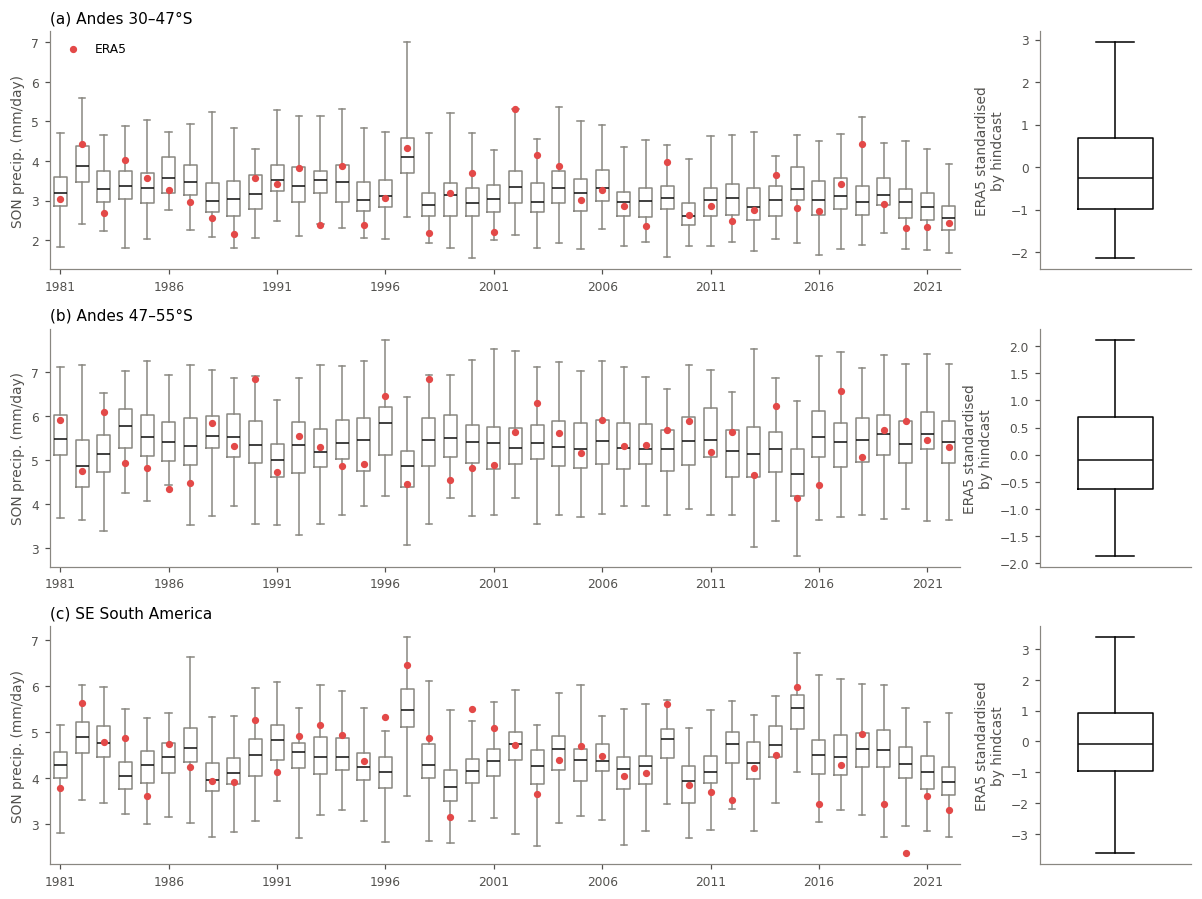

In [5]:
for r in REGIONS:
    fac = obs[f"P_{r}"].mean() / df.groupby("init_month")[f"P_{r}"].transform("mean")
    df[f"P_{r}_sc"] = df[f"P_{r}"] * fac

fig, axes = plt.subplots(NR, 2, figsize=(11, 2.75 * NR), gridspec_kw=dict(width_ratios=[6, 1]))
fid1 = {}
for i, r in enumerate(REGIONS):
    ax = axes[i, 0]
    g = df.groupby("year")[f"P_{r}_sc"]
    data = [g.get_group(y).values for y in obs.index]
    ax.boxplot(data, positions=obs.index, widths=0.6, whis=(0, 100), showfliers=False,
               medianprops=dict(color=INK), boxprops=dict(color="#898781"), whiskerprops=dict(color="#898781"),
               capprops=dict(color="#898781"))
    ax.scatter(obs.index, obs[f"P_{r}"], color=PCOL["El Niño"], s=14, zorder=3, label="ERA5")
    ax.set_xticks(obs.index[::5]); ax.set_xticklabels(obs.index[::5])
    ax.set_ylabel("SON precip. (mm/day)"); ax.set_title(f"({'abc'[i]}) {REGIONS[r]['name']}", loc="left")
    zs = np.array([(obs.loc[y, f"P_{r}"] - d.mean()) / d.std() for y, d in zip(obs.index, data)])
    pr = np.array([stats.percentileofscore(d, obs.loc[y, f"P_{r}"]) for y, d in zip(obs.index, data)])
    fid1[r] = dict(within_1sd=int((np.abs(zs) < 1).sum()), in_IQR=int(((pr > 25) & (pr < 75)).sum()),
                   lowest_10pct=int((pr < 10).sum()), outside_range=int(((pr == 0) | (pr == 100)).sum()))
    axes[i, 1].boxplot(zs, widths=0.5, whis=(0, 100), medianprops=dict(color=INK))
    axes[i, 1].set_xticks([]); axes[i, 1].set_ylabel("ERA5 standardised\nby hindcast")
axes[0, 0].legend(loc="upper left")
fig.tight_layout(); savefig(fig, "fig01_fidelity_boxplots")
pd.DataFrame(fid1).T.assign(n_years=len(obs))

**Fig. 2 equivalent.** (a) Moments test (Thompson et al. 2017): 10 000 sub-samples of 42 springs, one random
hindcast spring per year, scaled model precipitation; ERA5 should lie inside the 95 % range. (b) Stability:
the distribution for each lead (init month). (c) Member independence: Spearman correlation across years
between every pair of members, for each init month. A median above 0 means a predictable signal (expected
for SESA through ENSO) rather than dependent members.

AndesN median member-pair Spearman by init: [0.18, 0.2, 0.19]


AndesS median member-pair Spearman by init: [0.05, 0.06, 0.11]


SESA median member-pair Spearman by init: [0.27, 0.28, 0.24]


ERA5        lo        hi inside
AndesN mean      3.174642  3.034617  3.384939   True
       std       0.747128  0.504177  0.807717   True
       skewness  0.664557 -0.264241   1.45993   True
       kurtosis -0.086372 -1.004145  3.560969   True
AndesS mean      5.374453  5.153039  5.567037   True
       std       0.690334  0.575602  0.867568   True
       skewness  0.321765 -0.613754  0.622038   True
       kurtosis  -0.63702 -1.047342  0.954199   True
SESA   mean      4.422511  4.268855  4.595026   True
       std       0.833031   0.50913   0.76988  False
       skewness  0.108052 -0.512442  0.961969   True
       kurtosis -0.065751  -0.94506  2.012631   True

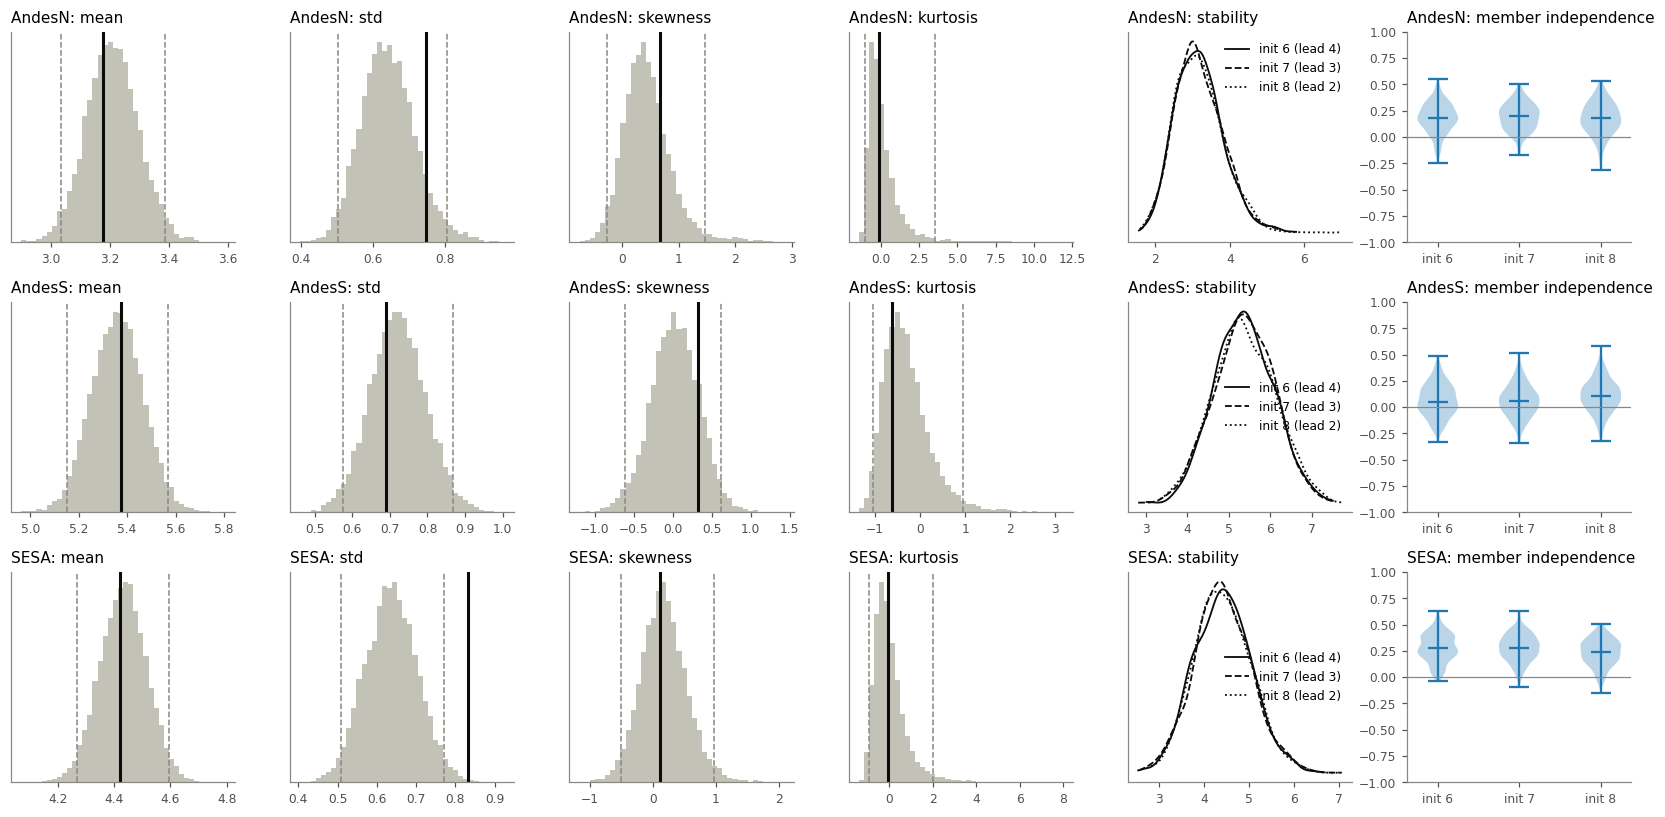

In [6]:
def moments(x):
    return np.array([x.mean(), x.std(ddof=1), stats.skew(x), stats.kurtosis(x)])


MOM = ["mean", "std", "skewness", "kurtosis"]
fig, axes = plt.subplots(NR, 6, figsize=(15, 2.5 * NR))
mom_tab = {}
for i, r in enumerate(REGIONS):
    byyear = [df[f"P_{r}_sc"].xs(y, level="year").values for y in obs.index]             # 75 or 153 springs per year
    sub = np.column_stack([v[RNG.integers(0, len(v), 10000)] for v in byyear])           # (10000, years)
    sm = np.apply_along_axis(moments, 1, sub)
    om = moments(obs[f"P_{r}"].values)
    for k in range(4):
        ax = axes[i, k]
        ax.hist(sm[:, k], bins=40, color=GREY)
        lo, hi = np.percentile(sm[:, k], [2.5, 97.5])
        for q in (lo, hi):
            ax.axvline(q, color="#898781", ls="--", lw=1)
        ax.axvline(om[k], color=INK, lw=2)
        ax.set_title(f"{r}: {MOM[k]}", loc="left"); ax.set_yticks([])
        mom_tab[(r, MOM[k])] = dict(ERA5=om[k], lo=lo, hi=hi, inside=lo <= om[k] <= hi)
    ax = axes[i, 4]
    for m, ls in zip(INITS, ["-", "--", ":"]):
        x = df.xs(m, level="init_month")[f"P_{r}_sc"]
        kde = stats.gaussian_kde(x)
        xx = np.linspace(x.min(), x.max(), 200)
        ax.plot(xx, kde(xx), color=INK, ls=ls, lw=1.2, label=f"init {m} (lead {SON[0] - m + 1})")
    ax.set_title(f"{r}: stability", loc="left"); ax.legend(); ax.set_yticks([])
    ax = axes[i, 5]
    cors = []
    for m in INITS:
        a = df.xs(m, level="init_month")[f"P_{r}"].unstack("number").values[:, :N_HC]   # members present in every year
        rho = stats.spearmanr(a).correlation
        cors.append(rho[np.triu_indices(N_HC, 1)])
    ax.violinplot(cors, showmedians=True)
    ax.axhline(0, color="#898781", lw=0.8)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels([f"init {m}" for m in INITS])
    ax.set_title(f"{r}: member independence", loc="left"); ax.set_ylim(-1, 1)
    print(r, "median member-pair Spearman by init:", [round(float(np.median(c)), 2) for c in cors])
fig.tight_layout(); savefig(fig, "fig02_fidelity_tests")
pd.DataFrame(mom_tab).T.round(3)

## 3. Drivers and precipitation (Chan et al. Fig. 3)

Grey: hindcast springs; black: ERA5. r = Pearson correlation of the standardised anomalies (hindcast / ERA5).

hindcast                ERA5             
        AndesN AndesS  SESA AndesN AndesS  SESA
A_SAM    -0.43  -0.05 -0.34  -0.52   0.25 -0.47
ENSO      0.33  -0.22  0.49   0.56  -0.34  0.58
IOD       0.23  -0.08  0.25   0.42  -0.31  0.21
SALLJ     0.57  -0.15  0.65   0.61  -0.06  0.60
SPV      -0.31   0.01 -0.09  -0.41  -0.07  0.01
S_SAM    -0.41  -0.07 -0.14  -0.28   0.04 -0.15

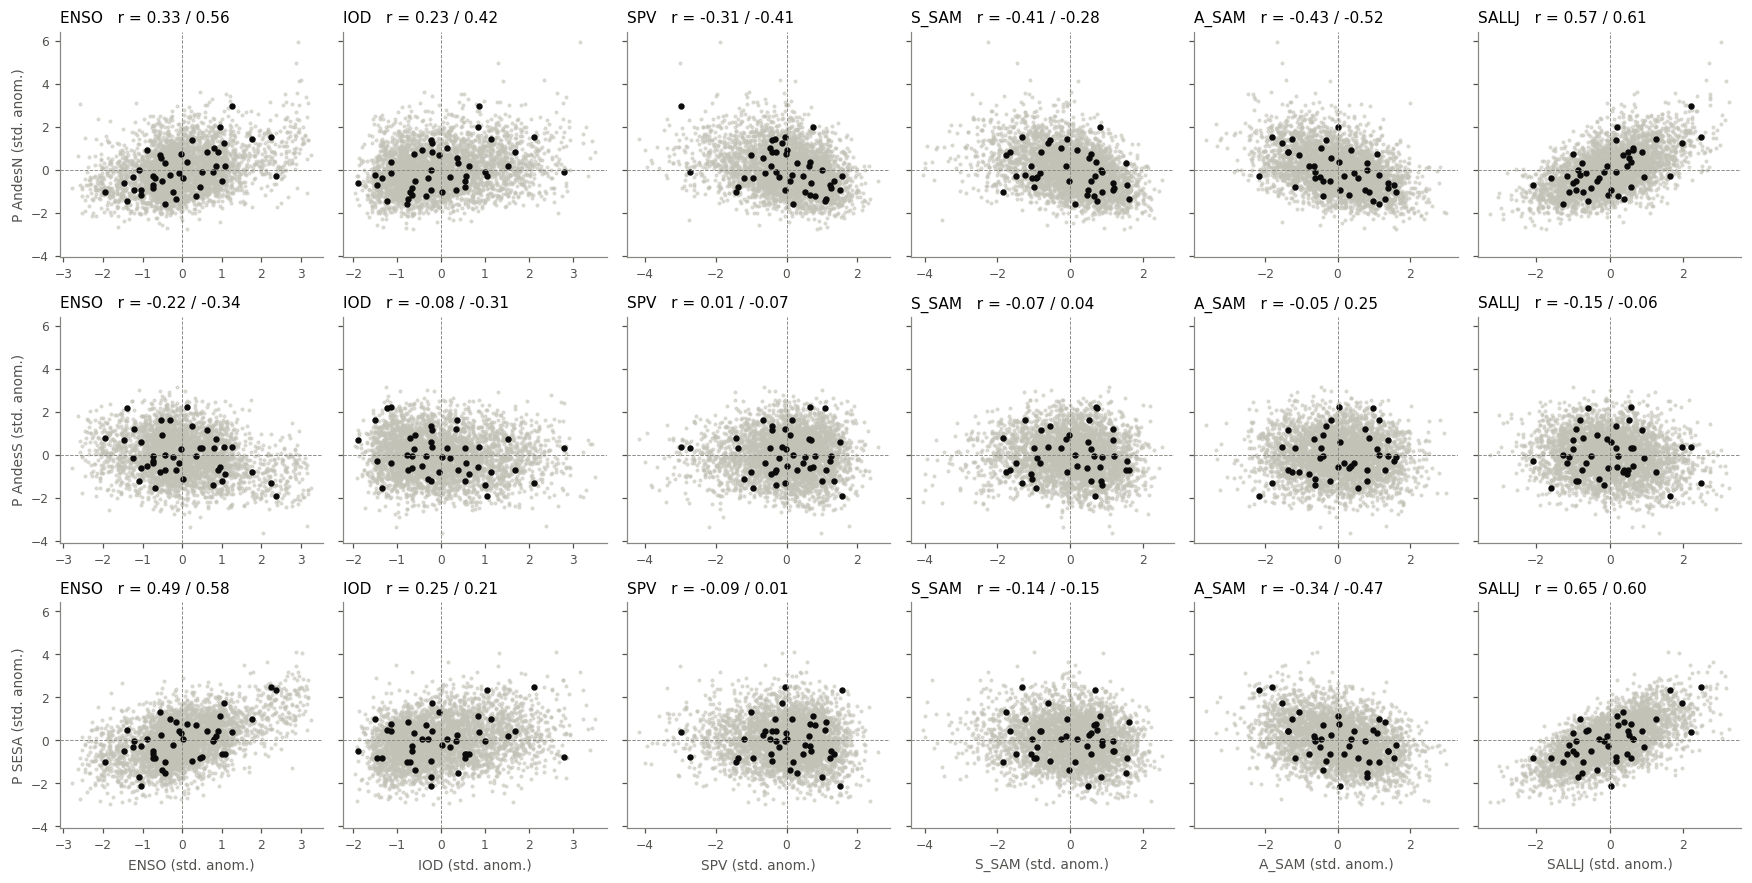

In [7]:
ALLD = DRIVERS + MEDS
fig, axes = plt.subplots(NR, len(ALLD), figsize=(16, 2.7 * NR), sharey=True)
cor_tab = {}
for i, r in enumerate(REGIONS):
    for j, v in enumerate(ALLD):
        ax = axes[i, j]
        ax.scatter(df[f"{v}_z"], df[f"P_{r}_z"], s=3, color=GREY, alpha=0.5, rasterized=True)
        ax.scatter(obs[f"{v}_z"], obs[f"P_{r}_z"], s=10, color=INK)
        rh, ro = df[f"{v}_z"].corr(df[f"P_{r}_z"]), obs[f"{v}_z"].corr(obs[f"P_{r}_z"])
        cor_tab[(r, v)] = dict(hindcast=rh, ERA5=ro)
        ax.set_title(f"{v}   r = {rh:.2f} / {ro:.2f}", loc="left")
        ax.axhline(0, color="#898781", lw=0.6, ls="--"); ax.axvline(0, color="#898781", lw=0.6, ls="--")
        if j == 0:
            ax.set_ylabel(f"P {r} (std. anom.)")
        if i == NR - 1:
            ax.set_xlabel(f"{v} (std. anom.)")
fig.tight_layout(); savefig(fig, "fig03_drivers_vs_precip")
pd.DataFrame(cor_tab).T.unstack(0).round(2)

**Which IOD × SPV combinations are dry?** (Chan et al. Fig. 3d.) The mean standardised precipitation of the
hindcast springs in each IOD–SPV bin, for each ENSO phase. Labelled dots: ERA5 springs of that phase.

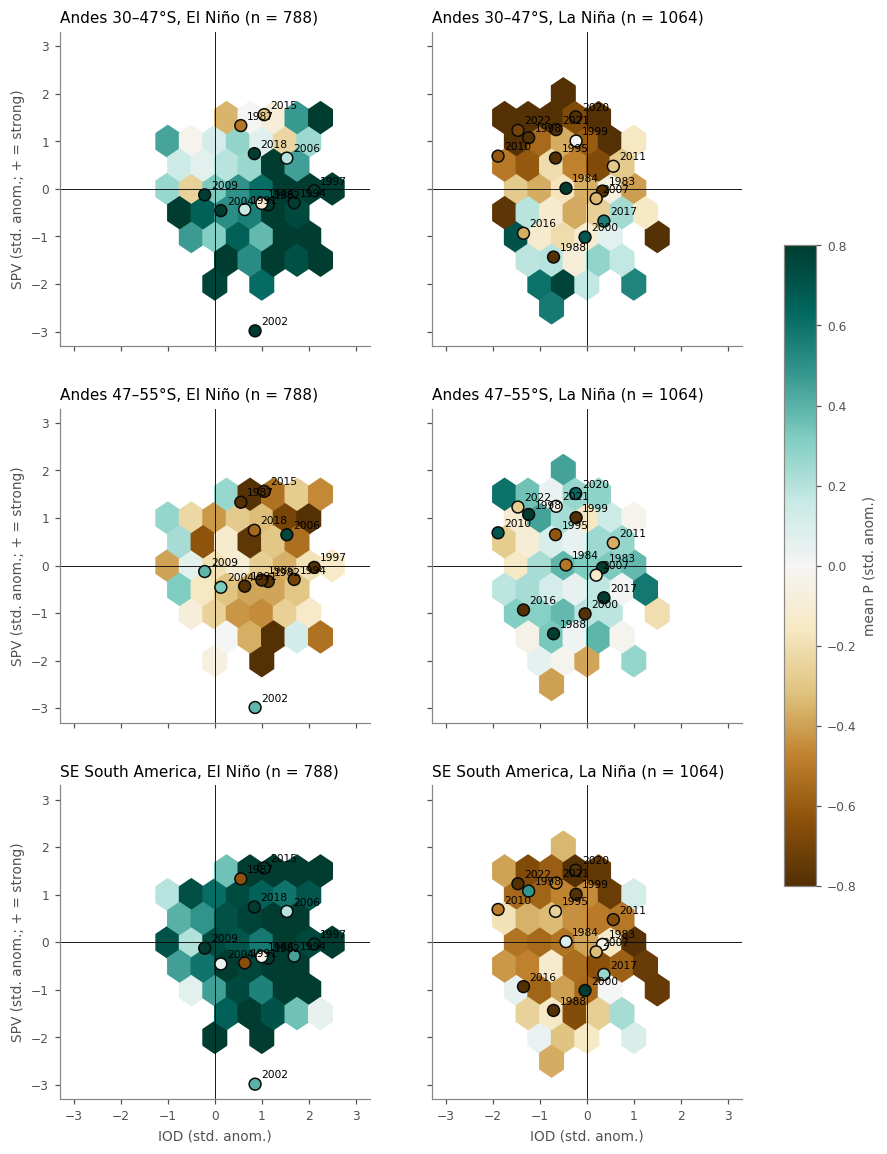

In [8]:
fig, axes = plt.subplots(NR, 2, figsize=(10, 4.2 * NR), sharex=True, sharey=True)
norm = mcolors.TwoSlopeNorm(0, -0.8, 0.8)
for i, r in enumerate(REGIONS):
    for j, ph in enumerate(PHASES):
        ax = axes[i, j]
        d = df[df.phase == ph]
        hb = ax.hexbin(d.IOD_z, d.SPV_z, C=d[f"P_{r}_z"], reduce_C_function=np.mean, gridsize=12,
                       mincnt=5, cmap="BrBG", norm=norm, extent=(-3, 3, -3, 3))
        o = obs[obs.phase == ph]
        ax.scatter(o.IOD_z, o.SPV_z, c=o[f"P_{r}_z"], cmap="BrBG", norm=norm, s=60, edgecolor=INK, zorder=3)
        for y, row in o.iterrows():
            ax.annotate(str(y), (row.IOD_z, row.SPV_z), xytext=(4, 4), textcoords="offset points", fontsize=7)
        ax.axhline(0, color=INK, lw=0.6); ax.axvline(0, color=INK, lw=0.6)
        ax.set_title(f"{REGIONS[r]['name']}, {ph} (n = {len(d)})", loc="left")
        if i == NR - 1:
            ax.set_xlabel("IOD (std. anom.)")
        if j == 0:
            ax.set_ylabel("SPV (std. anom.; + = strong)")
fig.colorbar(hb, ax=axes, shrink=0.6, label="mean P (std. anom.)")
savefig(fig, "fig04_iod_spv_precip_by_phase")

## 4. ENSO storylines: El Niño and La Niña, then IOD × SPV

Neutral springs are excluded. Within El Niño and La Niña, a hindcast spring is assigned to one of four quadrants
by the sign of the standardised IOD and SPV, **leaving out the inner 20 % of each driver's distribution**: springs with
IOD or SPV between its 40th and 60th percentile (pooled hindcast) belong to no storyline. This keeps near-zero drivers
from setting the quadrant. ERA5 springs are classified with the same thresholds (in σ). For each storyline: its probability within the phase, the mean precipitation anomaly, and
**P(dry)** (P below the 20th percentile of all 3618 springs; the climatological value is 0.20). The probability is the share among
the phase's kept springs, and the phase P(dry) is that of all the phase's springs.
90 % intervals: bootstrap over years (all springs of a year resampled together).

In [9]:
# quadrants without the inner 20 % of the IOD and SPV distributions
CUT = {v: df[f"{v}_z"].quantile([0.5 - INNER / 2, 0.5 + INNER / 2]).values for v in ["IOD", "SPV"]}


def outer(d):
    return np.logical_and.reduce([(d[f"{v}_z"] <= CUT[v][0]) | (d[f"{v}_z"] >= CUT[v][1]) for v in CUT])


df["quad4"] = df.quad.where(outer(df))
obs["quad4"] = obs.quad.where(outer(obs))
print("cuts (σ):", {v: np.round(c, 2).tolist() for v, c in CUT.items()})
for ph in PHASES:
    print(f"{ph}: {df.loc[df.phase == ph, 'quad4'].notna().mean():.0%} of springs kept;",
          "ERA5 years kept:", obs.index[(obs.phase == ph) & obs.quad4.notna()].tolist())

years = df.index.get_level_values("year").values
uyears = np.unique(years)
year_rows = {y: np.where(years == y)[0] for y in uyears}
BOOT_IDX = [np.concatenate([year_rows[y] for y in RNG.choice(uyears, len(uyears))]) for _ in range(N_BOOT)]


def boot_ci(func, d, level=90):
    """Bootstrap over years of a statistic func(DataFrame) -> float or array."""
    vals = np.array([func(d.iloc[ix]) for ix in BOOT_IDX])
    a = (100 - level) / 2
    return np.nanpercentile(vals, [a, 100 - a], axis=0)


rows = []
for ph in PHASES:
    dp = df[(df.phase == ph) & df.quad4.notna()]
    for q in QUADS:
        sel = (df.phase == ph) & (df.quad4 == q)
        d = df[sel]
        row = dict(phase=ph, storyline=q, n=len(d), years=d.index.get_level_values("year").nunique(),
                   prob=len(d) / len(dp))
        for r in REGIONS:
            row[f"P_{r}_z"] = d[f"P_{r}_z"].mean()
            row[f"P_{r}_pct"] = d[f"P_{r}_pct"].mean()
            row[f"Pdry_{r}"] = d[f"dry_{r}"].mean()
            lo, hi = boot_ci(lambda x: x.loc[(x.phase == ph) & (x.quad4 == q), f"dry_{r}"].mean(), df)
            row[f"Pdry_{r}_lo"], row[f"Pdry_{r}_hi"] = lo, hi
        for v in ["ENSO", "IOD_z", "SPV_z", "S_SAM_z", "A_SAM_z"]:
            row[f"mean_{v}"] = d[v].mean()
        rows.append(row)
    for r in REGIONS:
        print(f"{ph}: P(dry {r}) for the whole phase = {df.loc[df.phase == ph, f'dry_{r}'].mean():.2f}")
story = pd.DataFrame(rows)
story.to_csv(OUT / "enso_sam_storylines_summary.csv", index=False)
story[["phase", "storyline", "n", "prob"] + [f"{c}_{r}{s}" for r in REGIONS
                                              for c, s in [("P", "_pct"), ("Pdry", ""), ("Pdry", "_lo"), ("Pdry", "_hi")]]].round(2)

cuts (σ): {'IOD': [-0.43, 0.13], 'SPV': [-0.12, 0.35]}
El Niño: 62% of springs kept; ERA5 years kept: [1982, 1986, 1987, 1991, 1994, 2002, 2006, 2015, 2018]
La Niña: 67% of springs kept; ERA5 years kept: [1988, 1995, 1998, 2007, 2010, 2011, 2016, 2017, 2021, 2022]


El Niño: P(dry AndesN) for the whole phase = 0.10
El Niño: P(dry AndesS) for the whole phase = 0.29
El Niño: P(dry SESA) for the whole phase = 0.05


La Niña: P(dry AndesN) for the whole phase = 0.29
La Niña: P(dry AndesS) for the whole phase = 0.15
La Niña: P(dry SESA) for the whole phase = 0.33


,phase,storyline,n,prob,P_AndesN_pct,Pdry_AndesN,Pdry_AndesN_lo,Pdry_AndesN_hi,P_AndesS_pct,Pdry_AndesS,Pdry_AndesS_lo,Pdry_AndesS_hi,P_SESA_pct,Pdry_SESA,Pdry_SESA_lo,Pdry_SESA_hi
0,El Niño,IOD+ / weak SPV,226,0.46,115.50,0.04,0.01,0.07,94.73,0.32,0.26,0.38,112.22,0.05,0.03,0.07
1,El Niño,IOD+ / strong SPV,193,0.39,105.25,0.13,0.10,0.17,93.34,0.36,0.28,0.44,111.06,0.02,0.01,0.04
2,El Niño,IOD− / weak SPV,32,0.07,108.80,0.03,0.00,0.14,101.05,0.09,0.00,0.19,107.33,0.03,0.00,0.13
3,El Niño,IOD− / strong SPV,38,0.08,100.47,0.21,0.10,0.31,101.35,0.21,0.10,0.29,106.68,0.05,0.00,0.12
4,La Niña,IOD+ / weak SPV,104,0.15,102.84,0.16,0.09,0.23,102.16,0.12,0.06,0.20,94.75,0.31,0.20,0.41
5,La Niña,IOD+ / strong SPV,78,0.11,88.60,0.35,0.28,0.41,103.29,0.12,0.06,0.17,93.23,0.37,0.24,0.52
6,La Niña,IOD− / weak SPV,209,0.29,101.34,0.17,0.11,0.25,101.86,0.13,0.09,0.18,95.59,0.28,0.22,0.36
7,La Niña,IOD− / strong SPV,321,0.45,88.49,0.40,0.33,0.47,101.45,0.17,0.14,0.22,93.34,0.32,0.25,0.38


**Chan et al. Fig. 4 equivalent**: the distributions of precipitation and of each index within each storyline.

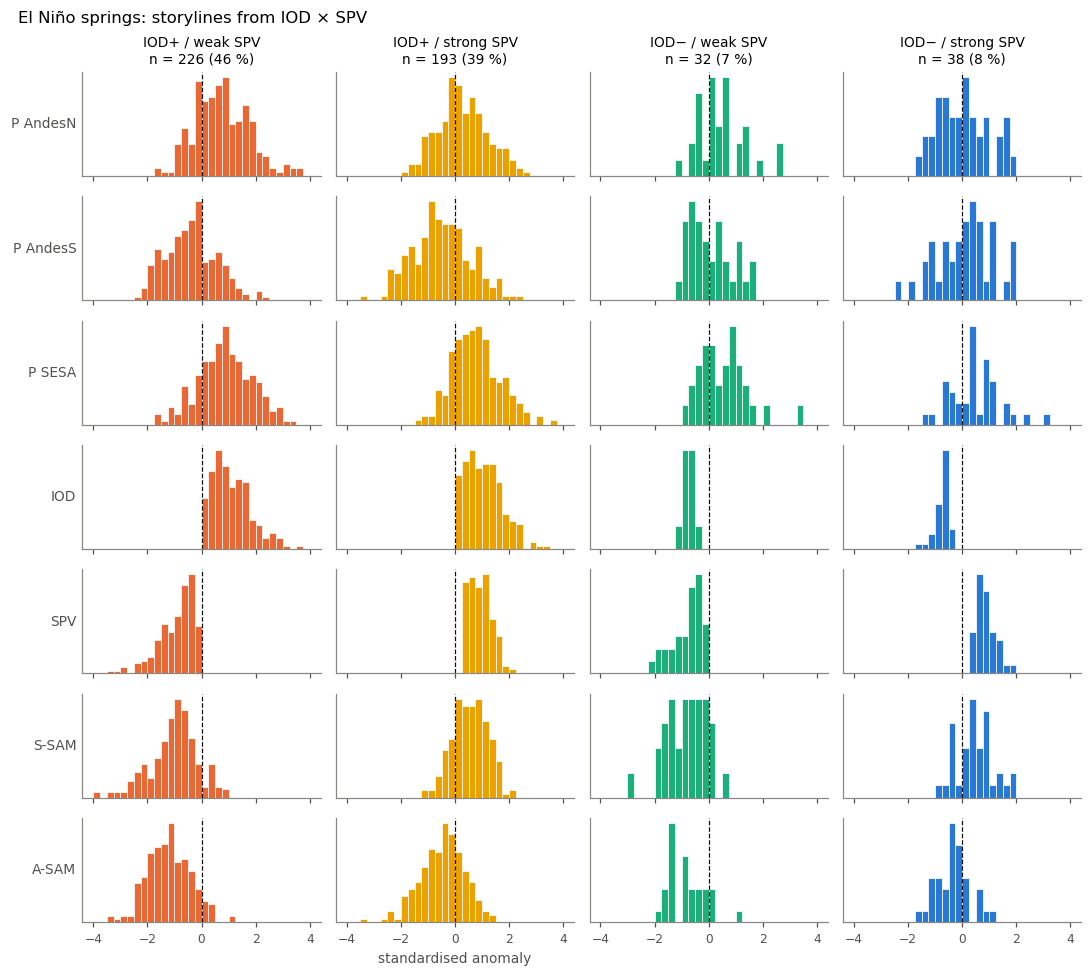

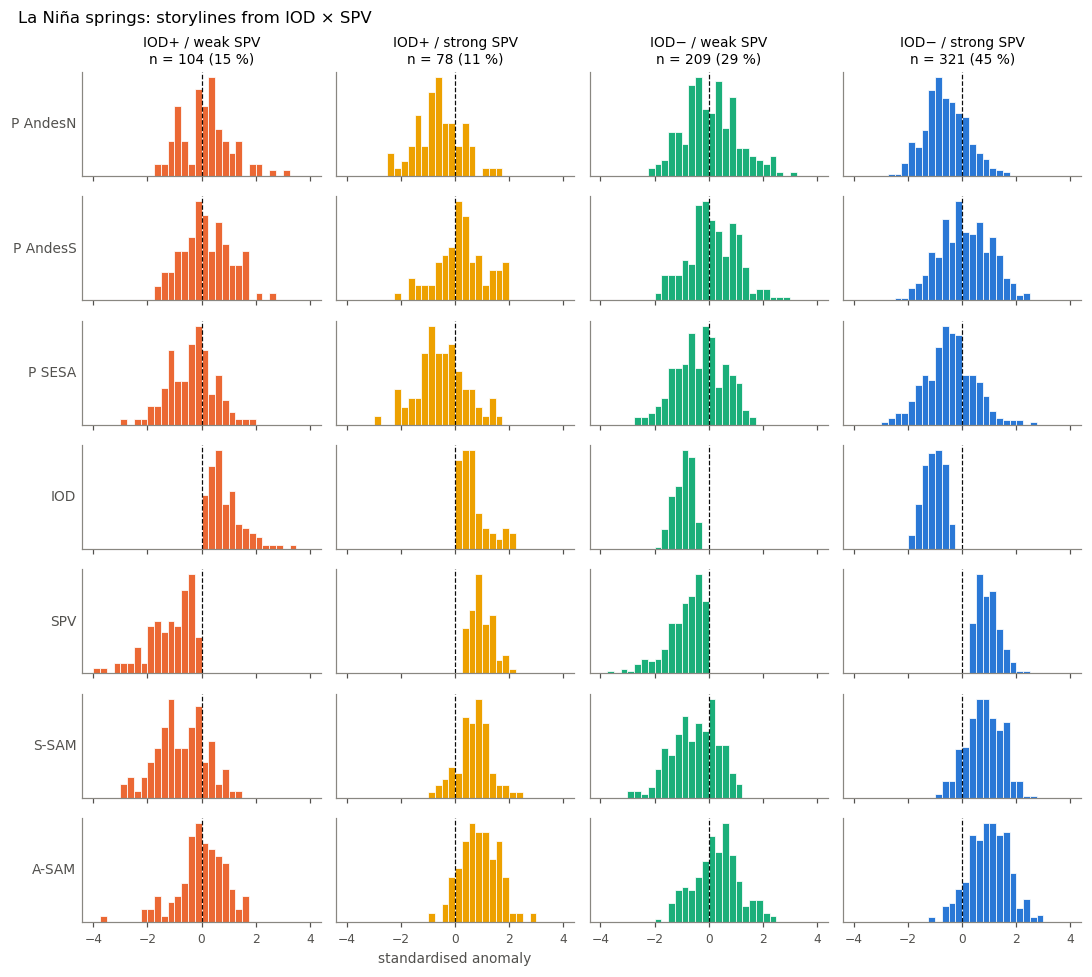

In [10]:
HROWS = [f"P_{r}_z" for r in REGIONS] + ["IOD_z", "SPV_z", "S_SAM_z", "A_SAM_z"]
HLAB = [f"P {r}" for r in REGIONS] + ["IOD", "SPV", "S-SAM", "A-SAM"]
for ph in PHASES:
    fig, axes = plt.subplots(len(HROWS), 4, figsize=(10, 9), sharex=True)
    for j, q in enumerate(QUADS):
        d = df[(df.phase == ph) & (df.quad4 == q)]
        p = story.query("phase == @ph and storyline == @q").iloc[0]
        axes[0, j].set_title(f"{q}\nn = {len(d)} ({100 * p.prob:.0f} %)", fontsize=9)
        for i, v in enumerate(HROWS):
            ax = axes[i, j]
            ax.hist(d[v], bins=np.linspace(-4, 4, 33), color=QCOL[q], edgecolor="white", linewidth=0.5)
            ax.axvline(0, color=INK, ls="--", lw=0.8); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(HLAB[i], rotation=0, ha="right", va="center")
    axes[-1, 1].set_xlabel("standardised anomaly")
    fig.suptitle(f"{ph} springs: storylines from IOD × SPV", x=0.02, ha="left")
    fig.tight_layout(); savefig(fig, f"fig05_storyline_histograms_{'nino' if ph == 'El Niño' else 'nina'}")

**Dry storylines.** P(dry) for each storyline, against the climatological 0.20 (dashed) and the ENSO phase
alone (dotted). A storyline is called *dry* when its 90 % interval lies above the phase value.

,phase,storyline,Pdry_AndesN,dry_storyline_AndesN,Pdry_AndesS,dry_storyline_AndesS,Pdry_SESA,dry_storyline_SESA
0,El Niño,IOD+ / weak SPV,0.04,False,0.32,False,0.05,False
1,El Niño,IOD+ / strong SPV,0.13,True,0.36,False,0.02,False
2,El Niño,IOD− / weak SPV,0.03,False,0.09,False,0.03,False
3,El Niño,IOD− / strong SPV,0.21,True,0.21,False,0.05,False
4,La Niña,IOD+ / weak SPV,0.16,False,0.12,False,0.31,False
5,La Niña,IOD+ / strong SPV,0.35,False,0.12,False,0.37,False
6,La Niña,IOD− / weak SPV,0.17,False,0.13,False,0.28,False
7,La Niña,IOD− / strong SPV,0.40,True,0.17,False,0.32,False


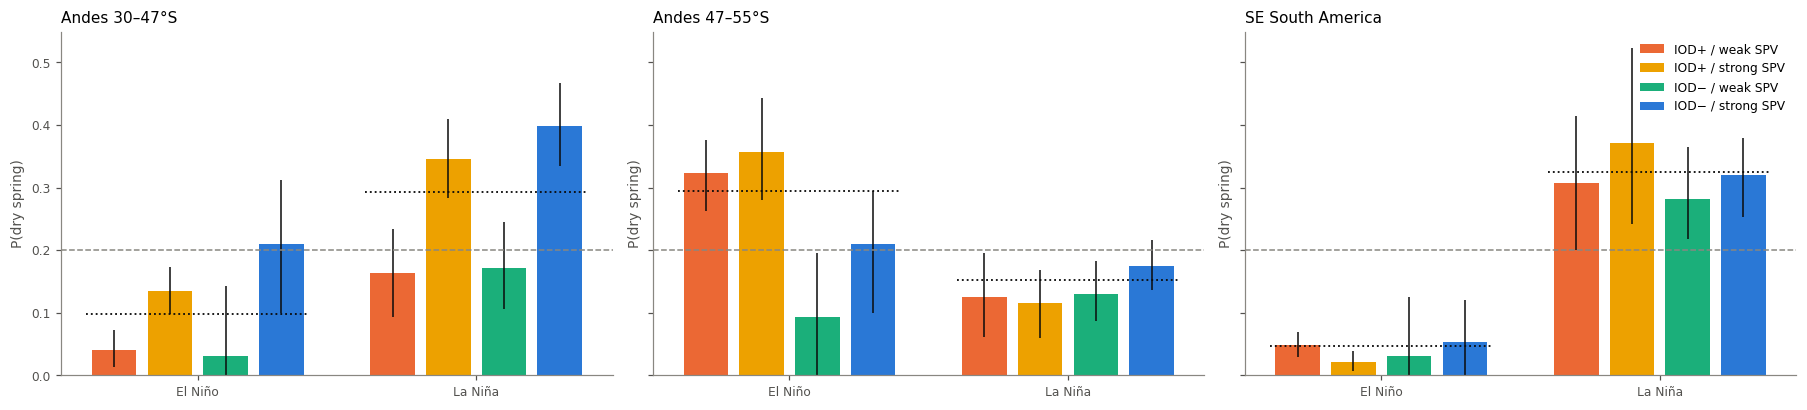

In [11]:
fig, axes = plt.subplots(1, NR, figsize=(5.5 * NR, 3.8), sharey=True)
for i, r in enumerate(REGIONS):
    ax = axes[i]
    for j, ph in enumerate(PHASES):
        base = df.loc[df.phase == ph, f"dry_{r}"].mean()
        for k, q in enumerate(QUADS):
            p = story.query("phase == @ph and storyline == @q").iloc[0]
            x = j * 5 + k
            ax.bar(x, p[f"Pdry_{r}"], color=QCOL[q], width=0.8, label=q if j == 0 else None)
            ax.errorbar(x, p[f"Pdry_{r}"], yerr=[[p[f"Pdry_{r}"] - p[f"Pdry_{r}_lo"]],
                                                 [p[f"Pdry_{r}_hi"] - p[f"Pdry_{r}"]]], color=INK, lw=1)
        ax.hlines(base, j * 5 - 0.5, j * 5 + 3.5, color=INK, ls=":", lw=1.2)
    ax.axhline(DRY_Q, color="#898781", ls="--", lw=1)
    ax.set_xticks([1.5, 6.5]); ax.set_xticklabels(PHASES)
    ax.set_title(REGIONS[r]["name"], loc="left"); ax.set_ylabel("P(dry spring)")
axes[-1].legend(loc="upper right", ncol=1)
fig.tight_layout(); savefig(fig, "fig06_pdry_storylines")

for r in REGIONS:
    story[f"dry_storyline_{r}"] = story[f"Pdry_{r}_lo"] > story.phase.map(df.groupby("phase")[f"dry_{r}"].mean())
story[["phase", "storyline"] + [c for r in REGIONS for c in (f"Pdry_{r}", f"dry_storyline_{r}")]].round(2)

**Check: are the quadrants a fair summary? (Chan et al. use k-means.)** k-means (K = 4) on the
standardised IOD and SPV within each phase, compared with the quadrants (adjusted Rand index: 1 = identical).

In [12]:
for ph in PHASES:
    d = df[(df.phase == ph) & df.quad4.notna()]
    X = d[["IOD_z", "SPV_z"]].values
    km = KMeans(4, n_init=20, random_state=0).fit(X)
    ari = adjusted_rand_score(d.quad4, km.labels_)
    print(f"{ph}: ARI(k-means, quadrants) = {ari:.2f}; k-means centroids (IOD, SPV):",
          np.round(km.cluster_centers_[np.argsort(km.cluster_centers_[:, 0])], 2).tolist())

El Niño: ARI(k-means, quadrants) = 0.47; k-means centroids (IOD, SPV): [[0.02, 0.87], [0.26, -0.73], [1.47, 0.98], [1.59, -1.12]]
La Niña: ARI(k-means, quadrants) = 0.98; k-means centroids (IOD, SPV): [[-1.05, 0.95], [-0.93, -0.9], [0.66, 0.83], [0.91, -1.36]]


**Circulation of each storyline (Chan et al. Fig. 5).** SEAS5 SON MSLP anomaly composites (relative to each
init month's 1981–2022 climatology), and the ERA5 spring that resembles the composite most (pattern
correlation over 20–70°S) among the observed springs of the same ENSO phase. Maps are cut at 70°S because MSLP
over the Antarctic plateau is extrapolated below ground and would dominate. SEAS5 MSLP:
`storylines_data/msl_son_seas5_SH_1981-2022.nc` (made by `Codes/extract_msl_seas5.py --n_members 51 --years 1981 2022`).

ERA5_analogue pattern_r  analogue_quadrant
El Niño IOD+ / weak SPV            1994      0.86    IOD+ / weak SPV
        IOD+ / strong SPV          2015      0.64  IOD+ / strong SPV
        IOD− / weak SPV            1991      0.82    IOD+ / weak SPV
        IOD− / strong SPV          1986      0.56    IOD+ / weak SPV
La Niña IOD+ / weak SPV            1988      0.76    IOD− / weak SPV
        IOD+ / strong SPV          2021      0.84  IOD− / strong SPV
        IOD− / weak SPV            1988      0.78    IOD− / weak SPV
        IOD− / strong SPV          2021      0.85  IOD− / strong SPV

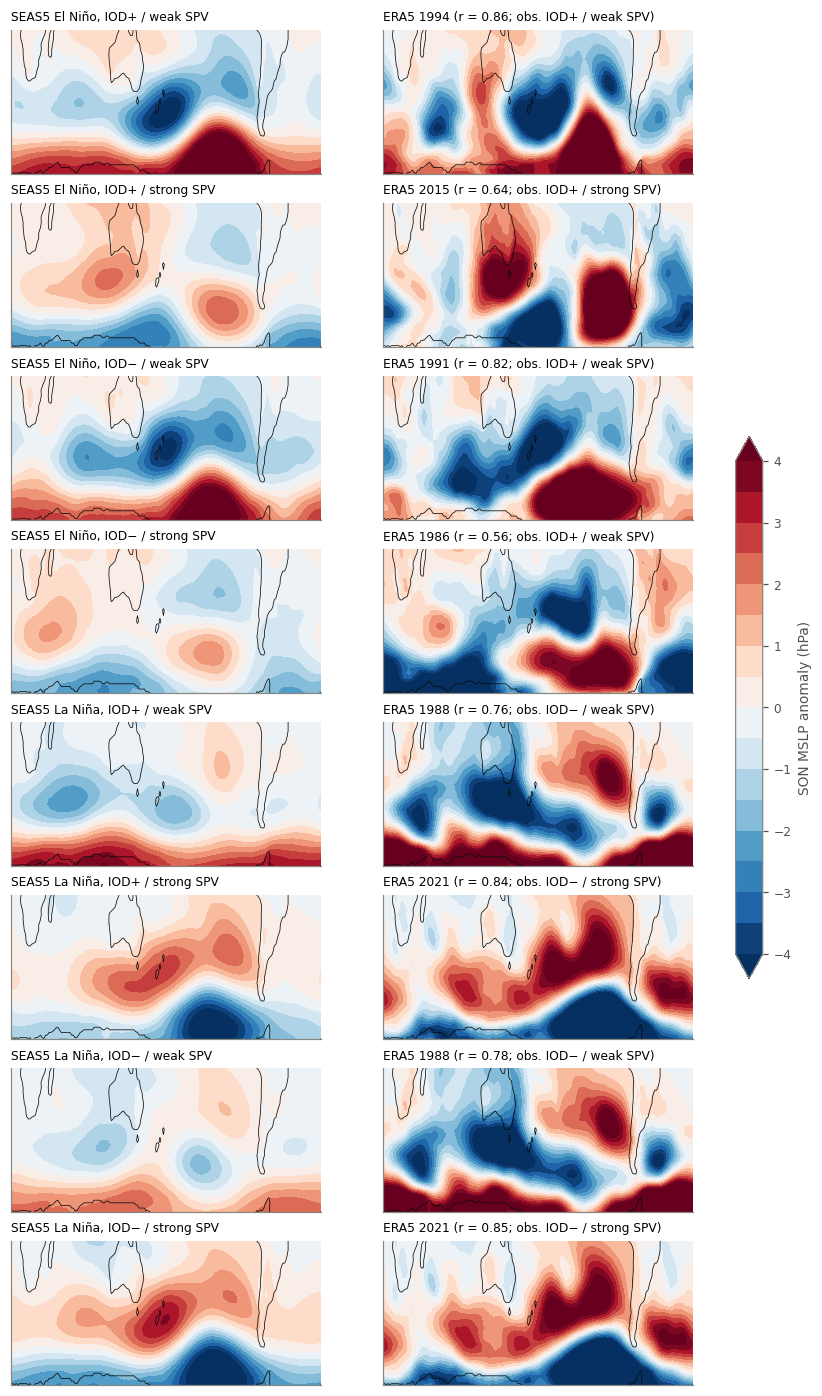

In [13]:
msl = xr.open_dataset(DATA / "msl_son_seas5_SH_1981-2022.nc")["msl"]
msl = msl.assign_coords(year=("forecast_reference_time", msl.init_year.values))
msl_a = msl.groupby("init_month") - msl.groupby("init_month").mean(["forecast_reference_time", "number"])
lat_m, lon_m = msl.latitude.values, msl.longitude.values

e5 = xr.open_dataset(DATA / "ERA5_mean_sea_level_pressure_monthly.nc")["msl"]
e5 = e5.sel(valid_time=e5.valid_time.dt.month.isin(SON)).sel(
    valid_time=slice(f"{YEARS[0]}-09", f"{YEARS[1]}-11"), latitude=slice(0, -90))
e5 = (e5.groupby("valid_time.year").mean() / 100.0).load()
e5 = e5.interp(latitude=lat_m, longitude=lon_m)
e5_a = e5 - e5.mean("year")

# coastlines from the SEAS5 land mask (SST missing over land)
s5 = xr.open_dataset(DATA / "seas5_single_levels_06-12month_1-6leadtimemonth.nc")["sst"]
land = s5.isel(number=0, forecast_reference_time=0, forecastMonth=0).sel(latitude=slice(0, -90)).isnull()
land = land.astype(float).coarsen(latitude=2, longitude=2, boundary="trim").mean().values


def composite(sel_df):
    keys = pd.MultiIndex.from_frame(sel_df.reset_index()[["year", "init_month", "number"]])
    m = msl_a.stack(s=("forecast_reference_time", "number"))
    idx = pd.MultiIndex.from_arrays([m.year.values, m.init_month.values, m.number.values])
    return m.isel(s=np.where(idx.isin(keys))[0]).mean("s")


def pattern_corr(a, b, latband=(-70, -20)):
    w = np.cos(np.deg2rad(a.latitude)).broadcast_like(a)
    msk = (a.latitude >= latband[0]) & (a.latitude <= latband[1])
    a, b, w = a.where(msk), b.where(msk), w.where(msk)
    am, bm = (a * w).sum() / w.sum(), (b * w).sum() / w.sum()
    return float(((a - am) * (b - bm) * w).sum() / np.sqrt(((a - am) ** 2 * w).sum() * ((b - bm) ** 2 * w).sum()))


comps, analog = {}, {}
for ph in PHASES:
    for q in QUADS:
        c = composite(df[(df.phase == ph) & (df.quad4 == q)])
        comps[(ph, q)] = c
        cands = obs.index[obs.phase == ph]
        pc = {y: pattern_corr(c, e5_a.sel(year=y)) for y in cands}
        best = max(pc, key=pc.get)
        analog[(ph, q)] = (best, pc[best], obs.quad4.fillna("inner 20 %")[best])

lev = np.arange(-4, 4.5, 0.5)
fig, axes = plt.subplots(8, 2, figsize=(10, 16))
for i, (key, c) in enumerate(comps.items()):
    y, pc, oq = analog[key]
    for j, (fld, ttl) in enumerate([(c, f"SEAS5 {key[0]}, {key[1]}"),
                                    (e5_a.sel(year=y), f"ERA5 {y} (r = {pc:.2f}; obs. {oq})")]):
        ax = axes[i, j]
        cf = ax.contourf(lon_m, lat_m, fld.values, levels=lev, cmap="RdBu_r", extend="both")
        ax.contour(lon_m, lat_m, land, levels=[0.5], colors=INK, linewidths=0.5)
        ax.set_ylim(-70, -15); ax.set_title(ttl, loc="left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(cf, ax=axes, shrink=0.4, label="SON MSLP anomaly (hPa)")
savefig(fig, "fig07_mslp_composites")
pd.DataFrame({k: dict(ERA5_analogue=v[0], pattern_r=round(v[1], 2), analogue_quadrant=v[2])
              for k, v in analog.items()}).T

## 5. Path model: ENSO, IOD and SPV acting directly and through the SAM and the SACZ

The causal ordering follows `Regression_maps_hindcast.ipynb` (ENSO → IOD → SPV → SAM → P), with the **SACZ** added as a third
mediator next to S-SAM and A-SAM. SACZ index: SON precipitation over 25–15°S, 50–35°W (land and ocean; positive = active SACZ),
from SEAS5 and ERA5, detrended and standardised like everything else. All variables are standardised anomalies and all springs
are pooled. Equations (OLS):

$$\mathrm{IOD} = a_1\,\mathrm{ENSO},\qquad \mathrm{SPV} = b_1\,\mathrm{ENSO} + b_2\,\mathrm{IOD},$$
$$M_k = c_{k1}\,\mathrm{ENSO} + c_{k2}\,\mathrm{IOD} + c_{k3}\,\mathrm{SPV} + M_k^{\mathrm{res}},\quad M_k\in\{\text{S-SAM}, \text{A-SAM}, \text{SACZ}\},$$
$$P = e_E\,\mathrm{ENSO} + e_I\,\mathrm{IOD} + e_V\,\mathrm{SPV} + e_S\,\mathrm{S\text{-}SAM} + e_A\,\mathrm{A\text{-}SAM}
  + e_Z\,\mathrm{SACZ} + \varepsilon .$$

* **direct effect** of driver X: $e_X$;
* **effect through S-SAM**, **through A-SAM** and **through the SACZ**, three separate mediators: every path that ends with
  S-SAM → P (e.g. ENSO → S-SAM → P, ENSO → IOD → SPV → S-SAM → P), and likewise for A-SAM and the SACZ. The mediators do not act
  on each other in the model, so no path passes through two of them and the three add up exactly. "Through the SAM" means
  S-SAM + A-SAM; the SACZ is reported on its own;
* **effect through the other drivers** (no mediator): e.g. ENSO → IOD → P;
* **total effect** = the sum of the three. It is checked against the total-effect regressions of this study
  (ENSO alone; IOD | ENSO; SPV | ENSO, IOD), which must match exactly for OLS.

Path tracing: with $B$ the coefficient matrix ($B_{ij}$ = coefficient of $j$ in the equation of $i$), the total
effects are $(I-B)^{-1} - I$. The effect through S-SAM is the total effect minus the total effect recomputed with
$e_S = 0$; the same with $e_A = 0$ for A-SAM.

This study's own direct-effect control sets (`modify_driver_list`: A-SAM left out when estimating SPV and S-SAM,
and SPV and S-SAM left out when estimating A-SAM) are also shown for comparison.

In [14]:
NODES = DRIVERS + MEDS + ["P"]
PARENTS = {"IOD": ["ENSO"], "SPV": ["ENSO", "IOD"], **{m: ["ENSO", "IOD", "SPV"] for m in MEDS},
           "P": ["ENSO", "IOD", "SPV"] + MEDS}


def ols(y, X):
    X1 = np.column_stack([np.ones(len(y)), X])
    b, *_ = np.linalg.lstsq(X1, y, rcond=None)
    return b[1:], b[0]


def fit_sem(d, region, suffix="_z"):
    """Fit the path model on DataFrame d. Returns B (len(NODES) x len(NODES))."""
    col = {n: f"{n}{suffix}" for n in NODES[:-1]} | {"P": f"P_{region}{suffix}"}
    B = np.zeros((len(NODES), len(NODES)))
    for child, pa in PARENTS.items():
        b, _ = ols(d[col[child]].values, d[[col[p] for p in pa]].values)
        for p, v in zip(pa, b):
            B[NODES.index(child), NODES.index(p)] = v
    return B


def total_effects(B):
    return np.linalg.inv(np.eye(len(NODES)) - B) - np.eye(len(NODES))


def effects(B):
    """Direct, through each SAM, through the other drivers and total effects of each driver on P."""
    iP = NODES.index("P")
    T = total_effects(B)
    meds = [n for n in NODES if n not in DRIVERS + ["P"]]
    B0 = B.copy(); B0[iP, [NODES.index(s) for s in meds]] = 0
    T0 = total_effects(B0)
    Tk = {}
    for s_ in meds:                                # switch off one mediator -> P arrow at a time
        Bk = B.copy(); Bk[iP, NODES.index(s_)] = 0
        Tk[s_] = total_effects(Bk)
    out = {}
    for x in DRIVERS:
        j = NODES.index(x)
        via = {f"via_{s_}": T[iP, j] - Tk[s_][iP, j] for s_ in meds}
        out[x] = dict(direct=B[iP, j], **via, via_SAM=sum(v for k, v in via.items() if "SAM" in k),
                      via_other_drivers=T0[iP, j] - B[iP, j], total=T[iP, j])
    for s_ in meds:
        out[s_] = dict(direct=B[iP, NODES.index(s_)], **{f"via_{k}": 0.0 for k in meds}, via_SAM=0.0,
                       via_other_drivers=0.0, total=B[iP, NODES.index(s_)])
    return pd.DataFrame(out).T


ECOLS = ["direct"] + [f"via_{s_}" for s_ in MEDS] + ["via_SAM", "via_other_drivers", "total"]


def total_regressions(d, region, suffix="_z"):
    """This study's total-effect regressions: ENSO alone; IOD | ENSO; SPV | ENSO, IOD."""
    y = d[f"P_{region}{suffix}"].values
    ctrl = {"ENSO": [], "IOD": ["ENSO"], "SPV": ["ENSO", "IOD"]}
    return {x: ols(y, d[[f"{v}{suffix}" for v in [x] + c]].values)[0][0] for x, c in ctrl.items()}


def study_direct(d, region, suffix="_z"):
    """This study's direct-effect control sets (modify_driver_list, total_eff=False)."""
    y = d[f"P_{region}{suffix}"].values
    allv = DRIVERS + SAMS
    ctrl = {v: [c for c in allv if c != v] for v in allv}
    for v in ["SPV", "S_SAM"]:
        ctrl[v].remove("A_SAM")
    ctrl["A_SAM"] = [c for c in ctrl["A_SAM"] if c not in ["SPV", "S_SAM"]]
    return {v: ols(y, d[[f"{c}{suffix}" for c in [v] + ctrl[v]]].values)[0][0] for v in allv}


SEM, EFF, EFF_CI = {}, {}, {}
for r in REGIONS:
    B = fit_sem(df, r)
    SEM[r] = B
    e = effects(B)
    e["total_regression"] = pd.Series(total_regressions(df, r))
    e["study_direct_controls"] = pd.Series(study_direct(df, r))
    boots = np.array([effects(fit_sem(df.iloc[ix], r))[ECOLS].values for ix in BOOT_IDX])
    lo, hi = np.percentile(boots, [5, 95], axis=0)
    for k, c in enumerate(ECOLS):
        e[f"{c}_ci"] = [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(lo[:, k], hi[:, k])]
    EFF[r] = e
    print(f"\n=== {REGIONS[r]['name']} ===")
    print("max |total from paths - total regression| =",
          np.nanmax(np.abs(e.loc[DRIVERS, "total"] - e.loc[DRIVERS, "total_regression"])).round(6),
          "; max |via S-SAM + via A-SAM - via SAM| =",
          np.abs(e.loc[DRIVERS, "via_S_SAM"] + e.loc[DRIVERS, "via_A_SAM"] - e.loc[DRIVERS, "via_SAM"]).max())
    for x in DRIVERS:
        for s_ in MEDS:
            e.loc[x, f"prop_mediated_{s_}"] = e.loc[x, f"via_{s_}"] / e.loc[x, "total"]
    display(e.round(3)) if "display" in dir() else print(e.round(3))

print("\nMediator equations (shared by all regions):")
med = pd.DataFrame(SEM[RK[0]][[NODES.index(n) for n in ["IOD", "SPV"] + MEDS]][:, :3],
                   index=["IOD", "SPV"] + MEDS, columns=DRIVERS)
med.round(3)


=== Andes 30–47°S ===
max |total from paths - total regression| = 0.0 ; max |via S-SAM + via A-SAM - via SAM| = 0.0
       direct  via_S_SAM  via_A_SAM  via_SALLJ  via_SAM  via_other_drivers  \
ENSO    0.003      0.046      0.018      0.258    0.064              0.007   
IOD     0.015      0.030      0.003      0.044    0.033              0.000   
SPV    -0.001     -0.238     -0.012     -0.047   -0.250              0.000   
S_SAM  -0.313      0.000      0.000      0.000    0.000              0.000   
A_SAM  -0.032      0.000      0.000      0.000    0.000              0.000   
SALLJ   0.501      0.000      0.000      0.000    0.000              0.000   

       total  total_regression  study_direct_controls         direct_ci  \
ENSO   0.331             0.331                  0.158  [-0.069, +0.061]   
IOD    0.091             0.091                  0.047  [-0.024, +0.057]   
SPV   -0.298            -0.298                 -0.055  [-0.034, +0.028]   
S_SAM -0.313               NaN      


=== Andes 47–55°S ===
max |total from paths - total regression| = 0.0 ; max |via S-SAM + via A-SAM - via SAM| = 0.0
       direct  via_S_SAM  via_A_SAM  via_SALLJ  via_SAM  via_other_drivers  \
ENSO   -0.361      0.028      0.180     -0.066    0.208              0.001   
IOD     0.022      0.018      0.027     -0.011    0.045             -0.025   
SPV     0.257     -0.145     -0.119      0.012   -0.264              0.000   
S_SAM  -0.191      0.000      0.000      0.000    0.000              0.000   
A_SAM  -0.323      0.000      0.000      0.000    0.000              0.000   
SALLJ  -0.128      0.000      0.000      0.000    0.000              0.000   

       total  total_regression  study_direct_controls         direct_ci  \
ENSO  -0.217            -0.217                 -0.400  [-0.413, -0.310]   
IOD    0.031             0.031                  0.014  [-0.016, +0.059]   
SPV    0.004             0.004                  0.198  [+0.211, +0.297]   
S_SAM -0.191               NaN      


=== SE South America ===
max |total from paths - total regression| = 0.0 ; max |via S-SAM + via A-SAM - via SAM| = 0.0
       direct  via_S_SAM  via_A_SAM  via_SALLJ  via_SAM  via_other_drivers  \
ENSO    0.266      0.008     -0.061      0.290   -0.053             -0.012   
IOD    -0.026      0.005     -0.009      0.049   -0.004              0.002   
SPV    -0.017     -0.042      0.040     -0.053   -0.001              0.000   
S_SAM  -0.055      0.000      0.000      0.000    0.000              0.000   
A_SAM   0.109      0.000      0.000      0.000    0.000              0.000   
SALLJ   0.563      0.000      0.000      0.000    0.000              0.000   

       total  total_regression  study_direct_controls         direct_ci  \
ENSO   0.491             0.491                  0.441  [+0.201, +0.331]   
IOD    0.021             0.021                  0.010  [-0.079, +0.013]   
SPV   -0.071            -0.071                 -0.046  [-0.043, +0.011]   
S_SAM -0.055               NaN   

,ENSO,IOD,SPV
IOD,0.471,0.000,0.000
SPV,0.011,-0.099,0.000
S_SAM,-0.109,-0.021,0.760
A_SAM,-0.523,-0.047,0.368
SALLJ,0.475,0.078,-0.093


**Path diagrams.** Arrow width is proportional to |coefficient|; brown arrows dry, green arrows wet (for the
arrows into P); for the other arrows red = positive, blue = negative. Coefficients in standard deviations per
standard deviation. Solid arrows: the 90 % bootstrap interval over years (all springs of a year resampled together, as everywhere
in this notebook) excludes 0; faded dashed arrows: it does not. The same rule is used for the ERA5 diagrams below.

arrows not significant (SEAS5): {'AndesN': ['ENSO → SPV', 'IOD → S_SAM', 'IOD → A_SAM', 'IOD → SALLJ', 'ENSO → P', 'IOD → P', 'SPV → P', 'A_SAM → P'], 'AndesS': ['ENSO → SPV', 'IOD → S_SAM', 'IOD → A_SAM', 'IOD → SALLJ', 'IOD → P'], 'SESA': ['ENSO → SPV', 'IOD → S_SAM', 'IOD → A_SAM', 'IOD → SALLJ', 'IOD → P', 'SPV → P']}


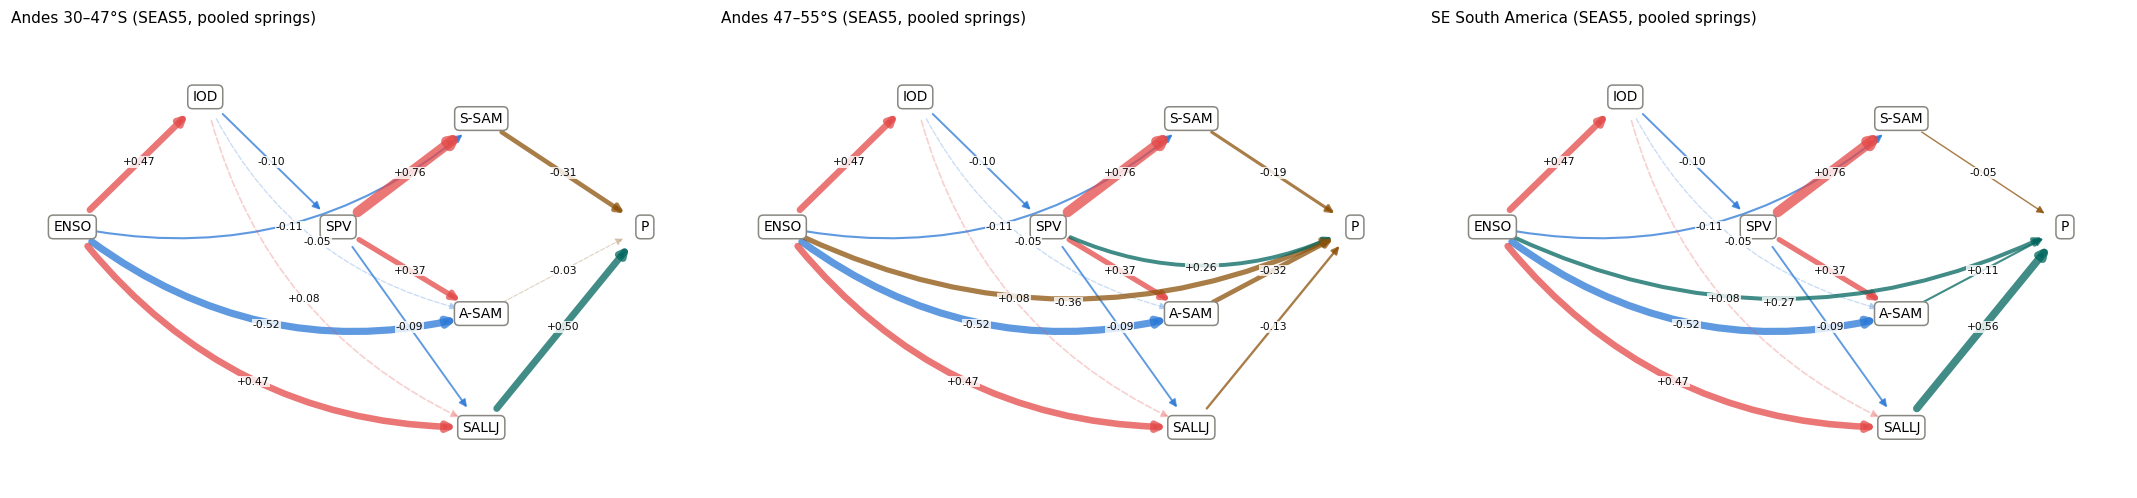

In [15]:
POS = {"ENSO": (0, 2), "IOD": (1.3, 3.2), "SPV": (2.6, 2), "S_SAM": (4, 3.0), "A_SAM": (4, 1.2), "SALLJ": (4, 0.15),
       "P": (5.6, 2)}


def draw_sem(ax, B, title, sig=None):
    """sig: optional boolean matrix like B; False draws the arrow faded and dashed (interval includes 0)."""
    for n, (x, y) in POS.items():
        ax.text(x, y, n.replace("_", "-"), ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#898781"))
    for i, c in enumerate(NODES):
        for j, p in enumerate(NODES):
            v = B[i, j]
            if v == 0 or abs(v) < 0.03:
                continue
            col = ("#8c510a" if v < 0 else "#01665e") if c == "P" else ("#e34948" if v > 0 else "#2a78d6")
            rad = 0.25 if (p, c) in [("ENSO", "SPV"), ("ENSO", "P"), ("IOD", "P"), ("ENSO", "S_SAM"),
                                     ("ENSO", "A_SAM"), ("SPV", "P"), ("IOD", "S_SAM"), ("IOD", "A_SAM"),
                                     ("ENSO", "SALLJ"), ("IOD", "SALLJ")] else 0.0
            weak = sig is not None and not sig[i, j]
            a = FancyArrowPatch(POS[p], POS[c], arrowstyle="-|>", mutation_scale=10, lw=0.5 + 8 * abs(v),
                                color=col, alpha=0.25 if weak else 0.75, ls="--" if weak else "-",
                                shrinkA=16, shrinkB=16, connectionstyle=f"arc3,rad={rad}")
            ax.add_patch(a)
            xm = (POS[p][0] + POS[c][0]) / 2 + rad * (POS[c][1] - POS[p][1]) * 0.5
            ym = (POS[p][1] + POS[c][1]) / 2 - rad * (POS[c][0] - POS[p][0]) * 0.5
            ax.text(xm, ym, f"{v:+.2f}", fontsize=7, ha="center", va="center", color=INK,
                    bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.8))
    ax.set_xlim(-0.6, 6.2); ax.set_ylim(-0.4, 3.8); ax.axis("off"); ax.set_title(title, loc="left")


SIG = {}
for r in REGIONS:
    bs = np.array([fit_sem(df.iloc[ix], r) for ix in BOOT_IDX])
    lo, hi = np.percentile(bs, [5, 95], axis=0)
    SIG[r] = (lo > 0) | (hi < 0)
fig, axes = plt.subplots(1, NR, figsize=(6.5 * NR, 4.6))
for ax, r in zip(axes, REGIONS):
    draw_sem(ax, SEM[r], f"{REGIONS[r]['name']} (SEAS5, pooled springs)", sig=SIG[r])
fig.tight_layout(); savefig(fig, "fig08_path_diagrams")
print("arrows not significant (SEAS5):", {r: [f"{p_} → {c}" for c in NODES for p_ in PARENTS.get(c, [])
                                             if not SIG[r][NODES.index(c), NODES.index(p_)]] for r in REGIONS})

**The same path model fitted to ERA5** (40 observed springs, 1981–2022 without 2002 and 2019, which have no observed S-/A-SAM; observed drivers:
RONI, ERSST DMI, ERA5 SPV and this study's S-/A-SAM; ERA5 box precipitation). Solid arrows: the 90 % bootstrap interval over
years excludes 0; faded dashed arrows: it does not. Compare with the SEAS5 diagrams above.

SEAS5                     SEAS5_sig90                \
                AndesN    AndesS      SESA      AndesN AndesS   SESA   
A_SAM → P    -0.032364 -0.322592  0.108963       False   True   True   
ENSO → A_SAM -0.523122 -0.523122 -0.523122        True   True   True   
ENSO → IOD    0.471156  0.471156  0.471156        True   True   True   
ENSO → P      0.002636 -0.360564  0.266423       False   True   True   
ENSO → SALLJ  0.474655  0.474655  0.474655        True   True   True   
ENSO → SPV    0.011237  0.011237  0.011237       False  False  False   
ENSO → S_SAM -0.108979 -0.108979 -0.108979        True   True   True   
IOD → A_SAM    -0.0475   -0.0475   -0.0475       False  False  False   
IOD → P       0.015106  0.022214 -0.026032       False  False  False   
IOD → SALLJ   0.077782  0.077782  0.077782       False  False  False   
IOD → SPV    -0.098786 -0.098786 -0.098786        True   True   True   
IOD → S_SAM  -0.020515 -0.020515 -0.020515       False  False  False   
SALLJ → P     0.500589  -0.12774  0.562824        True   True   True   
SPV → A_SAM   0.368203  0.368203  0.368203        True   True   True   
SPV → P      -0.001298  0.256742 -0.016737       False   True  False   
SPV → SALLJ  -0.093422 -0.093422 -0.093422        True   True   True   
SPV → S_SAM   0.759838  0.759838  0.759838        True   True   True   
S_SAM → P    -0.313113 -0.191435 -0.054683        True   True   True   

                  ERA5                     ERA5_sig90                
                AndesN    AndesS      SESA     AndesN AndesS   SESA  
A_SAM → P     0.235366  0.116821  0.434823      False  False  False  
ENSO → A_SAM -0.518437 -0.518437 -0.518437       True   True   True  
ENSO → IOD    0.606976  0.606976  0.606976       True   True   True  
ENSO → P        0.3726 -0.312488  0.619069       True  False   True  
ENSO → SALLJ  0.471938  0.471938  0.471938       True   True   True  
ENSO → SPV    0.086923  0.086923  0.086923      False  False  False  
ENSO → S_SAM -0.073093 -0.073093 -0.073093      False  False  False  
IOD → A_SAM  -0.340706 -0.340706 -0.340706       True   True   True  
IOD → P       0.130027  -0.34327 -0.247564      False  False  False  
IOD → SALLJ   0.213373  0.213373  0.213373      False  False  False  
IOD → SPV    -0.146842 -0.146842 -0.146842      False  False  False  
IOD → S_SAM  -0.111525 -0.111525 -0.111525      False  False  False  
SALLJ → P     0.348969  0.381771  0.711061       True  False   True  
SPV → A_SAM   0.343635  0.343635  0.343635       True   True   True  
SPV → P      -0.314915 -0.059139  0.070734       True  False  False  
SPV → SALLJ  -0.155383 -0.155383 -0.155383      False  False  False  
SPV → S_SAM   0.867389  0.867389  0.867389       True   True   True  
S_SAM → P    -0.029657  0.007563 -0.176603      False  False  False

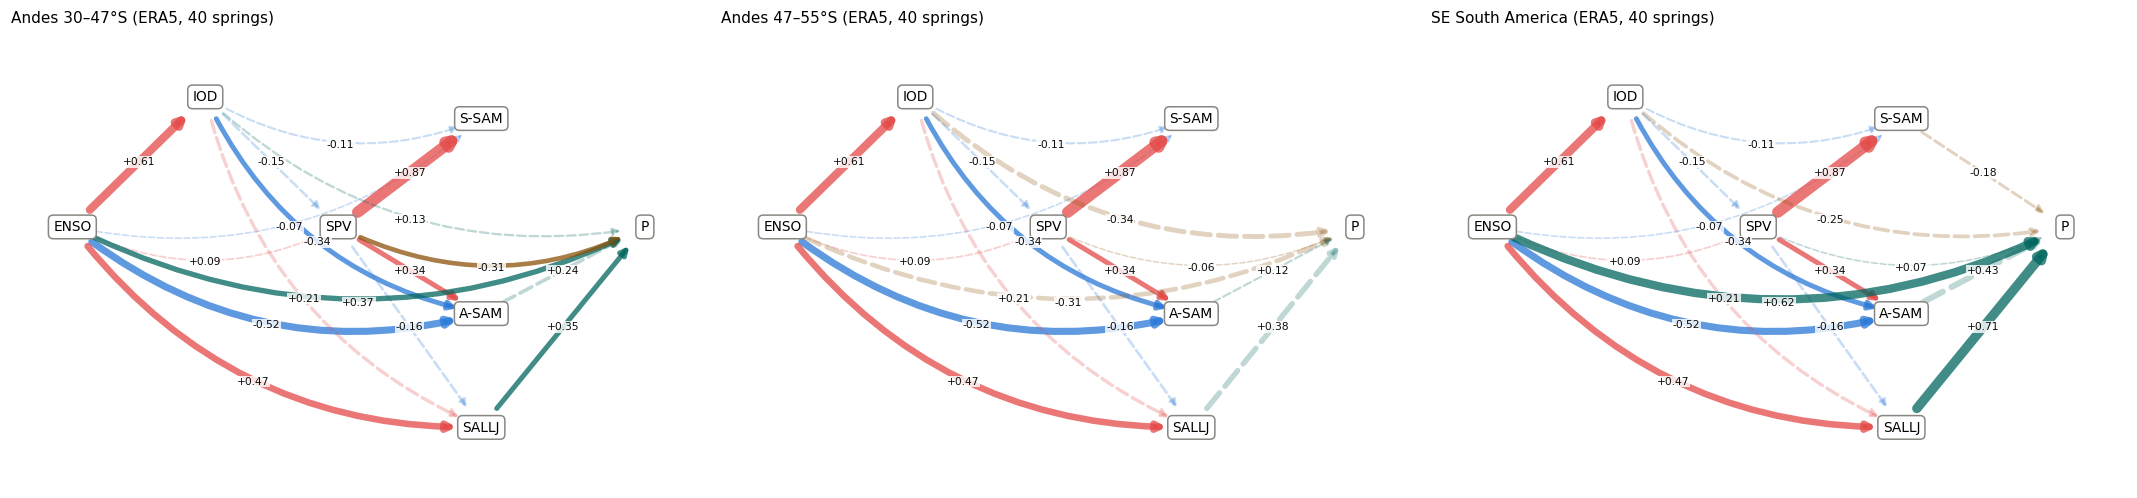

In [16]:
obs_sem = obs.dropna(subset=[f"{m}_z" for m in MEDS])
yrs_o = obs_sem.index.values
SEM_O, SIG_O = {}, {}
for r in REGIONS:
    SEM_O[r] = fit_sem(obs_sem, r)
    bo = np.array([fit_sem(obs_sem.iloc[RNG.integers(0, len(obs_sem), len(obs_sem))], r) for _ in range(1000)])
    lo, hi = np.percentile(bo, [5, 95], axis=0)
    SIG_O[r] = (lo > 0) | (hi < 0)
fig, axes = plt.subplots(1, NR, figsize=(6.5 * NR, 4.6))
for ax, r in zip(axes, REGIONS):
    draw_sem(ax, SEM_O[r], f"{REGIONS[r]['name']} (ERA5, {len(obs_sem)} springs)", sig=SIG_O[r])
fig.tight_layout(); savefig(fig, "fig08b_path_diagrams_era5")
cmp = {}
for r in REGIONS:
    for c in NODES:
        for p_ in PARENTS.get(c, []):
            i, j = NODES.index(c), NODES.index(p_)
            cmp[(r, f"{p_} → {c}")] = dict(SEAS5=SEM[r][i, j], SEAS5_sig90=SIG[r][i, j], ERA5=SEM_O[r][i, j],
                                              ERA5_sig90=SIG_O[r][i, j])
pd.DataFrame(cmp).T.unstack(0).round(2)

**ERA5 against SEAS5** (40 observed springs).

* **The mediator links agree.** The vortex sets S-SAM (SPV → S-SAM +0.87 in ERA5, +0.76 in SEAS5) and part of A-SAM (+0.34 / +0.37);
  ENSO sets A-SAM (−0.52 in both) and the IOD (+0.61 / +0.47). These are the arrows the mediation story rests on, and they are
  significant in ERA5. Two differences: in ERA5 the IOD also lowers A-SAM (−0.34, significant; −0.05 in SEAS5), and the vortex sets
  the SACZ (SPV → SACZ +0.41, significant; +0.05 in SEAS5).
* **The arrows into P are mostly not significant in ERA5.** With five correlated predictors and 40 springs, only ENSO → P (northern
  Andes +0.39, SESA +0.64) is significant. The SAM → P arrows (S-SAM ≈ 0; A-SAM −0.02 to −0.27) and SPV → P (northern Andes −0.28)
  are uncertain, so ERA5 alone can neither confirm nor reject the SAM mediation; the hindcast is what makes the decomposition possible.
* **Where they differ.** In the northern Andes ERA5 puts more of ENSO's effect on the direct arrow (+0.39 against +0.19). In the
  southern Andes ERA5 splits the El Niño drying between ENSO (−0.31) and the IOD (−0.35), neither significant: ENSO and IOD are
  correlated in observations (+0.61), and 40 springs cannot tell them apart. SEAS5 gives it to ENSO (−0.40). In SESA, ERA5 has IOD
  (−0.28) and A-SAM (−0.24) arrows that SEAS5 lacks, both not significant.
* **The SACZ.** In SEAS5 the drivers hardly set the SACZ (IOD → SACZ −0.22 and SPV → SACZ +0.05 are significant but small): it is
  mostly unforced. Its effect on P is significant in the northern Andes (−0.23: an active SACZ dries central Chile) and in SESA
  (−0.17: the SACZ–SESA seesaw), not in the southern Andes. In ERA5 none of the SACZ → P arrows is significant, and in SESA it has the
  opposite sign (+0.14): the SON seesaw seen in SEAS5 is not visible in 40 observed springs.

**Effects on precipitation, decomposed.** For each driver: direct, through S-SAM, through A-SAM, and through the other
drivers.
Bars: SEAS5 (90 % bootstrap interval over years); dots: the same path model fitted to ERA5 (40 springs, so
indicative only).

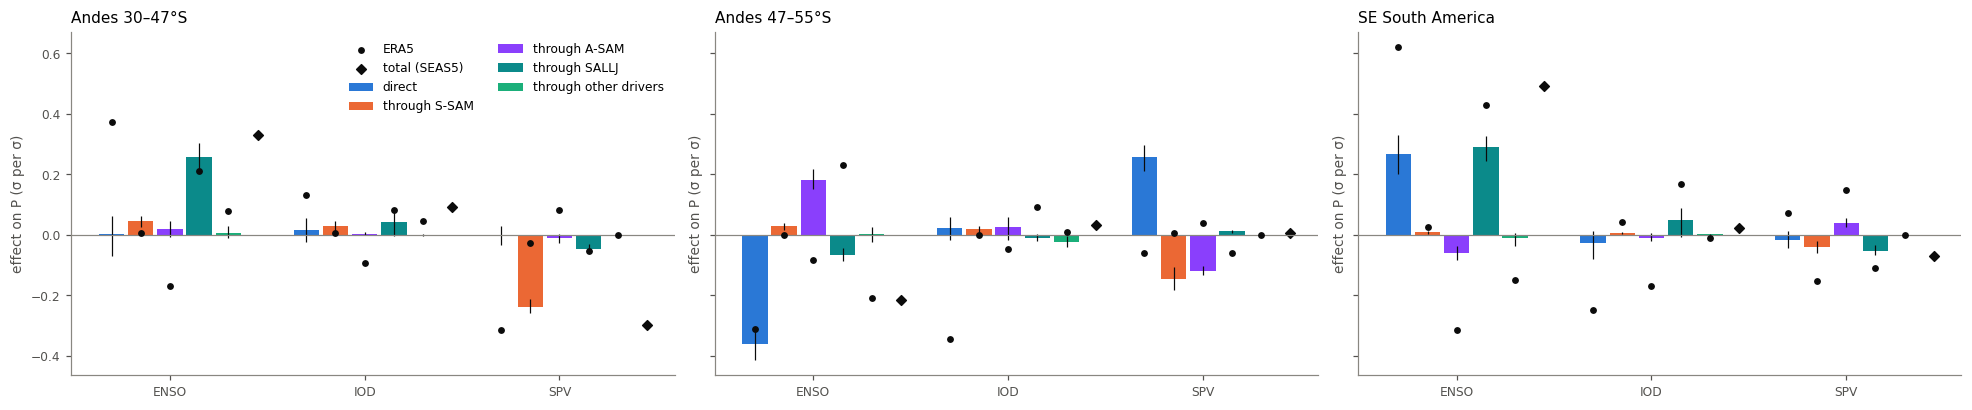

In [17]:
OBS_EFF = {r: effects(fit_sem(obs.dropna(subset=[f"{m}_z" for m in MEDS]), r)) for r in REGIONS}
fig, axes = plt.subplots(1, NR, figsize=(6 * NR, 3.8), sharey=True)
comp = ["direct", "via_S_SAM", "via_A_SAM", "via_SALLJ", "via_other_drivers"]
ccol = dict(direct="#2a78d6", via_S_SAM="#eb6834", via_A_SAM="#8a3ffc", via_SALLJ="#0b8a8a", via_other_drivers="#1baf7a")
clab = dict(direct="direct", via_S_SAM="through S-SAM", via_A_SAM="through A-SAM", via_SALLJ="through SALLJ",
            via_other_drivers="through other drivers")
for ax, r in zip(axes, REGIONS):
    e = EFF[r].loc[DRIVERS]
    x = np.arange(len(DRIVERS))
    for k, c in enumerate(comp):
        xx = x + (k - 2) * 0.15
        lo_hi = np.array([[float(v) for v in s.strip("[]").split(",")] for s in e[f"{c}_ci"]])
        ax.bar(xx, e[c], width=0.13, color=ccol[c], label=clab[c])
        ax.errorbar(xx, e[c], yerr=[e[c] - lo_hi[:, 0], lo_hi[:, 1] - e[c]], fmt="none", color=INK, lw=0.8)
        ax.scatter(xx, OBS_EFF[r].loc[DRIVERS, c], color=INK, s=12, zorder=3, label="ERA5" if k == 0 else None)
    ax.scatter(x + 0.45, e.total, marker="D", color=INK, s=20, label="total (SEAS5)")
    ax.axhline(0, color="#898781", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(DRIVERS); ax.set_title(REGIONS[r]["name"], loc="left")
    ax.set_ylabel("effect on P (σ per σ)")
axes[0].legend(ncol=2)
fig.tight_layout(); savefig(fig, "fig09_effects_decomposition")

## 6. Decomposing each storyline: direct, through the SAM, and the unforced SAM

With the fitted model, every spring's precipitation splits exactly into

$$P = \underbrace{\textstyle\sum_{X} e_X X}_{\text{direct (ENSO, IOD, SPV)}}
  + \underbrace{e_S \widehat{S}}_{\text{S-SAM forced}} + \underbrace{e_A \widehat{A}}_{\text{A-SAM forced}}
  + \underbrace{e_Z \widehat{Z}}_{\text{SACZ forced}}
  + \underbrace{e_S S^{\mathrm{res}}}_{\text{S-SAM unforced}} + \underbrace{e_A A^{\mathrm{res}}}_{\text{A-SAM unforced}}
  + \underbrace{e_Z Z^{\mathrm{res}}}_{\text{SACZ unforced}} + \varepsilon,$$

where $\widehat{S}, \widehat{A}, \widehat{Z}$ are the S-SAM, A-SAM and SACZ values predicted from ENSO, IOD and SPV and
$S^{\mathrm{res}}, A^{\mathrm{res}}, Z^{\mathrm{res}}$ the remainders. The three mediators are kept apart throughout. The storyline mean is the mean of each term over the storyline's springs. The unforced SAM term
need not average to zero in a storyline, because the quadrants are nonlinear selections (for example, the SAM response
to a weak vortex may be stronger than linear).

AndesN_direct  AndesN_S_SAM forced  \
phase   quad                                                    
El Niño IOD+ / strong SPV          0.018               -0.104   
        IOD+ / weak SPV            0.020                0.258   
        IOD− / strong SPV         -0.005               -0.130   
        IOD− / weak SPV           -0.003                0.198   
La Niña IOD+ / strong SPV          0.006               -0.214   
        IOD+ / weak SPV            0.010                0.219   
        IOD− / strong SPV         -0.017               -0.224   
        IOD− / weak SPV           -0.013                0.163   
Neutral IOD+ / strong SPV          0.013               -0.163   
        IOD+ / weak SPV            0.016                0.221   
        IOD− / strong SPV         -0.012               -0.170   
        IOD− / weak SPV           -0.010                0.194   

                           AndesN_A_SAM forced  AndesN_SALLJ forced  \
phase   quad                                                          
El Niño IOD+ / strong SPV                0.019                0.367   
        IOD+ / weak SPV                  0.037                0.440   
        IOD− / strong SPV                0.010                0.212   
        IOD− / weak SPV                  0.024                0.251   
La Niña IOD+ / strong SPV               -0.025               -0.246   
        IOD+ / weak SPV                 -0.004               -0.169   
        IOD− / strong SPV               -0.029               -0.328   
        IOD− / weak SPV                 -0.008               -0.235   
Neutral IOD+ / strong SPV               -0.005                0.029   
        IOD+ / weak SPV                  0.014                0.104   
        IOD− / strong SPV               -0.010               -0.077   
        IOD− / weak SPV                  0.008               -0.005   

                           AndesN_S_SAM unforced  AndesN_A_SAM unforced  \
phase   quad                                                              
El Niño IOD+ / strong SPV                 -0.012                 -0.001   
        IOD+ / weak SPV                    0.035                  0.001   
        IOD− / strong SPV                 -0.015                  0.003   
        IOD− / weak SPV                    0.049                  0.006   
La Niña IOD+ / strong SPV                  0.023                 -0.003   
        IOD+ / weak SPV                   -0.010                  0.002   
        IOD− / strong SPV                  0.011                 -0.000   
        IOD− / weak SPV                   -0.018                 -0.001   
Neutral IOD+ / strong SPV                 -0.003                  0.001   
        IOD+ / weak SPV                   -0.007                  0.000   
        IOD− / strong SPV                 -0.010                 -0.001   
        IOD− / weak SPV                   -0.003                  0.000   

                           AndesN_SALLJ unforced  AndesN_residual  \
phase   quad                                                        
El Niño IOD+ / strong SPV                  0.059            0.019   
        IOD+ / weak SPV                   -0.002           -0.011   
        IOD− / strong SPV                 -0.011           -0.087   
        IOD− / weak SPV                    0.012           -0.110   
La Niña IOD+ / strong SPV                 -0.009           -0.084   
        IOD+ / weak SPV                    0.036           -0.008   
        IOD− / strong SPV                  0.028            0.039   
        IOD− / weak SPV                    0.041            0.018   
Neutral IOD+ / strong SPV                 -0.013            0.002   
        IOD+ / weak SPV                   -0.028           -0.015   
        IOD− / strong SPV                 -0.037           -0.023   
        IOD− / weak SPV                   -0.030            0.042   

                           AndesS_direct  AndesS_S_SAM forced  ...  \
phase   quad                     

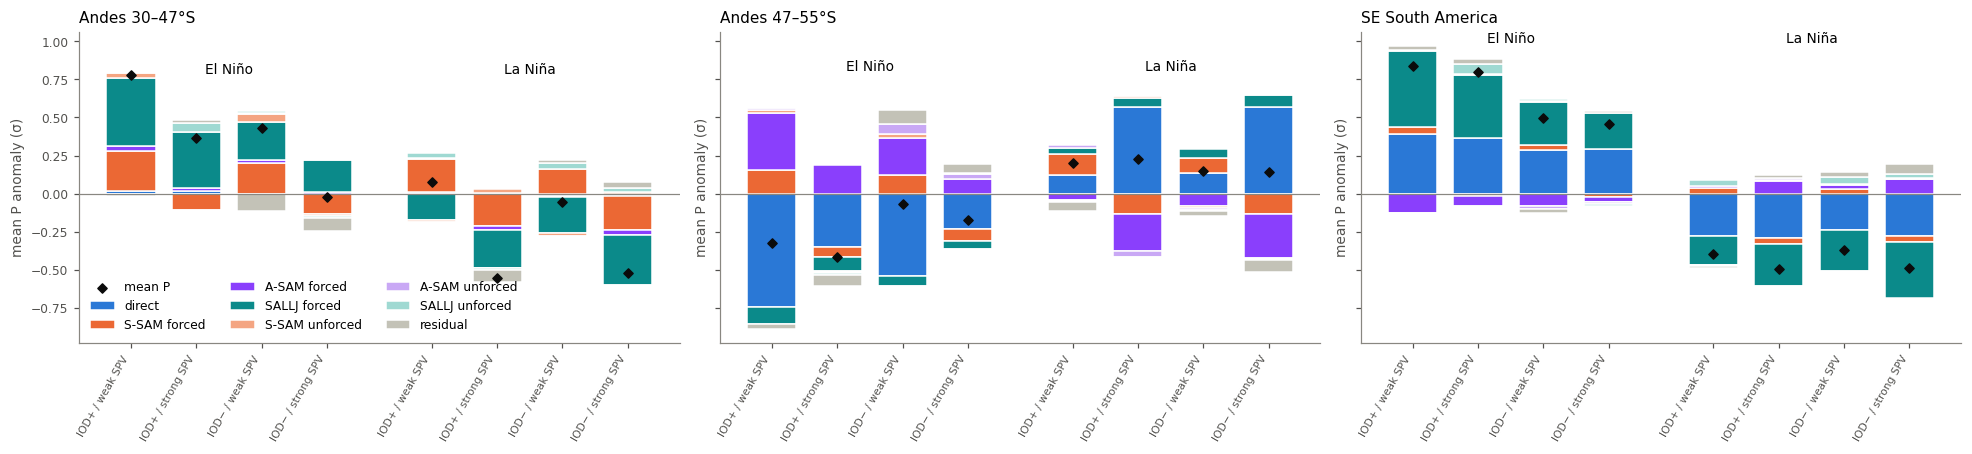

In [18]:
TERMS = ["direct"] + [f"{m} forced" for m in MEDS] + [f"{m} unforced" for m in MEDS] + ["residual"]
TCOL = {"direct": "#2a78d6", "S_SAM forced": "#eb6834", "A_SAM forced": "#8a3ffc", "SALLJ forced": "#0b8a8a",
        "S_SAM unforced": "#f4a582", "A_SAM unforced": "#c9a8f5", "SALLJ unforced": "#9fd9d2", "residual": "#c3c2b7"}


def add_terms(d, B, r, prefix=""):
    iP = NODES.index("P")
    dirc = sum(B[iP, NODES.index(x)] * d[f"{x}_z"] for x in DRIVERS)
    d[f"{r}_direct"] = dirc
    rest = d[f"P_{r}_z"] - dirc
    for s_ in MEDS:
        k = NODES.index(s_)
        hat = sum(B[k, NODES.index(x)] * d[f"{x}_z"] for x in DRIVERS)
        d[f"{s_}_res"] = d[f"{s_}_z"] - hat
        d[f"{r}_{s_} forced"] = B[iP, k] * hat
        d[f"{r}_{s_} unforced"] = B[iP, k] * d[f"{s_}_res"]
        rest = rest - d[f"{r}_{s_} forced"] - d[f"{r}_{s_} unforced"]
    d[f"{r}_residual"] = rest
    return d


for r in REGIONS:
    df = add_terms(df, SEM[r], r)
    obs = add_terms(obs, SEM[r], r)       # ERA5 decomposed with the SEAS5 coefficients

dec = df.groupby(["phase", "quad"])[[f"{r}_{t}" for r in REGIONS for t in TERMS]].mean()
fig, axes = plt.subplots(1, NR, figsize=(6 * NR, 4.2), sharey=True)
for ax, r in zip(axes, REGIONS):
    labels, x = [], 0
    for ph in PHASES:
        for q in QUADS:
            v = dec.loc[(ph, q), [f"{r}_{t}" for t in TERMS]].values
            pos, neg = 0, 0
            for t, val in zip(TERMS, v):
                base = pos if val >= 0 else neg
                ax.bar(x, val, bottom=base, color=TCOL[t], width=0.75, edgecolor="white", linewidth=1,
                       label=t.replace("_", "-") if x == 0 else None)
                if val >= 0:
                    pos += val
                else:
                    neg += val
            ax.scatter(x, v.sum(), color=INK, marker="D", s=18, zorder=3, label="mean P" if x == 0 else None)
            labels.append(f"{q}")
            x += 1
        x += 0.6
    ax.axhline(0, color="#898781", lw=0.8)
    ticks = list(range(4)) + [i + 4.6 for i in range(4)]
    ax.set_xticks(ticks); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.text(1.5, ax.get_ylim()[1], "El Niño", ha="center", va="top"); ax.text(6.1, ax.get_ylim()[1], "La Niña", ha="center", va="top")
    ax.set_title(REGIONS[r]["name"], loc="left"); ax.set_ylabel("mean P anomaly (σ)")
axes[0].legend(ncol=3, loc="lower left")
fig.tight_layout(); savefig(fig, "fig10_storyline_decomposition")
dec.round(3)

### Extra spring drying from the SAM that the drivers do not explain

For each storyline:

* **P(dry)**: as in Section 4;
and separately for **S-SAM** ($u = e_S S^{\mathrm{res}}$) and **A-SAM** ($u = e_A A^{\mathrm{res}}$):

* **P(dry) without the unforced S-SAM (A-SAM)**: the counterfactual $\tilde P = P - u$, with the dry threshold kept.
  The difference is the dry risk that comes from that SAM beyond what ENSO, IOD and SPV set;
* **P(dry | drying)** and **P(dry | wetting)**: the storyline split by the tercile of $u$ (lowest tercile = that SAM's
  residual dries);
* **share of dry springs with a drying $u$**, and the mean of $u$ in the dry springs (σ of P);
* **variance share**: the fraction of the precipitation variance *within the storyline* that $u$ explains.

In [19]:
def sam_drying_stats(d, r, s_):
    thr = df[f"P_{r}_z"].quantile(DRY_Q)
    u = d[f"{r}_{s_} unforced"]
    p_cf = d[f"P_{r}_z"] - u
    t1, t2 = df[f"{r}_{s_} unforced"].quantile([1 / 3, 2 / 3])
    dry = d[f"P_{r}_z"] < thr
    return dict(n=len(d), Pdry=dry.mean(), Pdry_no_unforced=(p_cf < thr).mean(),
                Pdry_drying=dry[u < t1].mean(), Pdry_wetting=dry[u > t2].mean(),
                share_dry_with_drying=(u[dry] < 0).mean(), mean_unforced_in_dry=u[dry].mean(),
                mean_res_in_dry=d.loc[dry, f"{s_}_res"].mean(),
                var_share_unforced=np.corrcoef(u, d[f"P_{r}_z"])[0, 1] ** 2)


samdry = {}
for r in REGIONS:
    for s_ in MEDS:
        samdry[(r, s_, "all springs", "")] = sam_drying_stats(df, r, s_)
        for ph in PHASES:
            samdry[(r, s_, ph, "whole phase")] = sam_drying_stats(df[df.phase == ph], r, s_)
            for q in QUADS:
                samdry[(r, s_, ph, q)] = sam_drying_stats(df[(df.phase == ph) & (df.quad == q)], r, s_)
samdry = pd.DataFrame(samdry).T
samdry["extra_Pdry_from_unforced"] = samdry.Pdry - samdry.Pdry_no_unforced
samdry.to_csv(OUT / "enso_sam_unforced_sam_drying.csv")
samdry[["n", "Pdry", "Pdry_no_unforced", "extra_Pdry_from_unforced", "Pdry_drying",
        "Pdry_wetting", "share_dry_with_drying", "var_share_unforced"]].astype(float).round(2)

n  Pdry  Pdry_no_unforced  \
AndesN S_SAM all springs                    3618.0  0.20              0.19   
             El Niño     whole phase         788.0  0.10              0.09   
                         IOD+ / weak SPV     275.0  0.04              0.04   
                         IOD+ / strong SPV   319.0  0.13              0.11   
                         IOD− / weak SPV      98.0  0.07              0.08   
...                                            ...   ...               ...   
SESA   SALLJ La Niña     whole phase        1064.0  0.33              0.30   
                         IOD+ / weak SPV     134.0  0.34              0.30   
                         IOD+ / strong SPV   119.0  0.38              0.29   
                         IOD− / weak SPV     313.0  0.29              0.29   
                         IOD− / strong SPV   498.0  0.33              0.32   

                                            extra_Pdry_from_unforced  \
AndesN S_SAM all springs                                        0.01   
             El Niño     whole phase                            0.01   
                         IOD+ / weak SPV                        0.00   
                         IOD+ / strong SPV                      0.02   
                         IOD− / weak SPV                       -0.01   
...                                                              ...   
SESA   SALLJ La Niña     whole phase                            0.02   
                         IOD+ / weak SPV                        0.04   
                         IOD+ / strong SPV                      0.08   
                         IOD− / weak SPV                        0.00   
                         IOD− / strong SPV                      0.01   

                                            Pdry_drying  Pdry_wetting  \
AndesN S_SAM all springs                           0.26          0.14   
             El Niño     whole phase               0.12          0.06   
                         IOD+ / weak SPV           0.03          0.03   
                         IOD+ / strong SPV         0.17          0.07   
                         IOD− / weak SPV           0.05          0.11   
...                                                 ...           ...   
SESA   SALLJ La Niña     whole phase               0.58          0.12   
                         IOD+ / weak SPV           0.60          0.13   
                         IOD+ / strong SPV         0.66          0.14   
                         IOD− / weak SPV           0.55          0.08   
                         IOD− / strong SPV         0.58          0.15   

                                            share_dry_with_drying  \
AndesN S_SAM all springs                                     0.64   
             El Niño     whole phase                         0.62   
                         IOD+ / weak SPV                     0.45   
                         IOD+ / strong SPV                   0.71   
                         IOD− / weak SPV                     0.29   
...                                                           ...   
SESA   SALLJ La Niña     whole phase                         0.71   
                         IOD+ / weak SPV                     0.62   
                         IOD+ / strong SPV                   0.73   
                         IOD− / weak SPV                     0.75   
                         IOD− / strong SPV                   0.70   

                                            var_share_unforced  
AndesN S_SAM all springs                                  0.04  
             El Niño     whole phase                      0.03  
                         IOD+ / weak SPV                  0.02  
                         IOD+ / strong SPV                0.03  
                         IOD− / weak SPV                  0.01  
...                                                        ...  
SESA   SALLJ La Niña     whole phase                      0.30  
                     

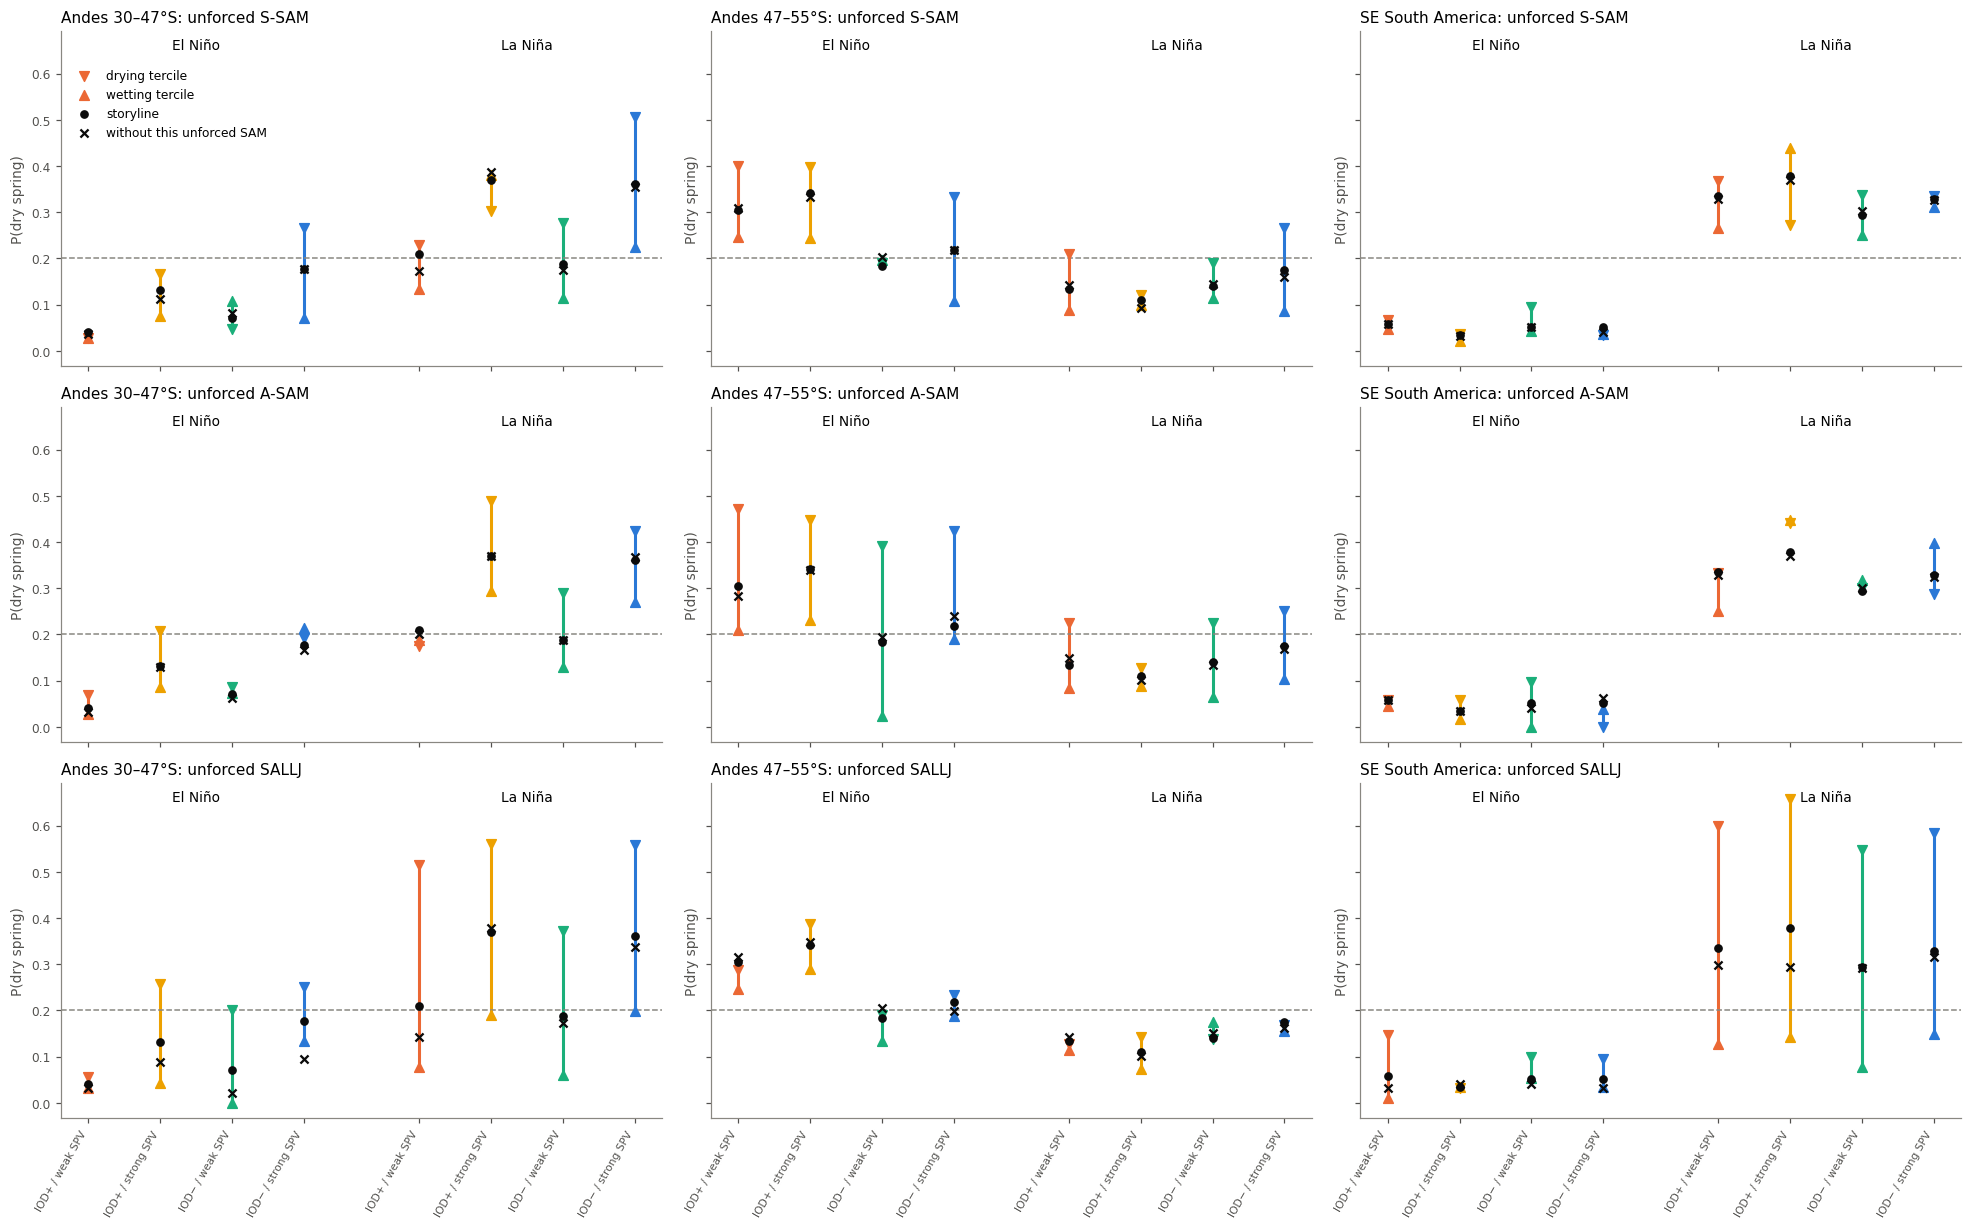

In [20]:
fig, axes = plt.subplots(len(MEDS), NR, figsize=(6 * NR, 3.75 * len(MEDS)), sharey=True, sharex=True)
for i, s_ in enumerate(MEDS):
    for ax, r in zip(axes[i], REGIONS):
        x = 0
        ticks, labs = [], []
        for ph in PHASES:
            for q in QUADS:
                st = samdry.loc[(r, s_, ph, q)]
                ax.vlines(x, st.Pdry_wetting, st.Pdry_drying, color=QCOL[q], lw=2)
                ax.scatter(x, st.Pdry_drying, marker="v", color=QCOL[q], s=40, zorder=3,
                           label="drying tercile" if x == 0 else None)
                ax.scatter(x, st.Pdry_wetting, marker="^", color=QCOL[q], s=40, zorder=3,
                           label="wetting tercile" if x == 0 else None)
                ax.scatter(x, st.Pdry, marker="o", color=INK, s=22, zorder=4, label="storyline" if x == 0 else None)
                ax.scatter(x, st.Pdry_no_unforced, marker="x", color=INK, s=28, zorder=4,
                           label="without this unforced SAM" if x == 0 else None)
                ticks.append(x); labs.append(q); x += 1
            x += 0.6
        ax.axhline(DRY_Q, color="#898781", ls="--", lw=1)
        ax.set_xticks(ticks); ax.set_xticklabels(labs, rotation=60, ha="right", fontsize=7)
        ax.text(1.5, 0.98, "El Niño", ha="center", va="top", transform=ax.get_xaxis_transform())
        ax.text(6.1, 0.98, "La Niña", ha="center", va="top", transform=ax.get_xaxis_transform())
        ax.set_title(f"{REGIONS[r]['name']}: unforced {s_.replace('_', '-')}", loc="left")
        ax.set_ylabel("P(dry spring)")
axes[0, 0].legend(loc="upper left", bbox_to_anchor=(0, 0.92))
fig.tight_layout(); savefig(fig, "fig11_unforced_sam_drying")

### Information carried by each pathway

Mutual information in bits, with the Gaussian-copula estimator (Ince et al. 2017: every variable is
rank-transformed to a standard normal, then the Gaussian formula is used; a lower bound that is robust to the skewed
precipitation). With D = (ENSO, IOD, SPV) and M = (S-SAM, A-SAM, SACZ):

| quantity | meaning |
|---|---|
| $I(P;D)$ | information on P from the large-scale drivers (all pathways) |
| $I(P;M\mid D)$ | information from the mediators that the drivers do not carry (**unforced** SAM and SACZ) |
| $I(P;M_k\mid D)$ | the same for each mediator alone |
| $I(P;M_k\mid D, M_{-k})$ | what each mediator adds beyond the drivers and the other mediators (unique) |
| $I(P;D,M) = I(P;D) + I(P;M\mid D)$ | everything (chain rule) |

The chain rule splits $I(P;M\mid D)$ differently for every order of the mediators. The unforced share of each mediator is the
average over all 6 orders (a Shapley value), so the three add up exactly to $I(P;M\mid D)$ without favouring any of them.

**Splitting $I(P;D)$ into direct and through-SAM.** The obvious candidate, $I(P;D) - I(P;D\mid M)$, is *not*
a mediation measure here: A-SAM is strongly correlated with ENSO, so conditioning on it removes ENSO information even where
the SAM has no effect on P (in SESA this co-information is about 40 % although the path through the SAM is about 0). Instead,
$I(P;D)$ is split in proportion to each pathway's share of the driver-predicted precipitation
$\hat P_D = \hat P_{\mathrm{direct}} + \hat P_{S} + \hat P_{A}$ (Section 6: $\hat P_S = e_S\widehat{S}$, $\hat P_A = e_A\widehat{A}$),
with share $\mathrm{Cov}(\hat P_k, \hat P_D)/\mathrm{Var}(\hat P_D)$. The shares add up to 1; a negative share means the
pathway works against the others.

For each driver X, with U its upstream drivers (none for ENSO; ENSO for IOD; ENSO and IOD for SPV):
total $I(P;X\mid U)$, split by the **proportion mediated by S-SAM** and **by A-SAM** (through-S-SAM effect / total
effect, and the same for A-SAM; Section 5); the rest is not through the SAM. When the pathways have opposite signs
(inconsistent mediation), a proportion lies outside [0, 1].
90 % bootstrap intervals over years. For reference, a correlation of 0.3 is 0.07 bits and 0.5 is 0.21 bits.

In [21]:
def copnorm(x):
    return stats.norm.ppf((stats.rankdata(x) - 0.5) / len(x))


def gauss_mi(x, y, z=None):
    """I(x; y | z) in bits for 2-D arrays (n, k), Gaussian."""
    def ld(*a):
        m = np.column_stack(a)
        return np.linalg.slogdet(np.atleast_2d(np.cov(m, rowvar=False)))[1]
    if z is None:
        return 0.5 * (ld(x) + ld(y) - ld(x, y)) / np.log(2)
    return 0.5 * (ld(x, z) + ld(y, z) - ld(z) - ld(x, y, z)) / np.log(2)


def info_table(d, r):
    c = {v: copnorm(d[f"{v}_z"].values)[:, None] for v in DRIVERS + MEDS}
    P = copnorm(d[f"P_{r}_z"].values)[:, None]
    D = np.hstack([c[v] for v in DRIVERS]); M = np.hstack([c[v] for v in MEDS])
    i_d = gauss_mi(P, D)
    # pathway shares of the driver-predicted precipitation, from the path model fitted on the same springs
    B = fit_sem(d, r)
    iP = NODES.index("P")
    parts = {"direct": sum(B[iP, NODES.index(x)] * d[f"{x}_z"].values for x in DRIVERS)}
    for k in MEDS:
        parts[k] = B[iP, NODES.index(k)] * sum(B[NODES.index(k), NODES.index(x)] * d[f"{x}_z"].values for x in DRIVERS)
    p_d = sum(parts.values())
    sh = {k: np.cov(v, p_d)[0, 1] / p_d.var(ddof=1) for k, v in parts.items()}
    i_m = gauss_mi(P, M, D)
    out = {"I(P;D) all drivers": i_d, "  direct pathway": i_d * sh["direct"]}
    for k in MEDS:
        out[f"  through {k.replace('_', '-')}"] = i_d * sh[k]
    out["I(P;M|D) unforced mediators"] = i_m
    # Shapley split of I(P;M|D): average over all orderings of the mediators of what each adds
    orders = list(itertools.permutations(MEDS))
    for k in MEDS:
        val = 0.0
        for o in orders:
            before = list(o[:o.index(k)])
            cond = np.hstack([D] + [c[v] for v in before])
            val += gauss_mi(P, c[k], cond)
        out[f"  unforced {k.replace('_', '-')} (order average)"] = val / len(orders)
    for k in MEDS:
        others = [v for v in MEDS if v != k]
        out[f"I(P;{k}|D)"] = gauss_mi(P, c[k], D)
        out[f"I(P;{k}|D,other mediators) unique"] = gauss_mi(P, c[k], np.hstack([D] + [c[v] for v in others]))
    out["I(P;D,M) total"] = gauss_mi(P, np.hstack([D, M]))
    e = effects(B)
    ups = {"ENSO": [], "IOD": ["ENSO"], "SPV": ["ENSO", "IOD"]}
    for x, u in ups.items():
        tot = gauss_mi(P, c[x], np.hstack([c[v] for v in u]) if u else None)
        out[f"{x}: total"] = tot
        rest = 1.0
        for k in MEDS:
            pk = e.loc[x, f"via_{k}"] / e.loc[x, "total"]
            out[f"{x}: proportion mediated by {k.replace('_', '-')}"] = pk
            out[f"{x}: through {k.replace('_', '-')}"] = tot * pk
            rest -= pk
        out[f"{x}: not through a mediator"] = tot * rest
    return out


INFO = {}
for r in REGIONS:
    est = pd.Series(info_table(df, r))
    boots = pd.DataFrame([info_table(df.iloc[ix], r) for ix in BOOT_IDX[:200]])
    INFO[r] = pd.DataFrame({"bits": est, "lo": boots.quantile(0.05), "hi": boots.quantile(0.95)})
    INFO[r]["fraction_of_I(P;D,M)"] = (est / est["I(P;D,M) total"]).where(~est.index.str.contains("proportion"))
info = pd.concat(INFO, axis=1)
info.to_csv(OUT / "enso_sam_information_pathways.csv")
info.round(3)

AndesN                                     \
                                      bits     lo     hi fraction_of_I(P;D,M)   
I(P;D) all drivers                   0.156  0.118  0.197                0.383   
  direct pathway                     0.004 -0.015  0.024                0.009   
  through S-SAM                      0.067  0.057  0.077                0.164   
  through A-SAM                      0.007 -0.002  0.016                0.018   
  through SALLJ                      0.078  0.052  0.110                0.192   
I(P;M|D) unforced mediators          0.251  0.223  0.281                0.617   
  unforced S-SAM (order average)     0.045  0.037  0.052                0.110   
  unforced A-SAM (order average)     0.016  0.011  0.023                0.040   
  unforced SALLJ (order average)     0.190  0.162  0.217                0.467   
I(P;S_SAM|D)                         0.042  0.033  0.051                0.104   
I(P;S_SAM|D,other mediators) unique  0.049  0.041  0.056                0.120   
I(P;A_SAM|D)                         0.033  0.023  0.044                0.081   
I(P;A_SAM|D,other mediators) unique  0.001  0.000  0.005                0.003   
I(P;SALLJ|D)                         0.197  0.171  0.225                0.483   
I(P;SALLJ|D,other mediators) unique  0.186  0.157  0.212                0.456   
I(P;D,M) total                       0.407  0.362  0.456                1.000   
ENSO: total                          0.076  0.042  0.112                0.187   
ENSO: proportion mediated by S-SAM   0.138  0.090  0.195                  NaN   
ENSO: through S-SAM                  0.011  0.005  0.017                0.026   
ENSO: proportion mediated by A-SAM   0.055 -0.015  0.162                  NaN   
ENSO: through A-SAM                  0.004 -0.001  0.009                0.010   
ENSO: proportion mediated by SALLJ   0.778  0.651  0.976                  NaN   
ENSO: through SALLJ                  0.059  0.033  0.087                0.146   
ENSO: not through a mediator         0.002 -0.013  0.016                0.006   
IOD: total                           0.005  0.001  0.013                0.013   
IOD: proportion mediated by S-SAM    0.327  0.133  0.595                  NaN   
IOD: through S-SAM                   0.002  0.000  0.004                0.004   
IOD: proportion mediated by A-SAM    0.030 -0.026  0.101                  NaN   
IOD: through A-SAM                   0.000 -0.000  0.001                0.000   
IOD: proportion mediated by SALLJ    0.476 -0.125  0.827                  NaN   
IOD: through SALLJ                   0.003 -0.000  0.007                0.006   
IOD: not through a mediator          0.001 -0.001  0.004                0.002   
SPV: total                           0.074  0.061  0.089                0.183   
SPV: proportion mediated by S-SAM    0.799  0.712  0.881                  NaN   
SPV: through S-SAM                   0.059  0.050  0.069                0.146   
SPV: proportion mediated by A-SAM    0.040 -0.011  0.101                  NaN   
SPV: through A-SAM                   0.003 -0.001  0.007                0.007   
SPV: proportion mediated by SALLJ    0.157  0.107  0.201                  NaN   
SPV: through SALLJ                   0.012  0.008  0.016                0.029   
SPV: not through a mediator          0.000 -0.007  0.008                0.001   

                                     AndesS                   \
                                       bits      lo       hi   
I(P;D) all drivers                    0.031   0.013    0.058   
  direct pathway                      0.051   0.027    0.082   
  through S-SAM                      -0.004  -0.007   -0.001   
  through A-SAM                      -0.025  -0.036   -0.015   
  through SALLJ                       0.009   0.004    0.015   
I(P;M|D) unforced mediators           0.061   0.049    0.075   
  unforced S-SAM (order average)      0.017   0.011    0.024   
  unforced A-SAM (order average)      0.038   0.027    0.

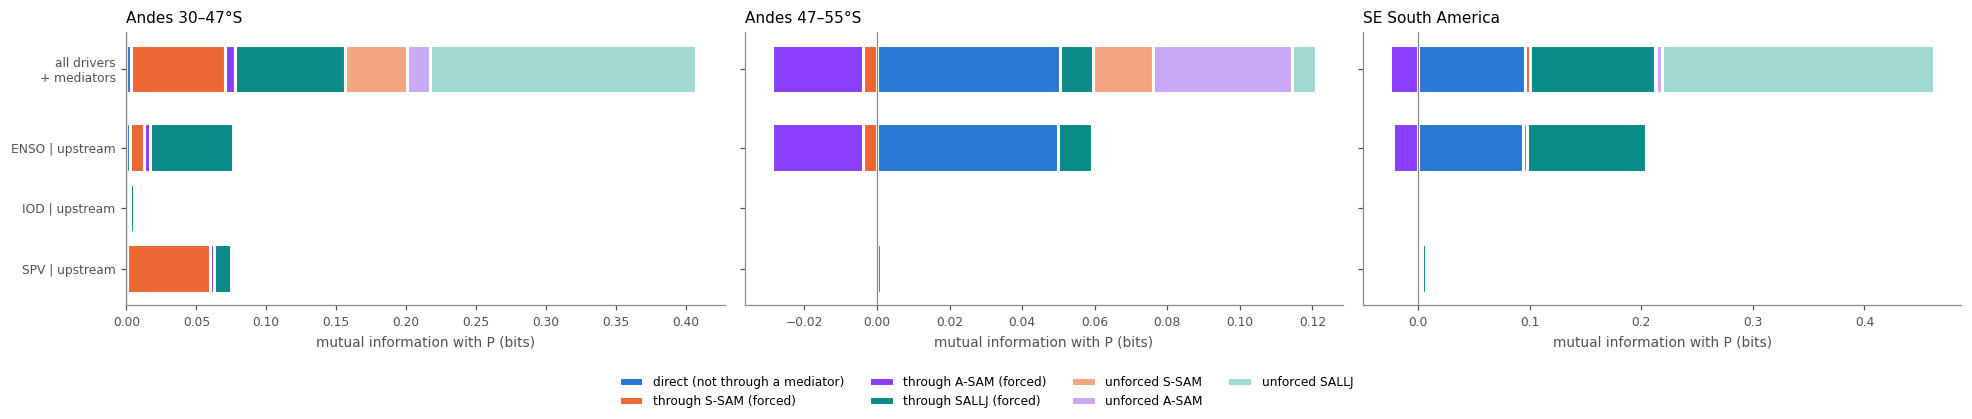

In [22]:
fig, axes = plt.subplots(1, NR, figsize=(6 * NR, 3.8), sharey=True)
for ax, r in zip(axes, REGIONS):
    t = INFO[r]["bits"]
    cols = ["#2a78d6", "#eb6834", "#8a3ffc", "#0b8a8a", "#f4a582", "#c9a8f5", "#9fd9d2"]

    def hbar(yy, parts):
        pos, neg = 0.0, 0.0
        for (lab, v), c in zip(parts, cols):
            ax.barh(yy, v, left=pos if v >= 0 else neg, color=c, edgecolor="white", linewidth=2,
                    label=lab if yy == 0 else None)
            pos, neg = (pos + v, neg) if v >= 0 else (pos, neg + v)

    ML = [m.replace("_", "-") for m in MEDS]
    hbar(0, [("direct (not through a mediator)", t["  direct pathway"])]
         + [(f"through {m} (forced)", t[f"  through {m}"]) for m in ML]
         + [(f"unforced {m}", t[f"  unforced {m} (order average)"]) for m in ML])
    for k, x in enumerate(DRIVERS):
        hbar(k + 1.3, [("", t[f"{x}: not through a mediator"])] + [("", t[f"{x}: through {m}"]) for m in ML])
    ax.axvline(0, color="#898781", lw=0.8)
    ax.set_yticks([0] + [k + 1.3 for k in range(3)])
    ax.set_yticklabels(["all drivers\n+ mediators"] + [f"{x} | upstream" for x in DRIVERS])
    ax.set_xlabel("mutual information with P (bits)"); ax.set_title(REGIONS[r]["name"], loc="left")
    ax.invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4)
fig.tight_layout(rect=(0, 0.12, 1, 1)); savefig(fig, "fig12_information_pathways")

## 7. Sensitivity checks

1. Path model fitted **within each ENSO phase** and **for each init month** (does the mediation hold across leads
   and phases?).
2. Storylines with a **±0.5σ dead zone** for IOD and SPV (springs near zero left out).
3. **Gong–Wang SAM** in place of S-SAM (A-SAM left out): the through-SAM share.

In [23]:
sens = {}
for r in REGIONS:
    for lab, d in [("pooled", df)] + [(ph, df[df.phase == ph]) for ph in PHASES] + \
                  [(f"init {m}", df.xs(m, level="init_month", drop_level=False)) for m in INITS]:
        e = effects(fit_sem(d, r))
        for x in DRIVERS:
            sens[(r, lab, x)] = e.loc[x, ECOLS]
sens = pd.DataFrame(sens).T
sens.unstack(2).round(2)

direct             via_S_SAM             via_A_SAM              \
                 ENSO   IOD   SPV      ENSO   IOD   SPV      ENSO   IOD   SPV   
AndesN El Niño   0.08  0.07 -0.03      0.02  0.03 -0.25     -0.00 -0.00  0.01   
       La Niña  -0.01 -0.03  0.01      0.08  0.07 -0.22      0.04  0.01 -0.02   
       init 6   -0.00  0.04 -0.01      0.05  0.02 -0.26      0.02  0.00 -0.01   
       init 7    0.00  0.02  0.05      0.04  0.02 -0.24      0.04  0.01 -0.03   
       init 8    0.01 -0.02 -0.05      0.04  0.05 -0.21     -0.01 -0.00  0.00   
       pooled    0.00  0.02 -0.00      0.05  0.03 -0.24      0.02  0.00 -0.01   
AndesS El Niño  -0.54  0.04  0.19      0.01  0.01 -0.12      0.07  0.00 -0.10   
       La Niña  -0.25  0.04  0.29      0.05  0.05 -0.15      0.18  0.05 -0.12   
       init 6   -0.31 -0.01  0.28      0.03  0.01 -0.17      0.17  0.01 -0.12   
       init 7   -0.32  0.00  0.24      0.02  0.01 -0.12      0.20  0.04 -0.13   
       init 8   -0.45  0.08  0.25      0.03  0.03 -0.14      0.18  0.03 -0.11   
       pooled   -0.36  0.02  0.26      0.03  0.02 -0.15      0.18  0.03 -0.12   
SESA   El Niño   0.48 -0.09 -0.05      0.00  0.00 -0.03     -0.02 -0.00  0.04   
       La Niña   0.15 -0.06  0.05      0.03  0.02 -0.08     -0.04 -0.01  0.03   
       init 6    0.27 -0.06 -0.05      0.00  0.00 -0.01     -0.05 -0.00  0.03   
       init 7    0.30 -0.04 -0.00      0.01  0.00 -0.04     -0.06 -0.01  0.04   
       init 8    0.23  0.03  0.01      0.02  0.02 -0.07     -0.07 -0.01  0.04   
       pooled    0.27 -0.03 -0.02      0.01  0.01 -0.04     -0.06 -0.01  0.04   

               via_SALLJ  ...       via_SAM             via_other_drivers  \
                    ENSO  ...   SPV    ENSO   IOD   SPV              ENSO   
AndesN El Niño      0.37  ... -0.01    0.01  0.03 -0.24              0.05   
       La Niña      0.15  ... -0.06    0.12  0.08 -0.24             -0.01   
       init 6       0.25  ... -0.05    0.07  0.02 -0.28              0.02   
       init 7       0.26  ... -0.05    0.08  0.03 -0.27              0.01   
       init 8       0.27  ... -0.04    0.04  0.05 -0.20             -0.00   
       pooled       0.26  ... -0.05    0.06  0.03 -0.25              0.01   
AndesS El Niño     -0.08  ...  0.00    0.08  0.01 -0.22              0.03   
       La Niña     -0.03  ...  0.01    0.23  0.10 -0.27             -0.03   
       init 6      -0.08  ...  0.02    0.20  0.02 -0.29             -0.01   
       init 7      -0.08  ...  0.02    0.22  0.05 -0.25             -0.00   
       init 8      -0.04  ...  0.01    0.21  0.07 -0.25              0.02   
       pooled      -0.07  ...  0.01    0.21  0.05 -0.26              0.00   
SESA   El Niño      0.29  ... -0.01   -0.02  0.00  0.01             -0.06   
       La Niña      0.21  ... -0.09   -0.02  0.01 -0.05             -0.02   
       init 6       0.30  ... -0.06   -0.05 -0.00  0.02             -0.02   
       init 7       0.29  ... -0.05   -0.06 -0.01 -0.00             -0.02   
       init 8       0.28  ... -0.04   -0.05  0.00 -0.03              0.01   
       pooled       0.29  ... -0.05   -0.05 -0.00 -0.00             -0.01   

                          total              
                 IOD  SPV  ENSO   IOD   SPV  
AndesN El Niño  0.00  0.0  0.50  0.11 -0.28  
       La Niña -0.00  0.0  0.25  0.09 -0.30  
       init 6   0.00  0.0  0.34  0.08 -0.33  
       init 7  -0.00  0.0  0.35  0.08 -0.27  
       init 8   0.01  0.0  0.31  0.11 -0.29  
       pooled   0.00  0.0  0.33  0.09 -0.30  
AndesS El Niño -0.01  0.0 -0.51  0.03 -0.03  
       La Niña -0.08  0.0 -0.08  0.06  0.04  
       init 6  -0.02  0.0 -0.20 -0.01  0.01  
       init 7  -0.01  0.0 -0.19  0.02  0.01  
       init 8  -0.05  0.0 -0.26  0.09  0.00  
       pooled  -0.03  0.0 -0.22  0.03  0.00  
SESA   El Niño  0.00  0.0  0.69 -0.08 -0.05  
       La Niña -0.01  0.0  0.32 -0.01 -0.09  
       init 6   0.00  0.0  0.49 -0.03 -0.09  
       init 7   0.00  0.0  0.51 -0.00 -0.06  
       init 8  -0.00  0.0

In [24]:
dz = df[(df.IOD_z.abs() > 0.5) & (df.SPV_z.abs() > 0.5)]
dz_tab = dz.groupby(["phase", "quad"])[[f"dry_{r}" for r in REGIONS]].agg(["mean", "size"]).loc[PHASES]
dz_tab.round(2)

dry_AndesN      dry_AndesS      dry_SESA     
                                mean size       mean size     mean size
phase   quad                                                           
El Niño IOD+ / strong SPV       0.15  120       0.38  120     0.01  120
        IOD+ / weak SPV         0.05  125       0.37  125     0.06  125
        IOD− / strong SPV       0.23   30       0.23   30     0.07   30
        IOD− / weak SPV         0.00   17       0.12   17     0.00   17
La Niña IOD+ / strong SPV       0.37   38       0.11   38     0.34   38
        IOD+ / weak SPV         0.19   54       0.15   54     0.20   54
        IOD− / strong SPV       0.43  263       0.17  263     0.35  263
        IOD− / weak SPV         0.16  128       0.14  128     0.29  128

In [25]:
NODES_GW = DRIVERS + ["SAM_GW", "P"]
save = (NODES, SAMS, PARENTS)
NODES, SAMS = NODES_GW, ["SAM_GW"]                  # SACZ left out here: only the SAM index is swapped
PARENTS = {"IOD": ["ENSO"], "SPV": ["ENSO", "IOD"], "SAM_GW": ["ENSO", "IOD", "SPV"],
           "P": ["ENSO", "IOD", "SPV", "SAM_GW"]}
gw = {r: effects(fit_sem(df, r)).loc[DRIVERS] for r in REGIONS}
NODES, SAMS, PARENTS = save
pd.concat(gw, axis=1).round(3)

AndesN                                             AndesS             \
     direct via_SAM_GW via_SAM via_other_drivers  total direct via_SAM_GW   
ENSO  0.230      0.070   0.070             0.031  0.331 -0.269      0.042   
IOD   0.063      0.025   0.025             0.004  0.091  0.032      0.015   
SPV  -0.038     -0.260  -0.260             0.000 -0.298  0.161     -0.157   

                                        SESA                     \
     via_SAM via_other_drivers  total direct via_SAM_GW via_SAM   
ENSO   0.042             0.009 -0.217  0.482      0.000   0.000   
IOD    0.015            -0.016  0.031  0.014      0.000   0.000   
SPV   -0.157             0.000  0.004 -0.070     -0.001  -0.001   

                               
     via_other_drivers  total  
ENSO             0.009  0.491  
IOD              0.007  0.021  
SPV              0.000 -0.071

## 8. Forecast mode: what does one forecast say about the storylines?

Sections 4–7 pool all hindcast springs. Here each **forecast** (one year, one init month, 25 or 51 members) is used on
its own, with three questions:

1. **With 4 months lead (init June; SON = lead months 4–6), can we already see which storylines are possible,
   and can we discard some?**
2. **Was the observed spring one of the plausible storylines, even when the ensemble mean was poor?**
3. **When the observed spring was not among the plausible storylines, was one of the drivers poorly predicted?**

**Definitions.**
* 12 storylines: ENSO phase (El Niño, Neutral, La Niña) × the 4 IOD–SPV quadrants. A member's storyline is set
  by its SON drivers; the observed storyline by RONI, the ERSST DMI and the ERA5 SPV, with the same thresholds.
* Storyline probability = fraction of the forecast's members in it. **Plausible** = at least `MIN_FRAC` = 8 % of the members
  (2 of 25, 5 of 51); **discarded** = fewer. (With 1 member as the threshold, see the sensitivity line.)
* Baselines: (i) the **ensemble-mean storyline** (the storyline of the ensemble-mean drivers); (ii) a
  **climatological set**: the same number of storylines, the most frequent ones over all years for that init month.
  A useful forecast set must contain the observed storyline more often than the climatological set of the same size.
* Observations are put in the model's units: the observed detrended anomaly divided by the model's standard deviation
  (ENSO, IOD, SPV, precipitation; for S-SAM and A-SAM the observed standardised value is used).

In [26]:
PH3 = ["El Niño", "Neutral", "La Niña"]
STORIES = [f"{p} | {q}" for p in PH3 for q in QUADS]
df["story"] = df.phase + " | " + df.quad
obs["story"] = obs.phase + " | " + obs.quad


def detrended(x, yrs):
    ok = np.isfinite(x)
    return x - np.polyval(np.polyfit(yrs[ok], x[ok], 1), yrs)


# model standard deviation of the detrended anomaly, per init month
SDM = {v: df.groupby("init_month").apply(
    lambda g: np.std(detrended(g[v].values, g.index.get_level_values("year").values)))
    for v in DRIVERS + [f"P_{r}_sc" for r in REGIONS]}
oyrs = obs.index.values.astype(float)
obs_mz = {m: pd.DataFrame({**{f"{v}_z": detrended(obs[v].values, oyrs) / SDM[v][m] for v in DRIVERS},
                           **{f"P_{r}_z": detrended(obs[f"P_{r}"].values, oyrs) / SDM[f"P_{r}_sc"][m]
                              for r in REGIONS},
                           **{f"{s_}_z": obs[f"{s_}_z"].values for s_ in MEDS}}, index=obs.index)
          for m in INITS}

cnt = (df.groupby(["year", "init_month"]).story.value_counts().unstack(fill_value=0)
       .reindex(columns=STORIES, fill_value=0))
clim_prob = cnt.groupby("init_month").sum().div(cnt.groupby("init_month").sum().sum(axis=1), axis=0)


def classify(enso_k, iod, spv):
    ph = "El Niño" if enso_k > ENSO_THR else ("La Niña" if enso_k < -ENSO_THR else "Neutral")
    q = QUADS[[(iod >= 0) and (spv < 0), (iod >= 0) and (spv >= 0), (iod < 0) and (spv < 0), True].index(True)]
    return f"{ph} | {q}"


rows = []
for (y, m), d in df.groupby(["year", "init_month"]):
    c = cnt.loc[(y, m)]
    so = obs.loc[y, "story"]
    plaus = c[c / c.sum() >= MIN_FRAC].index
    clim_set = clim_prob.loc[m].nlargest(len(plaus)).index
    em = d[["ENSO", "IOD_z", "SPV_z"]].mean()
    om = obs_mz[m].loc[y]
    row = dict(year=y, init_month=m, obs_story=so, n_obs_story=c[so], n_plausible=len(plaus),
               hit=so in plaus, hit_1member=c[so] >= 1, hit_clim=so in clim_set,
               em_story=classify(em.ENSO, em.IOD_z, em.SPV_z),
               frac_ENSO=(d.phase == obs.loc[y, "phase"]).mean(),
               frac_IOD=((d.IOD_z >= 0) == (obs.loc[y, "IOD_z"] >= 0)).mean(),
               frac_SPV=((d.SPV_z >= 0) == (obs.loc[y, "SPV_z"] >= 0)).mean())
    row["em_hit"] = row["em_story"] == so
    ins = d[d.story == so]
    for r in REGIONS:
        p, o = d[f"P_{r}_z"].values, om[f"P_{r}_z"]
        row[f"{r}_obs"], row[f"{r}_em"], row[f"{r}_sd"] = o, p.mean(), p.std()
        row[f"{r}_pct"] = stats.percentileofscore(p, o)
        row[f"{r}_em_err"] = abs(o - p.mean())
        if len(ins) / len(d) >= MIN_FRAC:
            ps = ins[f"P_{r}_z"].values
            row[f"{r}_story_err"] = abs(o - ps.mean())
            # same-size random subsets: the gain any sub-ensemble gets by being smaller
            rs = np.array([p[RNG.choice(len(p), len(ps), replace=False)].mean() for _ in range(200)])
            row[f"{r}_random_err"] = np.mean(np.abs(o - rs))
            row[f"{r}_in_story_range"] = ps.min() <= o <= ps.max()
        row[f"{r}_in_range"] = 5 <= row[f"{r}_pct"] <= 95
    rows.append(row)
F = pd.DataFrame(rows).set_index(["year", "init_month"])
F.to_csv(OUT / "enso_sam_forecast_mode.csv")
F[["obs_story", "n_obs_story", "n_plausible", "hit", "hit_clim", "em_story", "em_hit"]].xs(6, level="init_month")

,obs_story,n_obs_story,n_plausible,hit,hit_clim,em_story,em_hit
year,,,,,,,
1981,Neutral | IOD− / strong SPV,9,4,True,True,Neutral | IOD− / strong SPV,True
1982,El Niño | IOD+ / weak SPV,7,3,True,False,El Niño | IOD+ / strong SPV,False
1983,La Niña | IOD+ / weak SPV,0,6,False,False,Neutral | IOD− / strong SPV,False
1984,La Niña | IOD− / strong SPV,10,4,True,True,La Niña | IOD− / weak SPV,False
1985,Neutral | IOD+ / strong SPV,0,2,False,False,Neutral | IOD− / weak SPV,False
1986,El Niño | IOD+ / weak SPV,4,6,True,False,El Niño | IOD+ / weak SPV,True
1987,El Niño | IOD+ / strong SPV,2,5,True,False,Neutral | IOD+ / weak SPV,False
1988,La Niña | IOD− / weak SPV,8,4,True,False,La Niña | IOD− / weak SPV,True
1989,Neutral | IOD− / strong SPV,7,4,True,True,Neutral | IOD− / strong SPV,True


### 8.1 With 4 months lead, which storylines are possible?

Storyline probabilities for every June forecast (rows = years); the observed storyline is outlined.
Cells left white are discarded storylines (fewer than 8 % of the members).

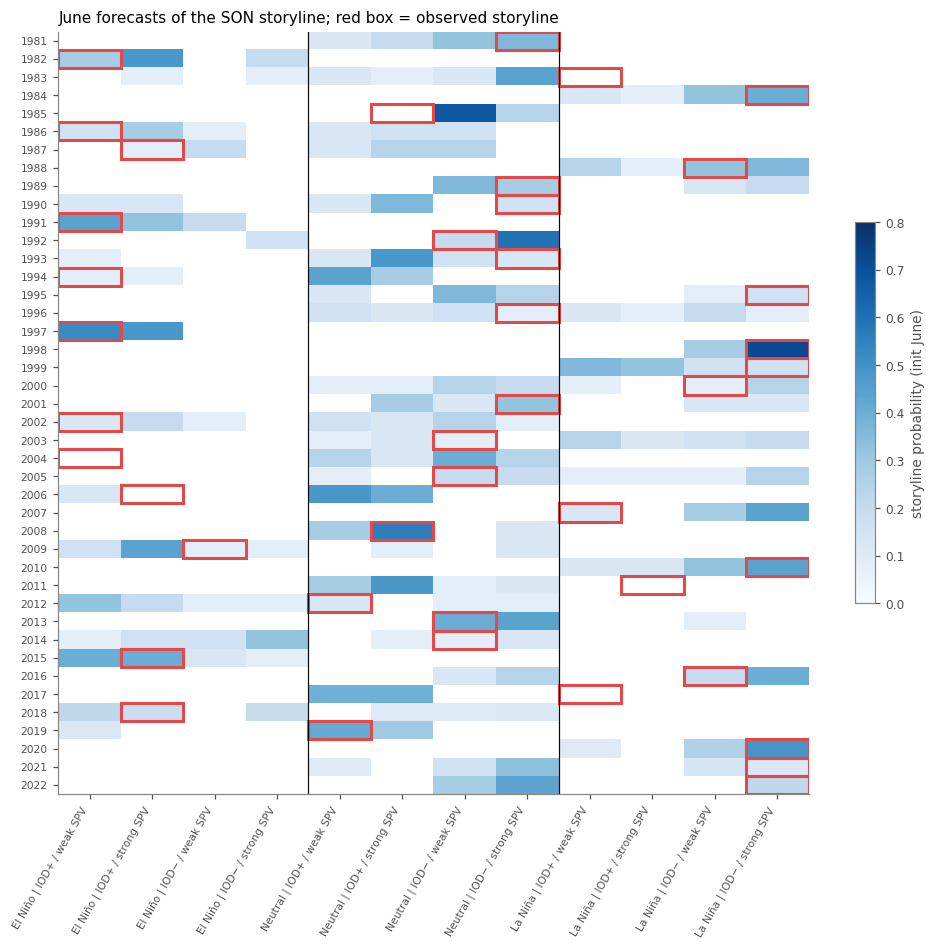

In [27]:
fig, ax = plt.subplots(figsize=(11, 9))
cj = cnt.xs(6, level="init_month")
pj = cj.div(cj.sum(axis=1), axis=0).loc[obs.index]
show = pj.where(pj >= MIN_FRAC)
im = ax.imshow(show.values, cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
for i, y in enumerate(obs.index):
    j = STORIES.index(obs.loc[y, "story"])
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=PCOL["El Niño"], lw=2))
ax.set_yticks(range(len(obs))); ax.set_yticklabels(obs.index, fontsize=7)
ax.set_xticks(range(len(STORIES))); ax.set_xticklabels(STORIES, rotation=60, ha="right", fontsize=7)
for x in (3.5, 7.5):
    ax.axvline(x, color=INK, lw=0.8)
fig.colorbar(im, ax=ax, shrink=0.5, label="storyline probability (init June)")
ax.set_title("June forecasts of the SON storyline; red box = observed storyline", loc="left")
savefig(fig, "fig13_forecast_storyline_probabilities_june")

In [28]:
def rate(x):
    return pd.Series(dict(n_forecasts=len(x),
                          mean_n_plausible=x.n_plausible.mean(),
                          mean_n_discarded=12 - x.n_plausible.mean(),
                          obs_story_plausible=x.hit.mean(),
                          obs_story_plausible_1member=x.hit_1member.mean(),
                          climatological_set_same_size=x.hit_clim.mean(),
                          ensemble_mean_story_correct=x.em_hit.mean(),
                          ENSO_phase_decided=((x.frac_ENSO >= 0.8) | (x.frac_ENSO <= 0.2)).mean(),
                          IOD_sign_decided=((x.frac_IOD >= 0.8) | (x.frac_IOD <= 0.2)).mean(),
                          SPV_sign_decided=((x.frac_SPV >= 0.8) | (x.frac_SPV <= 0.2)).mean()))


q1 = F.groupby("init_month").apply(rate).T
q1.round(2)

init_month,6,7,8
n_forecasts,42.00,42.00,42.00
mean_n_plausible,4.43,3.76,3.29
mean_n_discarded,7.57,8.24,8.71
obs_story_plausible,0.86,0.86,0.95
obs_story_plausible_1member,0.88,0.95,0.95
climatological_set_same_size,0.45,0.40,0.43
ensemble_mean_story_correct,0.33,0.52,0.48
ENSO_phase_decided,0.55,0.62,0.76
IOD_sign_decided,0.38,0.64,0.76
SPV_sign_decided,0.00,0.07,0.12


`*_decided`: share of forecasts where at least 80 % of the members agree on that driver's category (the observed one
or not). The phase may be decided at 4 months while the IOD and SPV signs stay open; then the plausible set is
"one ENSO phase, all four quadrants", and the forecast discards the storylines of the other phases.

**Are the discarded storylines really impossible?** Over all discarded (forecast, storyline) pairs, how often the
discarded storyline was the observed one, against how often the observed storyline is any given storyline
(the reliability of "discard").

In [29]:
disc = []
for (y, m), c in cnt.iterrows():
    so = obs.loc[y, "story"]
    for s_ in STORIES:
        disc.append(dict(init_month=m, discarded=c[s_] / c.sum() < MIN_FRAC, happened=s_ == so, p=c[s_] / c.sum()))
disc = pd.DataFrame(disc)
q1b = disc.groupby(["init_month", "discarded"]).happened.mean().unstack()
q1b.columns = ["obs. frequency when kept", "obs. frequency when discarded"]
q1b["n discarded per forecast"] = disc.groupby("init_month").discarded.mean() * 12
q1b.round(3)

,obs. frequency when kept,obs. frequency when discarded,n discarded per forecast
init_month,,,
6,0.194,0.019,7.571
7,0.228,0.017,8.238
8,0.290,0.005,8.714


**Reliability diagram of the storyline probabilities** (all 12 storylines pooled; bins of forecast probability).

*What is plotted.* Every forecast (one year, one init month) gives a probability to each of the 12 storylines: the share of
its members in that storyline. That makes 42 years × 12 storylines = 504 (forecast, storyline) pairs per init month,
each with a forecast probability $p$ and an outcome (1 if that storyline was the observed one, else 0). The pairs of all
12 storylines are pooled and grouped in bins of $p$: 0 (no member), 0–0.08 (1–2 of 25 members, 1–4 of 51), 0.08–0.2, 0.2–0.4, 0.4–0.6
and above 0.6. Each point is one bin: x = the mean forecast probability in the bin, y = how often the storylines in that bin
actually happened. One line per init month (June = 4-month lead).

*How to read it.* On the diagonal the probabilities are **reliable**: storylines given 30 % happen 30 % of the time.
Below the diagonal the forecast is **overconfident** (the storyline happens less often than forecast); above it,
**underconfident**. The left end tests "discard": storylines with 0 or 1–2 members should almost never happen. The table
below the figure gives the number of pairs in each bin; the high-probability bins hold few pairs (2–24), so their points
are uncertain by ±0.1–0.3. The pairs are not independent: in each forecast exactly one storyline happens.

*Result.* The low end is reliable: storylines with no member happened 1–2 % of the time, and with fewer than 8 % of the members
3–8 % (forecast 5–6 %), so discarding them is safe. In the middle (0.08–0.2) the observed frequency is close to the forecast
(0.12–0.17 against 0.14–0.16). At the high end, **June forecasts are overconfident**: storylines given 0.2–0.4 happened 17 % of the
time and those given 0.4–0.6 only 33 %, while for July and August starts these bins are near the diagonal (0.26–0.29 and 0.53–0.58).
So with 4 months lead the ensemble is good at saying which storylines are *not* possible, but its preference among the plausible
ones should not be taken at face value; from July the probabilities can be used as they are.

/var/folders/50/49j6_slj4k9bq1x354fp5jwh0000gn/T/ipykernel_42830/3201051905.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(pd.cut(d.p, bins))


n           mean_forecast             observed_freq        \
init_month        6    7    8             6     7     8             6     7   
p                                                                             
0 (0 members)   259  295  324          0.00  0.00  0.00          0.02  0.01   
0–0.08 (< 8 %)   98   72   59          0.06  0.05  0.05          0.08  0.08   
0.08–0.2         75   59   42          0.14  0.15  0.16          0.17  0.12   
0.2–0.4          52   57   48          0.30  0.30  0.31          0.17  0.26   
0.4–0.6          18   17   24          0.47  0.52  0.51          0.33  0.53   
> 0.6             2    4    7          0.70  0.73  0.72          0.50  0.75   

                      
init_month         8  
p                     
0 (0 members)   0.01  
0–0.08 (< 8 %)  0.03  
0.08–0.2        0.14  
0.2–0.4         0.29  
0.4–0.6         0.58  
> 0.6           0.57

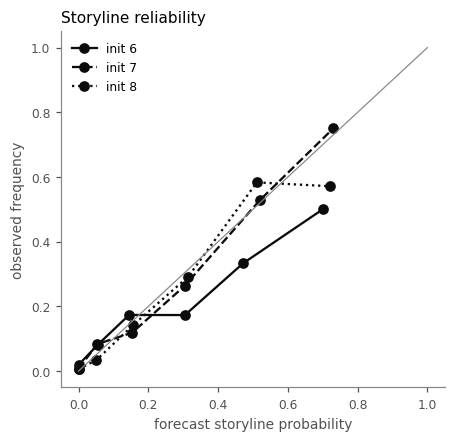

In [30]:
bins = [-0.01, 0.0001, 0.08, 0.2, 0.4, 0.6, 1.0]
fig, ax = plt.subplots(figsize=(4.5, 4.2))
for m, ls in zip(INITS, ["-", "--", ":"]):
    d = disc[disc.init_month == m]
    g = d.groupby(pd.cut(d.p, bins))
    ax.plot(g.p.mean(), g.happened.mean(), marker="o", ls=ls, color=INK, label=f"init {m}")
ax.plot([0, 1], [0, 1], color="#898781", lw=0.8)
ax.set_xlabel("forecast storyline probability"); ax.set_ylabel("observed frequency")
ax.legend(); ax.set_title("Storyline reliability", loc="left")
savefig(fig, "fig14_storyline_reliability")
rel = disc.groupby(["init_month", pd.cut(disc.p, bins, labels=["0 (0 members)", "0–0.08 (< 8 %)", "0.08–0.2", "0.2–0.4", "0.4–0.6", "> 0.6"])],
                   observed=True).agg(n=("p", "size"), mean_forecast=("p", "mean"), observed_freq=("happened", "mean"))
rel.unstack(0).round(2)

### 8.2 Was the observed spring one of the plausible storylines, even when the ensemble mean was poor?

Three measures for each forecast and region:

* **driver hit**: the observed storyline was plausible (≥ 8 % of the members);
* **impact hit**: the observed precipitation lies inside the range of the members of the observed storyline;
* **storyline gain**: |obs − mean of the observed-storyline members| against |obs − ensemble mean|. Any smaller
  sub-ensemble gets closer to the observations by chance, so the gain is measured against random sub-ensembles of the same
  size (`random_err`). The storyline is chosen from the **drivers**, never from the observed precipitation.

The same measures are given for the years when the **ensemble mean was poor** (its error in the worst third).

In [31]:
def q2(x, r):
    has = x[f"{r}_story_err"].notna()
    return pd.Series(dict(n=len(x), driver_hit=x.hit.mean(),
                          obs_in_5_95_all_members=x[f"{r}_in_range"].mean(),
                          impact_hit=x.loc[has, f"{r}_in_story_range"].astype(float).mean(),
                          em_err=x[f"{r}_em_err"].mean(),
                          story_err=x.loc[has, f"{r}_story_err"].mean(),
                          random_subset_err=x.loc[has, f"{r}_random_err"].mean(),
                          story_beats_random=(x.loc[has, f"{r}_story_err"] < x.loc[has, f"{r}_random_err"]).mean()))


q2tab = {}
for r in REGIONS:
    bad = F[f"{r}_em_err"] > F.groupby("init_month")[f"{r}_em_err"].transform(lambda s: s.quantile(2 / 3))
    F[f"{r}_bad_em"] = bad
    for m in INITS:
        x = F.xs(m, level="init_month", drop_level=False)
        q2tab[(r, m, "all years")] = q2(x, r)
        q2tab[(r, m, "poor ensemble mean")] = q2(x[x[f"{r}_bad_em"]], r)
q2tab = pd.DataFrame(q2tab).T
q2tab.round(2)

n  driver_hit  obs_in_5_95_all_members  \
AndesN 6 all years           42.0        0.86                     0.83   
         poor ensemble mean  14.0        0.93                     0.50   
       7 all years           42.0        0.86                     0.76   
         poor ensemble mean  14.0        0.93                     0.29   
       8 all years           42.0        0.95                     0.79   
         poor ensemble mean  14.0        0.86                     0.43   
AndesS 6 all years           42.0        0.86                     0.86   
         poor ensemble mean  14.0        0.79                     0.57   
       7 all years           42.0        0.86                     0.88   
         poor ensemble mean  14.0        0.71                     0.64   
       8 all years           42.0        0.95                     0.83   
         poor ensemble mean  14.0        0.93                     0.50   
SESA   6 all years           42.0        0.86                     0.76   
         poor ensemble mean  14.0        0.93                     0.29   
       7 all years           42.0        0.86                     0.76   
         poor ensemble mean  14.0        0.93                     0.29   
       8 all years           42.0        0.95                     0.81   
         poor ensemble mean  14.0        0.93                     0.43   

                             impact_hit  em_err  story_err  random_subset_err  \
AndesN 6 all years                 0.72    0.87       0.82               0.96   
         poor ensemble mean        0.31    1.54       1.42               1.57   
       7 all years                 0.69    0.87       0.95               0.91   
         poor ensemble mean        0.31    1.55       1.54               1.53   
       8 all years                 0.78    0.83       0.79               0.82   
         poor ensemble mean        0.58    1.50       1.37               1.50   
AndesS 6 all years                 0.75    0.79       0.80               0.83   
         poor ensemble mean        0.55    1.45       1.16               1.46   
       7 all years                 0.78    0.77       0.81               0.75   
         poor ensemble mean        0.60    1.43       1.56               1.45   
       8 all years                 0.82    0.74       0.79               0.75   
         poor ensemble mean        0.54    1.29       1.42               1.31   
SESA   6 all years                 0.64    0.84       0.96               0.94   
         poor ensemble mean        0.31    1.58       1.55               1.58   
       7 all years                 0.69    0.79       0.89               0.87   
         poor ensemble mean        0.31    1.53       1.64               1.53   
       8 all years                 0.82    0.77       0.73               0.77   
         poor ensemble mean        0.54    1.46       1.40               1.42   

                             story_beats_random  
AndesN 6 all years                         0.64  
         poor ensemble mean                0.62  
       7 all years                         0.47  
         poor ensemble mean                0.46  
       8 all years                         0.65  
         poor ensemble mean                0.67  
AndesS 6 all years                         0.50  
         poor ensemble mean                0.73  
       7 all years                         0.50  
         poor ensemble mean                0.50  
       8 all years                         0.48  
         poor ensemble mean                0.38  
SESA   6 all years                         0.47  
         poor ensemble mean                0.46  
       7 all years                         0.50  
         poor ensemble mean                0.38  
       8 all years                         0.62  
         poor ensemble mean                0.54

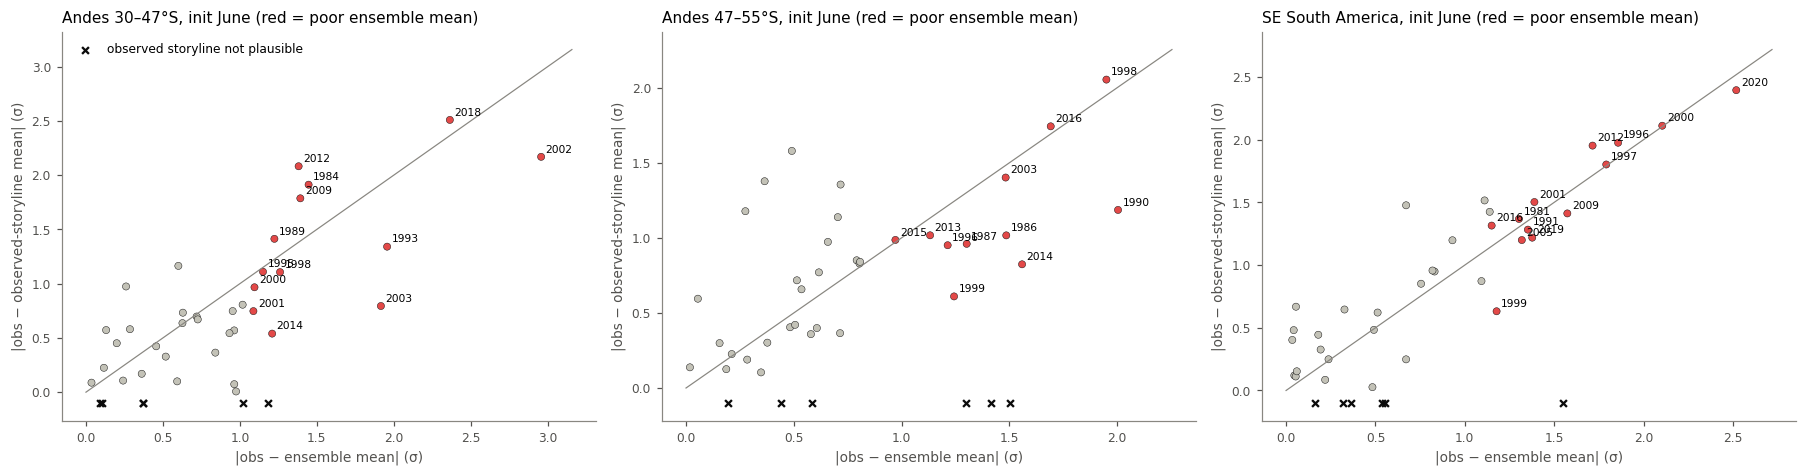

In [32]:
fig, axes = plt.subplots(1, NR, figsize=(5.5 * NR, 4.4))
for ax, r in zip(axes, REGIONS):
    x = F.xs(6, level="init_month")
    has = x[f"{r}_story_err"].notna()
    ax.scatter(x.loc[has, f"{r}_em_err"], x.loc[has, f"{r}_story_err"], s=22,
               c=np.where(x.loc[has, f"{r}_bad_em"], PCOL["El Niño"], GREY), edgecolor=INK, lw=0.3)
    for y in x.index[has & x[f"{r}_bad_em"]]:
        ax.annotate(str(y), (x.loc[y, f"{r}_em_err"], x.loc[y, f"{r}_story_err"]), xytext=(3, 3),
                    textcoords="offset points", fontsize=7)
    ax.scatter(x.loc[~has, f"{r}_em_err"], np.zeros((~has).sum()) - 0.1, marker="x", color=INK, s=20,
               label="observed storyline not plausible")
    lim = max(x[f"{r}_em_err"].max(), x[f"{r}_story_err"].max()) + 0.2
    ax.plot([0, lim], [0, lim], color="#898781", lw=0.8)
    ax.set_xlabel("|obs − ensemble mean| (σ)"); ax.set_ylabel("|obs − observed-storyline mean| (σ)")
    ax.set_title(f"{REGIONS[r]['name']}, init June (red = poor ensemble mean)", loc="left")
axes[0].legend(loc="upper left")
fig.tight_layout(); savefig(fig, "fig15_storyline_vs_ensemble_mean_error")

### 8.3 When the observed spring was outside the plausible storylines: which driver was mispredicted?

**Driver misses**: the observed storyline had fewer than 8 % of the members. For each, the share of members in the observed
category of each driver (ENSO phase, IOD sign, SPV sign); the driver with the smallest share is the one the forecast
got wrong.

In [33]:
miss = F[~F.hit][["obs_story", "n_obs_story", "frac_ENSO", "frac_IOD", "frac_SPV"]].copy()
miss["mispredicted"] = miss[["frac_ENSO", "frac_IOD", "frac_SPV"]].idxmin(axis=1).str.replace("frac_", "")
print(miss.groupby("init_month").mispredicted.value_counts().unstack(fill_value=0))
miss.xs(6, level="init_month").round(2)

mispredicted  ENSO  IOD
init_month             
6                5    1
7                3    3
8                1    1


,obs_story,n_obs_story,frac_ENSO,frac_IOD,frac_SPV,mispredicted
year,,,,,,
1983,La Niña | IOD+ / weak SPV,0,0.04,0.36,0.28,ENSO
1985,Neutral | IOD+ / strong SPV,0,0.92,0.00,0.24,IOD
2004,El Niño | IOD+ / weak SPV,0,0.00,0.36,0.64,ENSO
2006,El Niño | IOD+ / strong SPV,0,0.12,1.00,0.40,ENSO
2011,La Niña | IOD+ / strong SPV,0,0.04,0.76,0.60,ENSO
2017,La Niña | IOD+ / weak SPV,1,0.08,0.90,0.53,ENSO


**Precipitation misses**: the observed precipitation lies outside the 5–95 % range of all members. Using the path model, the
error obs − ensemble mean splits exactly into

$$\Delta P = \sum_X g_X\,\Delta X + \sum_k e_k\,\Delta \mathrm{SAM}_k^{\mathrm{res}} + \Delta\varepsilon,
\qquad g_X = e_X + \sum_k e_k c_{kX},$$

with Δ = observed − ensemble mean: the part due to each mispredicted driver (directly and through the SAM it forces),
the part due to the unforced SAM, and the rest. (Here $g_X$ excludes the chains through the other drivers, because their observed
values are given.)

error  ENSO   IOD   SPV  unforced S-SAM  unforced A-SAM  \
       year                                                            
AndesN 1984   1.45  0.09  0.01 -0.05           -0.10            0.01   
       1993  -1.96  0.12 -0.03 -0.28           -0.02            0.01   
       2003   1.92  0.34 -0.04 -0.04            0.09           -0.01   
       2009   1.39  0.10 -0.04  0.16            0.09            0.02   
       2014   1.21 -0.05 -0.00  0.26            0.08            0.03   
       2018   2.36  0.08  0.02 -0.27           -0.06           -0.02   
AndesS 1983   1.41  0.34  0.01 -0.00           -0.22            0.09   
       1986  -1.49 -0.09 -0.01 -0.00           -0.30           -0.05   
       1990   2.00  0.07 -0.03  0.00            0.00            0.05   
       1998   1.95 -0.07  0.02  0.00            0.12            0.18   
       2003   1.48 -0.27 -0.02  0.00            0.05           -0.06   
       2016  -1.69  0.05  0.02 -0.01           -0.04           -0.28   
SESA   1981  -1.30 -0.21  0.00  0.00            0.02           -0.11   
       1985  -1.55 -0.20  0.02 -0.05           -0.06            0.08   
       1996   1.86  0.18 -0.01 -0.03            0.08            0.09   
       1997   1.79  0.00 -0.00  0.00            0.05           -0.09   
       2000   2.10 -0.10  0.00  0.10            0.05           -0.11   
       2001   1.39 -0.03 -0.00 -0.09           -0.00            0.08   
       2005   1.32  0.23 -0.00  0.06            0.03            0.04   
       2009   1.57  0.16 -0.01  0.04            0.02           -0.05   
       2012  -1.71 -0.20 -0.00  0.12           -0.02           -0.09   
       2020  -2.52 -0.19  0.01 -0.14            0.06           -0.12   

             unforced SALLJ  rest  
       year                        
AndesN 1984            0.56  0.92  
       1993           -0.22 -1.53  
       2003            0.05  1.52  
       2009            0.62  0.44  
       2014            0.26  0.63  
       2018           -0.14  2.75  
AndesS 1983            0.04  1.16  
       1986            0.08 -1.12  
       1990           -0.11  2.02  
       1998            0.02  1.67  
       2003           -0.01  1.79  
       2016            0.21 -1.63  
SESA   1981            0.26 -1.27  
       1985           -0.36 -0.98  
       1996           -0.16  1.71  
       1997            0.62  1.21  
       2000            0.45  1.72  
       2001            0.55  0.88  
       2005           -0.16  1.13  
       2009            0.70  0.72  
       2012            0.12 -1.64  
       2020            0.19 -2.32

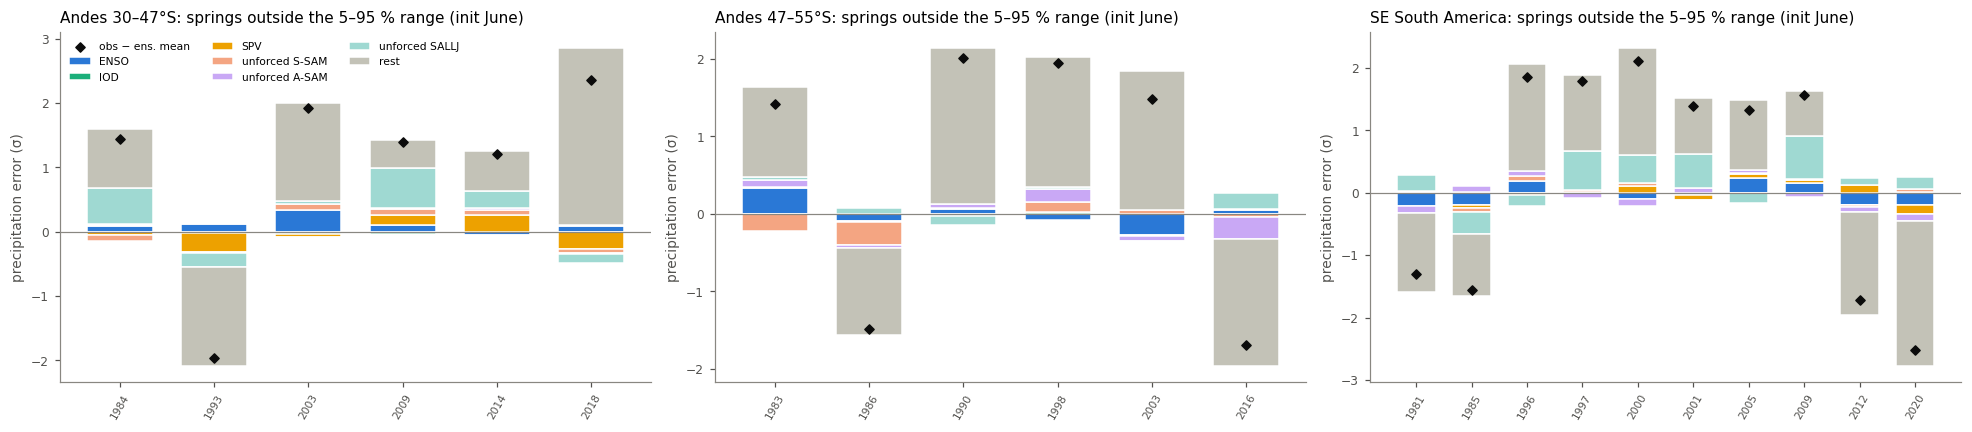

In [34]:
def attribution(r, m):
    B = SEM[r]
    iP = NODES.index("P")
    g = {x: B[iP, NODES.index(x)] + sum(B[iP, NODES.index(k)] * B[NODES.index(k), NODES.index(x)] for k in MEDS)
         for x in DRIVERS}
    out = []
    for y in F.xs(m, level="init_month").index:
        f = F.loc[(y, m)]
        if f[f"{r}_in_range"] or np.isnan(obs.loc[y, "S_SAM_z"]):
            continue
        d = df.xs((y, m), level=("year", "init_month"))
        o = obs_mz[m].loc[y]
        row = dict(year=y, error=o[f"P_{r}_z"] - d[f"P_{r}_z"].mean())
        for x in DRIVERS:
            row[x] = g[x] * (o[f"{x}_z"] - d[f"{x}_z"].mean())
        for k in MEDS:
            hat_o = sum(B[NODES.index(k), NODES.index(x)] * o[f"{x}_z"] for x in DRIVERS)
            row[f"unforced {k.replace('_', '-')}"] = B[iP, NODES.index(k)] * ((o[f"{k}_z"] - hat_o) - d[f"{k}_res"].mean())
        row["rest"] = row["error"] - sum(v for kk, v in row.items() if kk not in ("year", "error"))
        out.append(row)
    return pd.DataFrame(out).set_index("year")


ATT = {r: attribution(r, 6) for r in REGIONS}
fig, axes = plt.subplots(1, NR, figsize=(6 * NR, 4))
acol = {"ENSO": "#2a78d6", "IOD": "#1baf7a", "SPV": "#eda100", "unforced S-SAM": "#f4a582", "unforced A-SAM": "#c9a8f5",
        "unforced SALLJ": "#9fd9d2", "rest": "#c3c2b7"}
for ax, r in zip(axes, REGIONS):
    a = ATT[r]
    x = np.arange(len(a))
    pos, neg = np.zeros(len(a)), np.zeros(len(a))
    for c in acol:
        v = a[c].values
        ax.bar(x, v, bottom=np.where(v >= 0, pos, neg), color=acol[c], width=0.7, edgecolor="white", label=c)
        pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
    ax.scatter(x, a.error, color=INK, marker="D", s=18, zorder=3, label="obs − ens. mean")
    ax.axhline(0, color="#898781", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels(a.index, rotation=60, fontsize=7)
    ax.set_title(f"{REGIONS[r]['name']}: springs outside the 5–95 % range (init June)", loc="left")
    ax.set_ylabel("precipitation error (σ)")
axes[0].legend(ncol=3, fontsize=7)
fig.tight_layout(); savefig(fig, "fig16_miss_attribution")
pd.concat(ATT, axis=0).round(2)

Share of the squared error in these springs that each term explains, over all three init months.

In [35]:
att_all = {r: pd.concat([attribution(r, m) for m in INITS]) for r in REGIONS}
pd.DataFrame({r: (a[list(acol)].pow(2).sum() / a[list(acol)].pow(2).sum().sum()) for r, a in att_all.items()}).round(2)

,AndesN,AndesS,SESA
ENSO,0.01,0.01,0.01
IOD,0.00,0.00,0.00
SPV,0.03,0.00,0.00
unforced S-SAM,0.00,0.01,0.00
unforced A-SAM,0.00,0.01,0.00
unforced SALLJ,0.06,0.00,0.08
rest,0.90,0.97,0.90


## 9. Bottom-up storylines: start from the dry and wet springs

Sections 4–8 go **top-down**: condition on the drivers, then look at the precipitation. Here the order is reversed, as in
Chan et al. (who condition on low rainfall, then cluster): for each region,

1. condition on the **regional-mean precipitation percentile** of the pooled hindcast (all 3618 springs, neutral ENSO
   included): **dry** = below the 20th percentile, **wet** = above the 80th;
2. cluster the dry springs, and separately the wet springs, by their standardised drivers (ENSO, IOD, SPV) with k-means,
   K = `K_BU` = 4 as in Chan et al. and as the number of top-down quadrants (the silhouette score for K = 2–6 is shown as a check);
3. describe each cluster (= a bottom-up storyline): its share of the dry (wet) springs, the driver centroid, the
   mean S-SAM and A-SAM, and the top-down storyline most of its springs fall in;
4. show the driver values of the dry and wet springs in **ENSO–IOD–SPV space** (3-D), with the cluster centroids and the ERA5
   dry and wet springs (below the 20th / above the 80th percentile of the 42 observed springs).

Labels: D1–D4 (dry) and W1–W4 (wet), numbered from the lowest to the highest ENSO centroid.

In [36]:
from sklearn.metrics import silhouette_score
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)

K_BU = 4
ZV = ["ENSO_z", "IOD_z", "SPV_z"]
BU_COL = {"dry": "#8c510a", "wet": "#01665e"}
BU, BU_LAB, BU_SIL = {}, {}, {}
for r in REGIONS:
    lo, hi = df[f"P_{r}_z"].quantile([DRY_Q, 1 - DRY_Q])
    for kind, sel in [("dry", df[f"P_{r}_z"] < lo), ("wet", df[f"P_{r}_z"] > hi)]:
        d = df[sel]
        X = d[ZV].values
        BU_SIL[(r, kind)] = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X))
                             for k in range(2, 7)}
        km = KMeans(K_BU, n_init=20, random_state=0).fit(X)
        order = np.argsort(km.cluster_centers_[:, 0])                       # number clusters by ENSO centroid
        rank = {c: i for i, c in enumerate(order)}
        lab = pd.Series([f"{kind[0].upper()}{rank[c] + 1}" for c in km.labels_], index=d.index)
        BU_LAB[(r, kind)] = lab
        for name, g in d.groupby(lab):
            top = (g.phase + " | " + g.quad).value_counts(normalize=True)
            BU[(r, kind, name)] = dict(n=len(g), share=len(g) / len(d),
                                       **{f"{v}": g[f"{v}_z"].mean() for v in DRIVERS + MEDS},
                                       ENSO_K=g.ENSO.mean(), P_z=g[f"P_{r}_z"].mean(),
                                       years=g.index.get_level_values("year").nunique(),
                                       top_down_storyline=top.index[0], its_share=top.iloc[0])
BU = pd.DataFrame(BU).T
BU.index.names = ["region", "kind", "cluster"]
BU.to_csv(OUT / "enso_sam_bottom_up_clusters.csv")
print("silhouette (K = 2..6):")
print(pd.DataFrame(BU_SIL).T.round(2))
BU.round(2)

silhouette (K = 2..6):
               2     3     4     5     6
AndesN dry  0.31  0.28  0.25  0.25  0.27
       wet  0.31  0.29  0.29  0.26  0.27
AndesS dry  0.33  0.33  0.29  0.27  0.25
       wet  0.31  0.28  0.24  0.26  0.25
SESA   dry  0.28  0.29  0.27  0.27  0.26
       wet  0.30  0.29  0.27  0.28  0.28


n     share      ENSO       IOD       SPV     S_SAM  \
region kind cluster                                                          
AndesN dry  D1       145  0.200276 -1.552582 -0.752043  0.942858  1.005568   
            D2       168  0.232044 -0.574585 -0.218322 -0.662772 -0.241014   
            D3       258  0.356354 -0.197648 -0.725496  0.750935  0.815949   
            D4       153  0.211326  0.534567  0.969695   0.61221  0.535924   
       wet  W1       143  0.197514 -0.386537 -0.535048 -1.735685 -1.481434   
            W2       282  0.389503  0.122417 -0.324493  0.156419 -0.155096   
            W3       158  0.218232  0.414993  1.351782 -0.845713 -0.842089   
            W4       141  0.194751  2.227446  1.357217 -0.033564 -0.384471   
AndesS dry  D1       254  0.350829 -0.545395  -0.76431  0.514585  0.662879   
            D2       126  0.174033 -0.062665 -0.033337 -1.644507 -1.101892   
            D3       214   0.29558  0.486238  0.656339  0.365611  0.348794   
            D4       130  0.179558  2.165216   1.13939  0.025931   -0.1315   
       wet  W1       245  0.338398 -0.838737 -0.833105   0.69495  0.470248   
            W2       156   0.21547 -0.597434 -0.547647 -0.981902  -0.78862   
            W3       145  0.200276  0.231904  1.411574 -0.097665 -0.217821   
            W4       178  0.245856  0.405183  -0.05252  0.250637 -0.022678   
SESA   dry  D1       145  0.200276 -1.592289 -0.442965  0.807828  0.758145   
            D2       137  0.189227 -0.717151   -0.4628 -1.242983 -0.854102   
            D3       267  0.368785 -0.314658 -0.837643  0.536768  0.503247   
            D4       175  0.241713  0.012591  0.914748  0.011135 -0.003702   
       wet  W1       175  0.241713 -0.381188 -0.626897  0.381103  0.249828   
            W2       146  0.201657  0.335092  0.177521 -1.530646 -1.167804   
            W3       242  0.334254  0.743449   0.66905  0.363392  0.193433   
            W4       161  0.222376  2.407978  1.377506 -0.062008  -0.37123   

                        A_SAM     SALLJ    ENSO_K       P_z years  \
region kind cluster                                                 
AndesN dry  D1       1.337279 -1.007933 -1.329387 -1.374255    17   
            D2       0.291474 -0.955355 -0.514404 -1.246969    38   
            D3       0.700744 -0.737536 -0.232115 -1.316455    31   
            D4       0.229952 -0.296057  0.377075 -1.227875    26   
       wet  W1      -0.489711  0.417718 -0.394622  1.529572    34   
            W2      -0.308403  0.675175  0.039395  1.357723    41   
            W3      -0.811398  0.868545  0.240269   1.43224    22   
            W4      -1.155505  1.625196  1.831138  1.736959    14   
AndesS dry  D1       0.807436 -0.369339 -0.525871 -1.353083    32   
            D2      -0.358986  0.147336 -0.111044 -1.340393    38   
            D3       0.112595  0.274249  0.332273 -1.379653    28   
            D4      -0.910892  1.297715  1.752167 -1.572281    14   
       wet  W1       0.597862 -0.603987 -0.765191  1.386893    26   
            W2      -0.104804 -0.334729 -0.539274  1.427696    31   
            W3      -0.572814  0.274305  0.103566  1.421313    28   
            W4      -0.472089  0.133581  0.285869  1.413259    33   
SESA   dry  D1       1.256141 -1.164846 -1.349424 -1.465407    13   
            D2      -0.015918 -0.930794 -0.634294 -1.356498    31   
            D3       0.556861 -0.851366 -0.353394 -1.370476    32   
            D4      -0.012266  -0.54119 -0.058952 -1.271539    33   
       wet  W1       0.217652  0.609241 -0.371048    1.2727    32   
            W2      -0.779676  0.817717  0.188953  1.350797    33   
            W3      -0.489516  0.903078  0.537547  1.322059    23   
            W4      -1.078256  1.493604  1.947526  1.817416     8   

                              top_down_storyline its_share  
region kind cluster                                         
AndesN dry  D1       La Niña | IOD− / strong SPV       0.8  
            D2  

**Driver values of the dry and wet springs in ENSO–IOD–SPV space.** Small dots: hindcast springs (brown = dry, green = wet).
Large markers: cluster centroids (▼ dry, ▲ wet), labelled. Stars: ERA5 dry and wet springs, labelled with the year.
All axes in standard deviations (+SPV = strong vortex). The panels below show the three 2-D projections of the same centroids,
because depth is hard to read in 3-D.

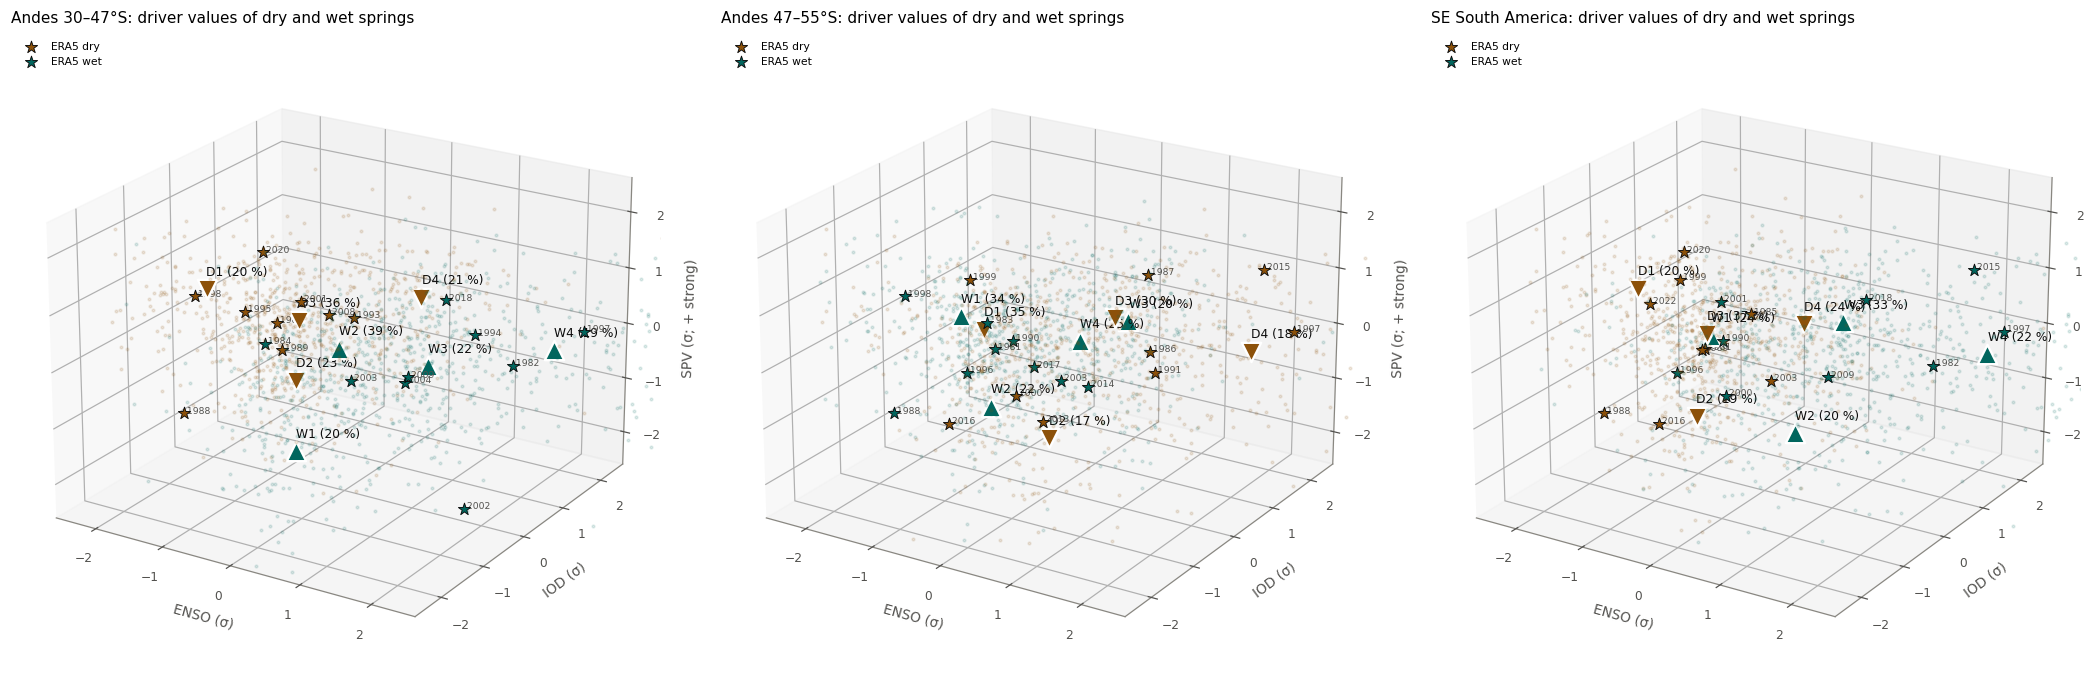

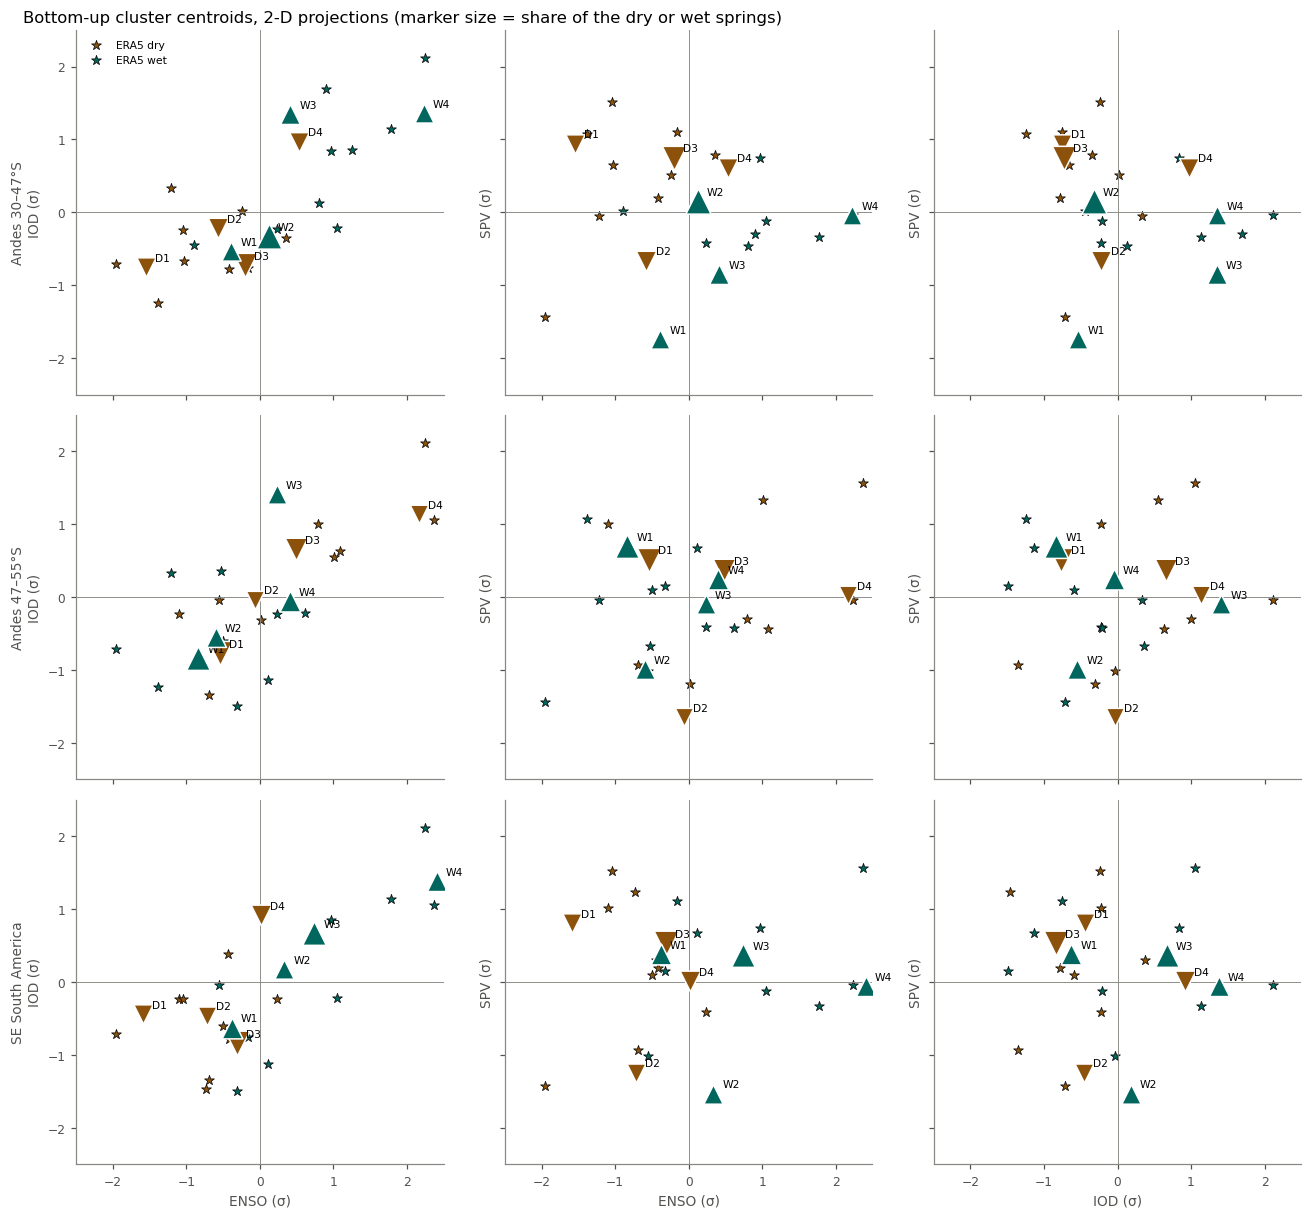

In [37]:
odry = {}
for r in REGIONS:
    lo, hi = obs[f"P_{r}_z"].quantile([DRY_Q, 1 - DRY_Q])
    odry[r] = {"dry": obs[obs[f"P_{r}_z"] < lo], "wet": obs[obs[f"P_{r}_z"] > hi]}

fig = plt.figure(figsize=(6.5 * NR, 6.2))
for i, r in enumerate(REGIONS):
    ax = fig.add_subplot(1, NR, i + 1, projection="3d")
    for kind, mk in [("dry", "v"), ("wet", "^")]:
        lab = BU_LAB[(r, kind)]
        d = df.loc[lab.index]
        ax.scatter(d.ENSO_z, d.IOD_z, d.SPV_z, s=3, color=BU_COL[kind], alpha=0.12, depthshade=False, rasterized=True)
        for name, c in BU.loc[(r, kind)].iterrows():
            ax.scatter(c.ENSO, c.IOD, c.SPV, s=160, marker=mk, color=BU_COL[kind], edgecolor="white", linewidth=1.5,
                       depthshade=False, zorder=5)
            ax.text(c.ENSO, c.IOD, c.SPV + 0.25, f"{name} ({100 * c.share:.0f} %)", fontsize=8, color=INK)
        o = odry[r][kind]
        ax.scatter(o.ENSO_z, o.IOD_z, o.SPV_z, s=70, marker="*", color=BU_COL[kind], edgecolor=INK, linewidth=0.6,
                   depthshade=False, label=f"ERA5 {kind}")
        for y, row in o.iterrows():
            ax.text(row.ENSO_z, row.IOD_z, row.SPV_z, f" {y}", fontsize=6, color="#52514e")
    ax.set_xlabel("ENSO (σ)"); ax.set_ylabel("IOD (σ)"); ax.set_zlabel("SPV (σ; + strong)")
    lim = (-2.5, 2.5)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_zlim(lim)
    ax.view_init(elev=22, azim=-58)
    ax.set_title(f"{REGIONS[r]['name']}: driver values of dry and wet springs", loc="left")
    ax.legend(loc="upper left", fontsize=7)
fig.tight_layout(); savefig(fig, "fig17_bottom_up_3d")

fig, axes = plt.subplots(NR, 3, figsize=(12, 3.75 * NR), sharex=True, sharey=True)
pairs = [("ENSO", "IOD"), ("ENSO", "SPV"), ("IOD", "SPV")]
for i, r in enumerate(REGIONS):
    for j, (a, b) in enumerate(pairs):
        ax = axes[i, j]
        for kind, mk in [("dry", "v"), ("wet", "^")]:
            for name, c in BU.loc[(r, kind)].iterrows():
                ax.scatter(c[a], c[b], s=40 + 600 * c.share, marker=mk, color=BU_COL[kind], edgecolor="white", zorder=3)
                ax.annotate(name, (c[a], c[b]), xytext=(6, 4), textcoords="offset points", fontsize=7)
            o = odry[r][kind]
            ax.scatter(o[f"{a}_z"], o[f"{b}_z"], marker="*", s=45, color=BU_COL[kind], edgecolor=INK, linewidth=0.5,
                       label=f"ERA5 {kind}" if (i, j) == (0, 0) else None)
        ax.axhline(0, color="#898781", lw=0.6); ax.axvline(0, color="#898781", lw=0.6)
        ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
        if i == NR - 1:
            ax.set_xlabel(f"{a} (σ)")
        if j == 0:
            ax.set_ylabel(f"{REGIONS[r]['name']}\n{b} (σ)")
        else:
            ax.set_ylabel(f"{b} (σ)")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Bottom-up cluster centroids, 2-D projections (marker size = share of the dry or wet springs)",
             x=0.02, ha="left")
fig.tight_layout(); savefig(fig, "fig18_bottom_up_projections")

**Do the bottom-up and top-down storylines agree?** For each region: the share of dry (wet) springs in each top-down
storyline (ENSO phase × IOD–SPV quadrant, 12 storylines), against that storyline's share of all springs. A ratio above 1
means the storyline is over-represented among the dry (wet) springs.

In [38]:
allp = (df.phase + " | " + df.quad).value_counts(normalize=True)
bu_td = {}
for r in REGIONS:
    for kind in ["dry", "wet"]:
        s_ = df.loc[BU_LAB[(r, kind)].index]
        bu_td[(r, f"{kind}: ratio")] = (s_.phase + " | " + s_.quad).value_counts(normalize=True).reindex(STORIES) / allp
bu_td = pd.DataFrame(bu_td).fillna(0)
bu_td.round(2)

AndesN                AndesS             \
                            dry: ratio wet: ratio dry: ratio wet: ratio   
El Niño | IOD+ / strong SPV       0.66       1.49       1.71       0.66   
El Niño | IOD+ / weak SPV         0.20       2.27       1.53       0.56   
El Niño | IOD− / strong SPV       0.88       1.04       1.09       0.62   
El Niño | IOD− / weak SPV         0.36       1.58       0.92       0.92   
La Niña | IOD+ / strong SPV       1.85       0.21       0.55       1.22   
La Niña | IOD+ / weak SPV         1.04       0.97       0.67       1.19   
La Niña | IOD− / strong SPV       1.81       0.28       0.87       1.28   
La Niña | IOD− / weak SPV         0.94       0.91       0.70       1.21   
Neutral | IOD+ / strong SPV       0.99       0.62       1.00       0.98   
Neutral | IOD+ / weak SPV         0.52       1.53       0.94       0.93   
Neutral | IOD− / strong SPV       1.45       0.56       0.97       1.10   
Neutral | IOD− / weak SPV         0.67       1.25       0.82       0.98   

                                  SESA             
                            dry: ratio wet: ratio  
El Niño | IOD+ / strong SPV       0.17       2.41  
El Niño | IOD+ / weak SPV         0.29       2.54  
El Niño | IOD− / strong SPV       0.26       1.35  
El Niño | IOD− / weak SPV         0.25       1.58  
La Niña | IOD+ / strong SPV       1.89       0.38  
La Niña | IOD+ / weak SPV         1.68       0.48  
La Niña | IOD− / strong SPV       1.65       0.35  
La Niña | IOD− / weak SPV         1.47       0.53  
Neutral | IOD+ / strong SPV       0.86       0.89  
Neutral | IOD+ / weak SPV         0.84       0.99  
Neutral | IOD− / strong SPV       1.21       0.74  
Neutral | IOD− / weak SPV         0.87       0.65

**Interpretation.**

* **The driver space has no clear clusters.** Silhouette scores are 0.24–0.33 for every K (0 = no structure, 1 = well
  separated), with no peak at any K. The dry (wet) springs fill a continuum; the four clusters are a convenient partition
  of it, not distinct regimes, and their centroids are what to read.
* **Most dry springs are not La Niña (or El Niño) springs.** Dry springs by ENSO phase (all springs: 49 % neutral, 29 % La Niña,
  22 % El Niño; from P(dry) per phase in Section 4): northern Andes about 46 / 43 / 11 %, southern Andes 46 / 22 / 32 % (El Niño is
  the dry phase there), SESA 46 / 48 / 5 %. A top-down approach that starts from one ENSO phase sees 32–48 % of the dry springs.
* **Northern Andes (30–47°S): the strong vortex is the common factor.** Three of the four dry clusters, 77 % of the dry springs,
  have a strong SPV (+0.6 to +0.9σ) and a positive S-SAM (+0.5 to +1.0σ): D1 = La Niña with IOD− (20 %; A-SAM +1.3σ),
  D3 = neutral ENSO with IOD− (36 %), D4 = weak El Niño with IOD+ (21 %). The fourth, D2 (23 %), has a weak vortex, a weak La Niña
  and a near-neutral S-SAM. The wet clusters mirror this: W1 = weak vortex (−1.7σ, S-SAM −1.5σ, 20 %), W4 = strong El Niño with IOD+ (19 %).
* **Southern Andes (47–55°S): El Niño is the dry phase.** D4 = strong El Niño with IOD+ (18 %, A-SAM −0.9σ) and D3 = weak
  El Niño with IOD+ (30 %); D1 = weak La Niña with IOD− and a strong vortex (35 %) and D2 = weak vortex (−1.6σ, 17 %) are
  the other dry routes. The largest wet cluster, W1, is La Niña with a strong vortex (34 %).
* **SESA: ENSO separates dry from wet, the vortex does not.** The dry centroids all have ENSO ≤ 0 (D1 = La Niña, 20 %), and
  the wet centroids W3–W4 are El Niño with IOD+ (56 %). SPV appears with both signs in both groups, so it is not what makes a
  SESA spring dry or wet. D4 (24 %) is a neutral-ENSO IOD+ dry cluster.
* **Agreement with the top-down storylines** (ratio table): northern Andes dry springs are over-represented about 1.8 times in La Niña
  with a strong vortex and under-represented in El Niño IOD+/weak vortex (0.20); southern Andes dry springs 1.5–1.7 times in El Niño
  IOD+; SESA dry springs 1.5–1.9 times in every La Niña storyline, and wet springs 1.35–2.5 times in every El Niño storyline.
* **ERA5.** The observed dry and wet springs (stars) lie among the hindcast springs of the same kind. 2015 (strong El Niño, very
  strong vortex), the driest observed southern-Andes spring, sits in the direction of D3–D4; 2020 (La Niña, strong vortex), the driest
  observed SESA spring, sits in D1.

### 9.1 Are the top-down (driver) storylines more reliable than the bottom-up ones?

Both kinds of storyline are used as forecasts and verified the same way (Section 8 style, all three init months):

* **top-down**: the 12 storylines (ENSO phase × IOD–SPV quadrant); a member's storyline is set by its drivers;
* **bottom-up**: the 8 clusters of each region (D1–D4, W1–W4; Section 9); a member belongs to the cluster with the nearest centroid
  in (ENSO, IOD, SPV), and so does the observed spring (drivers in model units). The clusters are region-specific.

Two tests:

1. **Storyline probabilities**: is the storyline that happens given the right probability? Reliability diagram (as fig14) and the
   Brier skill score against the climatological storyline frequencies, $\mathrm{BSS} = 1 - \mathrm{BS}/\mathrm{BS}_\mathrm{clim}$ with
   $\mathrm{BS} = \sum_k (p_k - o_k)^2$ averaged over forecasts.
2. **Dry-spring forecast through the storylines**: $P(\mathrm{dry}) = \sum_k p_k\, P(\mathrm{dry}\mid k)$, with $P(\mathrm{dry}\mid k)$
   from the hindcast **leaving out the forecast year**. Compared with the raw ensemble (share of dry members) and climatology (0.2).
   This asks whether routing the forecast through the storylines keeps (or improves) the reliability of the dry-spring probability.

Verification against **ERA5** (126 forecasts, 42 independent years) and in a **perfect-model** setting (each member in turn is the
truth and the other 24 or 50 are the forecast: 3618 cases, no model–observation mismatch). 90 % intervals: bootstrap over years.
(The cluster centroids were fitted on all years, a small leak in favour of the bottom-up storylines.)

In [39]:
def nearest_cluster(X, cents):
    d2 = ((X[:, None, :] - cents[None, :, :]) ** 2).sum(-1)
    return d2.argmin(1)


BU_NAMES, BU_C = {}, {}
for r in REGIONS:
    c = BU.loc[r][["ENSO", "IOD", "SPV"]].astype(float)
    BU_NAMES[r] = [f"{k}{n}" for k, n in c.index]
    BU_C[r] = c.values
    df[f"bu_{r}"] = np.array(BU_NAMES[r])[nearest_cluster(df[ZV].values, BU_C[r])]

FC = ["year", "init_month"]                    # one forecast = one year and init month
yr = df.index.get_level_values("year").values
fkeys = df.groupby(level=FC).size().index                          # (year, init) forecasts


def verify(r, kind):
    """Per-forecast storyline probabilities, outcomes and P(dry) forecasts, for ERA5 and the perfect model."""
    col = "story" if kind == "top-down" else f"bu_{r}"
    cats = STORIES if kind == "top-down" else BU_NAMES[r]
    oh = pd.get_dummies(df[col]).reindex(columns=cats, fill_value=False).values.astype(float)
    dry = df[f"dry_{r}"].values.astype(float)
    # leave-one-year-out P(dry | storyline)
    tot_n, tot_d = oh.sum(0), (oh * dry[:, None]).sum(0)
    pk_loyo = {}
    for y in uyears:
        m = yr == y
        n_, d_ = tot_n - oh[m].sum(0), tot_d - (oh[m] * dry[m, None]).sum(0)
        pk_loyo[y] = np.where(n_ > 0, d_ / np.maximum(n_, 1), DRY_Q)
    clim_k = tot_n / tot_n.sum()
    obs_rows, pm_rows = [], []
    for (y, m) in fkeys:
        rows = np.where((yr == y) & (df.index.get_level_values("init_month").values == m))[0]
        O = oh[rows]; D = dry[rows]
        p = O.mean(0)
        om = obs_mz[m].loc[y]
        if kind == "top-down":
            o_cat = STORIES.index(obs.loc[y, "story"])
        else:
            o_cat = nearest_cluster(np.array([[om["ENSO_z"], om["IOD_z"], om["SPV_z"]]]), BU_C[r])[0]
        o = np.zeros(len(cats)); o[o_cat] = 1
        obs_rows.append(dict(year=y, p=p, o=o, clim=clim_k, pdry_story=p @ pk_loyo[y], pdry_ens=D.mean(),
                             dry=float(obs.loc[y, f"dry_{r}"])))
        # perfect model: member j is the truth, the other members the forecast
        for j in range(len(rows)):
            keep = np.arange(len(rows)) != j
            pj = O[keep].mean(0)
            pm_rows.append(dict(year=y, p=pj, o=O[j], clim=clim_k, pdry_story=pj @ pk_loyo[y],
                                pdry_ens=D[keep].mean(), dry=D[j]))
    return pd.DataFrame(obs_rows), pd.DataFrame(pm_rows)


def scores(v):
    P, O, C = np.stack(v.p), np.stack(v.o), np.stack(v.clim)
    bs, bsc = ((P - O) ** 2).sum(1), ((C - O) ** 2).sum(1)
    out = dict(BSS_storyline=1 - bs.mean() / bsc.mean())
    for f in ["pdry_story", "pdry_ens"]:
        out[f"BSS_dry_{f[5:]}"] = 1 - ((v[f] - v.dry) ** 2).mean() / ((DRY_Q - v.dry) ** 2).mean()
    return out


def boot_scores(v, n=200):
    ys = v.year.values
    idx = {y: np.where(ys == y)[0] for y in uyears}
    b = [scores(v.iloc[np.concatenate([idx[y] for y in RNG.choice(uyears, len(uyears))])]) for _ in range(n)]
    b = pd.DataFrame(b)
    return b.quantile(0.05), b.quantile(0.95)


VER, REL_TAB = {}, {}
for r in REGIONS:
    for kind in ["top-down", "bottom-up"]:
        vo, vp = verify(r, kind)
        VER[(r, kind)] = (vo, vp)
        for lab, v in [("ERA5", vo), ("perfect model", vp)]:
            s = scores(v)
            lo, hi = boot_scores(v, 100 if lab == "perfect model" else 200)
            for k_ in s:
                REL_TAB[(r, kind, lab, k_)] = dict(value=s[k_], lo=lo[k_], hi=hi[k_])
REL_TAB = pd.DataFrame(REL_TAB).T
REL_TAB.index.names = ["region", "storylines", "verified against", "score"]
REL_TAB.to_csv(OUT / "enso_sam_topdown_vs_bottomup_reliability.csv")
REL_TAB.unstack("score")["value"].round(3)

score                               BSS_dry_ens  BSS_dry_story  BSS_storyline
region storylines verified against                                           
AndesN bottom-up  ERA5                    0.099          0.091          0.176
                  perfect model           0.020          0.036          0.234
       top-down   ERA5                    0.099          0.077          0.183
                  perfect model           0.020          0.027          0.196
AndesS bottom-up  ERA5                    0.040          0.100          0.196
                  perfect model           0.004          0.030          0.242
       top-down   ERA5                    0.040          0.060          0.183
                  perfect model           0.004          0.018          0.196
SESA   bottom-up  ERA5                    0.182          0.108          0.153
                  perfect model           0.065          0.058          0.278
       top-down   ERA5                    0.182          0.124          0.183
                  perfect model           0.065          0.056          0.196

**Reliability diagrams.** Top row: storyline probabilities (all storylines pooled), top-down against bottom-up, verified against ERA5
(solid) and in the perfect model (dashed). Bottom row: the dry-spring probability routed through each kind of storyline, and the raw
ensemble, verified against ERA5. Marker size ∝ number of cases in the bin (labels: number of cases).

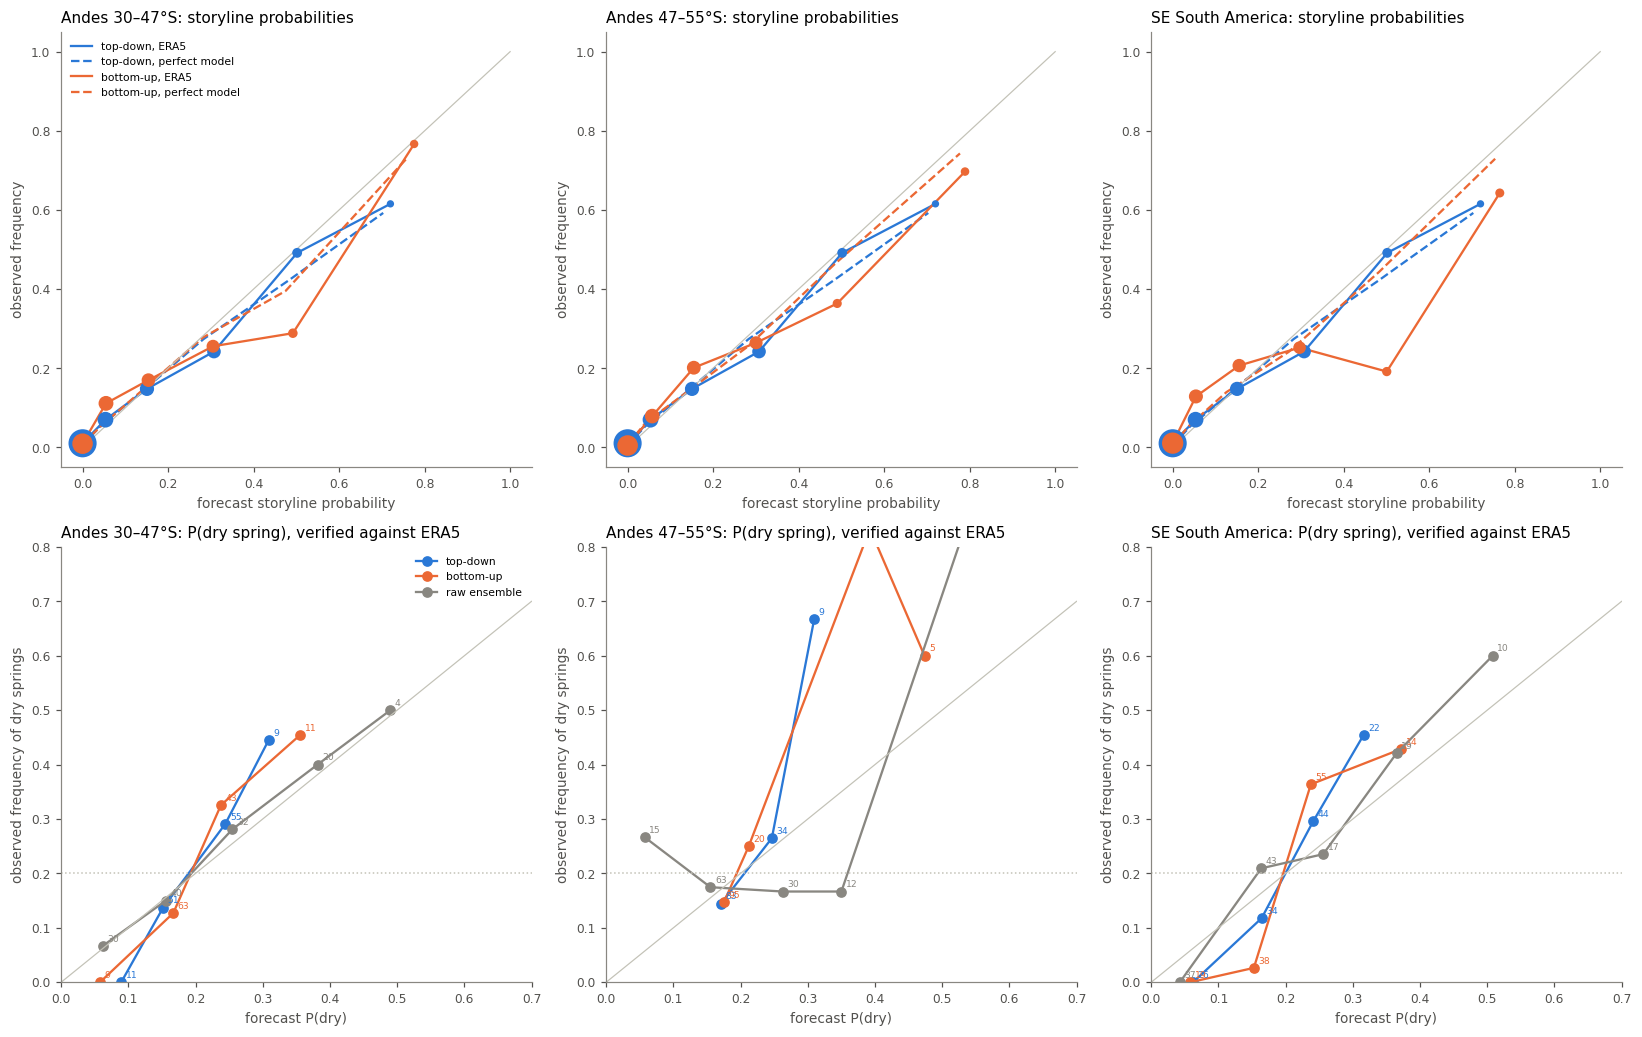

In [40]:
SB = [-0.001, 0.0001, 0.08, 0.2, 0.4, 0.6, 1.0]
DB = [0, 0.1, 0.2, 0.3, 0.45, 1.0]
KCOL = {"top-down": "#2a78d6", "bottom-up": "#eb6834", "raw ensemble": "#898781"}


def rel_points(p, o, bins):
    g = pd.DataFrame(dict(p=p, o=o)).groupby(pd.cut(p, bins, include_lowest=True), observed=True)
    return g.p.mean().values, g.o.mean().values, g.size().values


fig, axes = plt.subplots(2, NR, figsize=(5 * NR, 9.5))
for j, r in enumerate(REGIONS):
    ax = axes[0, j]
    for kind in ["top-down", "bottom-up"]:
        for v, ls in zip(VER[(r, kind)], ["-", "--"]):
            x, y, n = rel_points(np.concatenate(v.p.values), np.concatenate(v.o.values), SB)
            ax.plot(x, y, ls=ls, color=KCOL[kind], lw=1.5, label=f"{kind}, {'ERA5' if ls == '-' else 'perfect model'}")
            if ls == "-":
                ax.scatter(x, y, s=10 + n / 3, color=KCOL[kind], zorder=3)
    ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=0.8)
    ax.set_title(f"{REGIONS[r]['name']}: storyline probabilities", loc="left")
    ax.set_xlabel("forecast storyline probability"); ax.set_ylabel("observed frequency")
    ax = axes[1, j]
    vo_td, vo_bu = VER[(r, "top-down")][0], VER[(r, "bottom-up")][0]
    for lab, p, o in [("top-down", vo_td.pdry_story, vo_td.dry), ("bottom-up", vo_bu.pdry_story, vo_bu.dry),
                      ("raw ensemble", vo_td.pdry_ens, vo_td.dry)]:
        x, y, n = rel_points(p.values, o.values, DB)
        ax.plot(x, y, marker="o", color=KCOL[lab], lw=1.5, label=lab)
        for xi, yi, ni in zip(x, y, n):
            ax.annotate(str(ni), (xi, yi), xytext=(3, 3), textcoords="offset points", fontsize=6, color=KCOL[lab])
    ax.axhline(DRY_Q, color="#c3c2b7", ls=":", lw=1)
    ax.plot([0, 0.7], [0, 0.7], color="#c3c2b7", lw=0.8)
    ax.set_xlim(0, 0.7); ax.set_ylim(0, 0.8)
    ax.set_title(f"{REGIONS[r]['name']}: P(dry spring), verified against ERA5", loc="left")
    ax.set_xlabel("forecast P(dry)"); ax.set_ylabel("observed frequency of dry springs")
axes[0, 0].legend(fontsize=7); axes[1, 0].legend(fontsize=7)
fig.tight_layout(); savefig(fig, "fig25_topdown_vs_bottomup_reliability")

**Are the large-scale driver (top-down) storylines more reliable? No: the two are equally reliable.**

* **Reliability is similar.** In both, storylines with no or few members almost never happen (top row, left end on the
  diagonal), so both can discard storylines safely. At high probabilities both are somewhat overconfident.
* **Storyline probabilities.** Against ERA5 the two score the same (BSS against climatology 0.15–0.20 bottom-up, 0.18 top-down;
  intervals of about ±0.1). In the perfect model the bottom-up probabilities score higher (0.23–0.28 against 0.20, intervals barely
  overlapping in the southern Andes and SESA). This is mostly about *where the categories are cut*: the bottom-up clusters line up with
  ENSO and IOD, which a June–August forecast predicts, while the top-down storylines are also split by the SPV sign, which is not
  predictable at these leads (Section 8). It is not evidence that bottom-up storylines carry more physics.
* **For the dry-spring probability, it does not matter which storylines are used** (bottom row and the table: BSS 0.06–0.12 for both
  against ERA5, intervals overlapping everywhere). In the perfect model, routing the forecast through either kind of storyline **beats
  the raw ensemble in both Andes boxes** (BSS 0.02–0.04 against 0.00–0.02): the storyline's P(dry), estimated from the whole hindcast,
  filters the sampling noise of the ensemble. In SESA the raw ensemble is as good or slightly better (0.065 against 0.056–0.058, and
  0.18 against 0.11–0.12 against ERA5, intervals overlapping).

So the choice between top-down and bottom-up storylines should be made for interpretation (drivers one can act on and run
experiments with, against clusters that describe what dry springs look like), not for forecast reliability.

## 10. Gaps: the driest storylines that the hindcast samples poorly, and targeted experiments

**Question.** Which storylines lead to the driest springs, and where is the hindcast too thin (or too biased) to say how
dry they get? Those are the targets for new model experiments.

**Definitions** (settled before running):
* **very dry** = below the 5th percentile of the pooled hindcast springs of that region (a 1-in-20 spring; climatological
  probability 0.05). "Dry" (20th percentile) is kept for comparison;
* **storylines** = the 12 of Section 8 (ENSO phase including neutral × IOD–SPV sign quadrant), because half of the dry springs
  have neutral ENSO (Section 9); plus **compound sub-storylines**: each storyline split by the tercile of the unforced
  S-SAM + A-SAM term (Section 6);
* **how extreme**: the very-dry risk ratio P(very dry | storyline) / 0.05, and the storyline's own 5th percentile of P (σ);
* **how well sampled**: the 90 % bootstrap interval (over years) of P(very dry), the number of very-dry springs and the
  number of *years* they come from, and the **effective sample size** $n_\mathrm{eff} = p(1-p)/\mathrm{Var}_\mathrm{boot}(p)$,
  which counts how many independent springs the storyline is worth once members of the same year are allowed to be alike;
* **members needed**: the springs needed to know P(very dry) to ±25 % of its value (90 % level),
  $n_\mathrm{eff}^{*} = 1.645^2 (1-p)/(0.25^2 p)$, turned into members with the storyline's own ratio $n/n_\mathrm{eff}$.

In [41]:
VDRY_Q = 0.05
REL_TARGET = 0.25
Z90 = 1.645
for r in REGIONS:
    df[f"vdry_{r}"] = df[f"P_{r}_z"] < df[f"P_{r}_z"].quantile(VDRY_Q)
    df[f"{r}_unforced"] = df[f"{r}_S_SAM unforced"] + df[f"{r}_A_SAM unforced"]       # SAM only
    df[f"{r}_drivers_all"] = df[f"{r}_direct"] + sum(df[f"{r}_{m} forced"] for m in MEDS)


def tail_stats(sel, r):
    """Tail statistics of the springs selected by the boolean Series sel (index of df)."""
    d = df[sel]
    p = d[f"vdry_{r}"].mean()
    bp = np.array([df[f"vdry_{r}"].iloc[ix][sel.iloc[ix].values].mean() for ix in BOOT_IDX])
    bq = np.array([np.nanpercentile(df[f"P_{r}_z"].iloc[ix][sel.iloc[ix].values], 5)
                   if sel.iloc[ix].sum() > 20 else np.nan for ix in BOOT_IDX])
    var = np.nanvar(bp)
    n_eff = p * (1 - p) / var if var > 0 else np.nan
    need_eff = Z90 ** 2 * (1 - p) / (REL_TARGET ** 2 * p) if p > 0 else np.inf
    n_eff = min(n_eff, len(d))                        # design effect >= 1
    ratio = len(d) / n_eff if n_eff > 0 else np.nan
    return dict(n=len(d), share=len(d) / len(df), Pdry=d[f"dry_{r}"].mean(), Pvdry=p,
                Pvdry_lo=np.nanpercentile(bp, 5), Pvdry_hi=np.nanpercentile(bp, 95), risk_ratio=p / VDRY_Q,
                q05=np.percentile(d[f"P_{r}_z"], 5), q05_lo=np.nanpercentile(bq, 5), q05_hi=np.nanpercentile(bq, 95),
                n_vdry=int(d[f"vdry_{r}"].sum()),
                years_vdry=d[d[f"vdry_{r}"]].index.get_level_values("year").nunique(),
                share_of_all_vdry=d[f"vdry_{r}"].sum() / df[f"vdry_{r}"].sum(),
                n_eff=n_eff, rel_ci=(np.nanpercentile(bp, 95) - np.nanpercentile(bp, 5)) / 2 / p if p > 0 else np.nan,
                members_needed=need_eff * ratio, extra_members=max(need_eff * ratio - len(d), 0))


GAPS = {}
for r in REGIONS:
    t1, t2 = df[f"{r}_unforced"].quantile([1 / 3, 2 / 3])
    for s_ in STORIES:
        base = df.story == s_
        GAPS[(r, s_, "all")] = tail_stats(base, r)
        GAPS[(r, s_, "drying SAM")] = tail_stats(base & (df[f"{r}_unforced"] < t1), r)
GAPS = pd.DataFrame(GAPS).T
GAPS.index.names = ["region", "storyline", "unforced SAM"]
GAPS.to_csv(OUT / "enso_sam_extreme_storyline_gaps.csv")
cols = ["n", "Pvdry", "Pvdry_lo", "Pvdry_hi", "risk_ratio", "q05", "n_vdry", "years_vdry", "share_of_all_vdry",
        "n_eff", "rel_ci", "members_needed", "extra_members"]
top = (GAPS.xs("all", level="unforced SAM").astype(float).sort_values(["Pvdry"], ascending=False)
       .groupby(level="region", group_keys=False).head(5))
top[cols].round(2)

,,n,Pvdry,Pvdry_lo,Pvdry_hi,risk_ratio,q05,n_vdry,years_vdry,share_of_all_vdry,n_eff,rel_ci,members_needed,extra_members
region,storyline,,,,,,,,,,,,,
AndesS,El Niño | IOD+ / strong SPV,319.0,0.14,0.10,0.18,2.76,-2.09,44.0,12.0,0.24,157.80,0.32,547.03,228.03
AndesN,La Niña | IOD+ / strong SPV,119.0,0.11,0.07,0.15,2.18,-1.80,13.0,9.0,0.07,119.00,0.35,353.03,234.03
SESA,La Niña | IOD− / strong SPV,498.0,0.11,0.07,0.15,2.17,-1.94,54.0,14.0,0.30,190.25,0.34,931.86,433.86
AndesN,La Niña | IOD− / strong SPV,498.0,0.10,0.08,0.13,2.09,-1.78,52.0,17.0,0.29,498.00,0.20,371.35,0.00
SESA,La Niña | IOD+ / strong SPV,119.0,0.10,0.05,0.16,2.02,-2.00,12.0,6.0,0.07,82.14,0.55,559.27,440.27
AndesS,El Niño | IOD− / strong SPV,96.0,0.09,0.04,0.16,1.88,-1.81,9.0,6.0,0.05,66.77,0.61,601.76,505.76
SESA,La Niña | IOD+ / weak SPV,134.0,0.09,0.04,0.14,1.79,-1.87,12.0,7.0,0.07,77.54,0.58,760.73,626.73
AndesN,Neutral | IOD− / strong SPV,541.0,0.09,0.07,0.11,1.74,-1.70,47.0,22.0,0.26,391.88,0.26,628.23,87.23
AndesS,El Niño | IOD+ / weak SPV,275.0,0.08,0.05,0.13,1.67,-1.83,23.0,8.0,0.13,121.19,0.49,1076.48,801.48


**The extreme storylines and how well they are sampled.** Left: the very-dry risk ratio of each storyline (bar, 90 %
interval) against its number of very-dry springs; open markers: the very-dry springs come from fewer than 10 distinct years,
so the tail is poorly constrained. Right: the same for the compound sub-storylines (storyline + drying unforced SAM).
Labels: the storylines with risk ratio above 1.5.

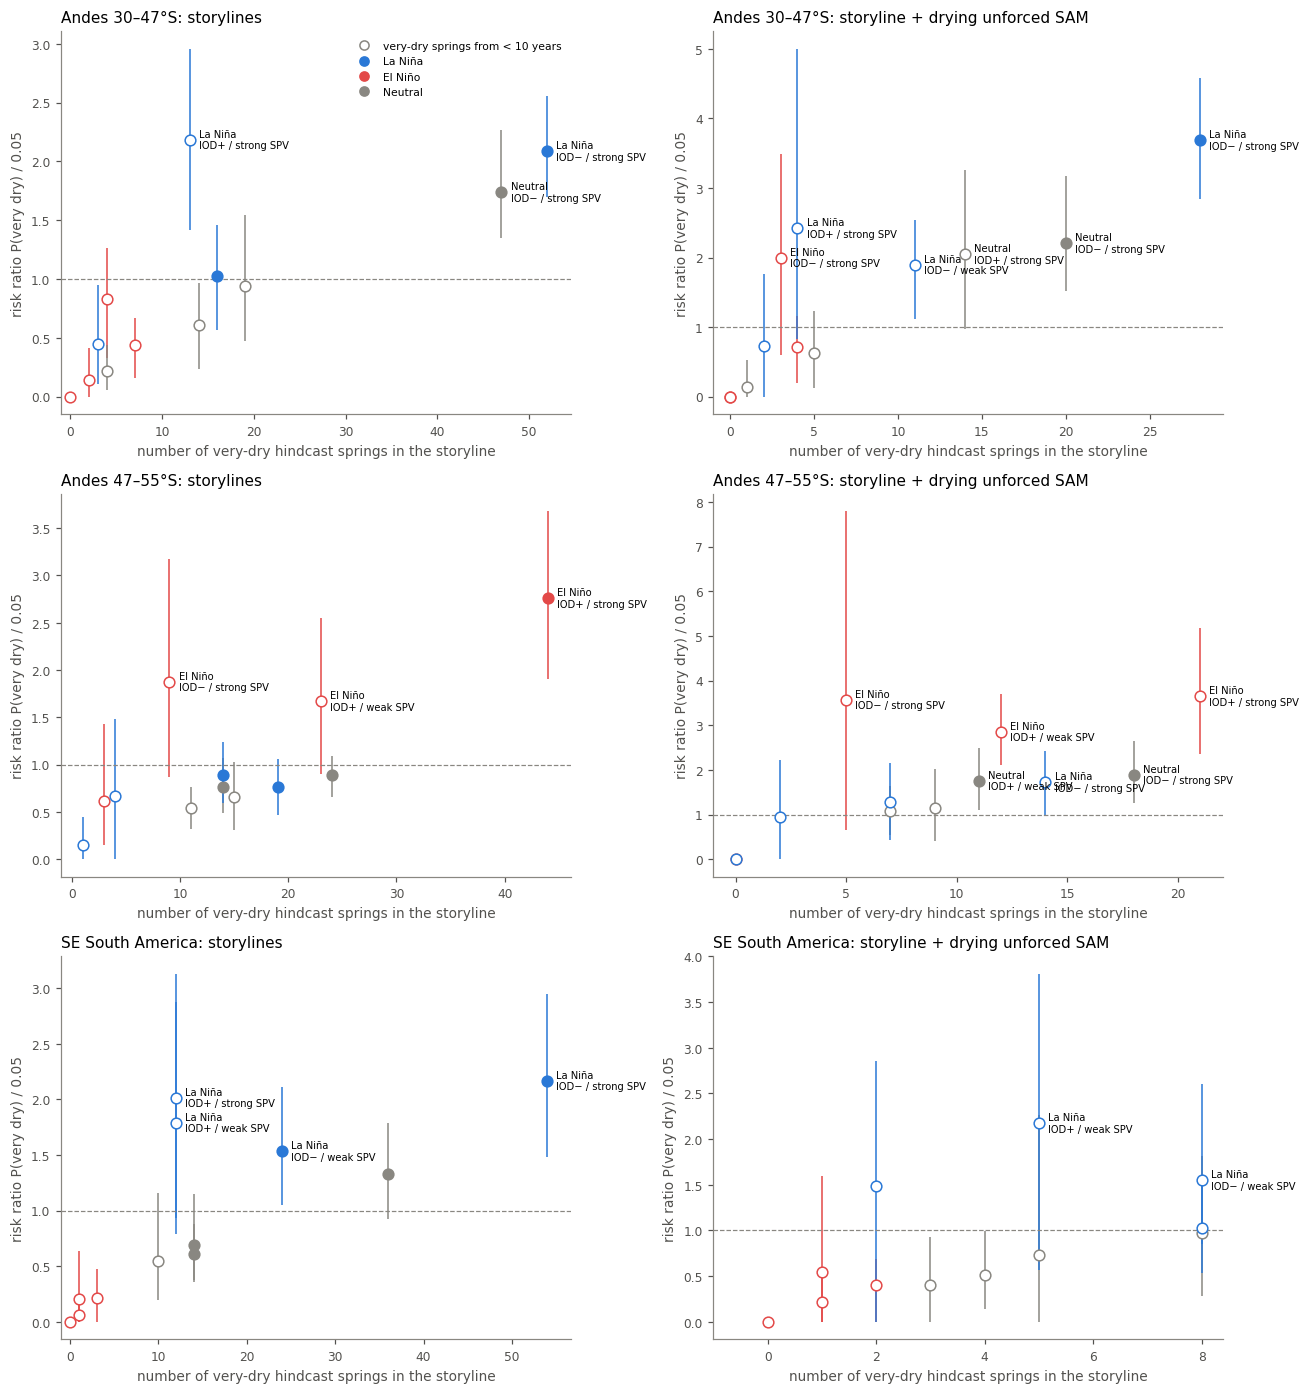

In [42]:
fig, axes = plt.subplots(NR, 2, figsize=(12, 4.25 * NR))
for i, r in enumerate(REGIONS):
    for j, lvl in enumerate(["all", "drying SAM"]):
        ax = axes[i, j]
        g = GAPS.xs((r, lvl), level=("region", "unforced SAM")).astype(float)
        for s_, row in g.iterrows():
            ph = s_.split(" | ")[0]
            col = PCOL.get(ph, "#898781")
            thin = row.years_vdry < 10
            ax.errorbar(row.n_vdry, row.risk_ratio, yerr=[[row.risk_ratio - row.Pvdry_lo / VDRY_Q],
                                                         [row.Pvdry_hi / VDRY_Q - row.risk_ratio]],
                        fmt="o", color=col, mfc="white" if thin else col, ms=7, lw=1)
            if row.risk_ratio > 1.5:
                ax.annotate(s_.replace(" | ", "\n"), (row.n_vdry, row.risk_ratio), xytext=(6, 0),
                            textcoords="offset points", fontsize=6.5, va="center")
        ax.axhline(1, color="#898781", ls="--", lw=0.8)
        ax.set_xlim(left=-1)
        ax.set_xlabel("number of very-dry hindcast springs in the storyline")
        ax.set_ylabel("risk ratio P(very dry) / 0.05")
        ax.set_title(f"{REGIONS[r]['name']}: {'storylines' if lvl == 'all' else 'storyline + drying unforced SAM'}",
                     loc="left")
axes[0, 0].plot([], [], "o", color="#898781", mfc="white", label="very-dry springs from < 10 years")
axes[0, 0].plot([], [], "o", color=PCOL["La Niña"], label="La Niña"); axes[0, 0].plot([], [], "o", color=PCOL["El Niño"], label="El Niño")
axes[0, 0].plot([], [], "o", color="#898781", label="Neutral")
axes[0, 0].legend(fontsize=7, loc="upper right")
fig.tight_layout(); savefig(fig, "fig19_extreme_storyline_sampling")

**Where in driver space is the very-dry risk high but the hindcast empty?** A logistic regression of "very dry" on the
standardised ENSO, IOD and SPV (with their pairwise products) gives the risk everywhere, including where there are few
springs. Contours: modelled risk ratio. Shading: number of hindcast springs per 0.5σ × 0.5σ cell (the third driver
averaged over). **Hatched**: risk ratio ≥ 2 and fewer than 10 springs, i.e. the dangerous corners the hindcast hardly samples;
whatever the hindcast says there is extrapolation. Stars: ERA5 very-dry springs (below the 5th percentile of ERA5 is only
2 springs, so the ERA5 springs below the 15th percentile are shown).

x_driver     x y_driver     y  risk_ratio  n_springs
region cell                                                     
AndesN 0        ENSO -2.25      SPV  0.25        2.45          8
       1        ENSO -2.25      SPV  1.25        4.20          7
       2        ENSO -2.25      SPV  1.75        5.37          7
       3        ENSO -2.25      SPV  2.25        6.73          1
       4        ENSO -1.75      SPV  2.25        5.71          3
       5        ENSO -1.25      SPV  1.75        3.71          5
       6        ENSO -1.25      SPV  2.25        4.79          2
       7        ENSO -0.75      SPV  2.25        3.98          1
       8        ENSO -0.25      SPV  2.25        3.28          8
       9        ENSO  0.25      SPV  2.25        2.68          3
       10       ENSO  0.75      SPV  2.25        2.18          1
AndesS 0        ENSO  1.25      SPV  1.75        2.65          7
       1        ENSO  1.25      SPV  2.25        3.02          1
       2        ENSO  1.75      SPV  1.25        3.26          8
       3        ENSO  1.75      SPV  1.75        3.83          4
       4        ENSO  1.75      SPV  2.25        4.47          0
       5        ENSO  2.25      SPV -0.75        2.03          6
       6        ENSO  2.25      SPV  1.75        5.37          3
       7        ENSO  2.25      SPV  2.25        6.35          0
SESA   0        ENSO -2.25      IOD  0.25        5.58          8
       1        ENSO -2.25      IOD  0.75        6.68          3
       2        ENSO -2.25      IOD  1.25        7.87          0
       3        ENSO -2.25      IOD  1.75        9.14          1
       4        ENSO -2.25      IOD  2.25       10.44          0
       5        ENSO -1.75      IOD  0.75        4.28          7
       6        ENSO -1.75      IOD  1.25        4.88          3
       7        ENSO -1.75      IOD  1.75        5.54          3
       8        ENSO -1.75      IOD  2.25        6.26          1
       9        ENSO -1.25      IOD  1.25        2.76          5
       10       ENSO -1.25      IOD  1.75        2.96          0
       11       ENSO -1.25      IOD  2.25        3.18          1

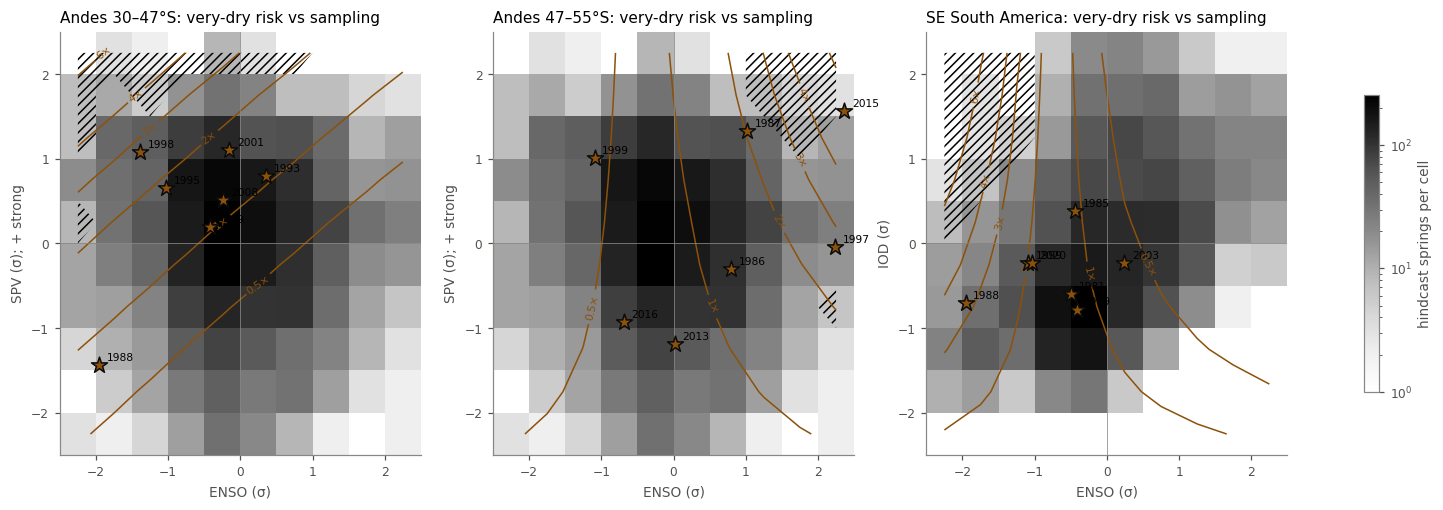

In [43]:
from sklearn.linear_model import LogisticRegression

PLANES = {"AndesN": ("ENSO", "SPV"), "AndesS": ("ENSO", "SPV"), "SESA": ("ENSO", "IOD")}
edges = np.arange(-2.5, 2.51, 0.5)                 # beyond ±2.5σ the regression is pure extrapolation
mid = (edges[:-1] + edges[1:]) / 2
LOGI, GAPCELLS = {}, {}
fig, axes = plt.subplots(1, NR, figsize=(6 * NR, 5))
for ax, r in zip(axes, REGIONS):
    X = df[ZV].values
    Xi = np.column_stack([X, X[:, 0] * X[:, 1], X[:, 0] * X[:, 2], X[:, 1] * X[:, 2]])
    lr = LogisticRegression(C=10, max_iter=1000).fit(Xi, df[f"vdry_{r}"].values)
    LOGI[r] = lr
    a, b = PLANES[r]
    ia, ib = DRIVERS.index(a), DRIVERS.index(b)
    ic = [k for k in range(3) if k not in (ia, ib)][0]
    H, _, _ = np.histogram2d(df[f"{a}_z"], df[f"{b}_z"], bins=[edges, edges])
    # risk on the grid, averaged over the hindcast distribution of the third driver
    AA, BB = np.meshgrid(mid, mid, indexing="ij")
    risk = np.zeros_like(AA)
    third = df[ZV[ic]].sample(300, random_state=0).values
    for c in third:
        G = np.zeros((AA.size, 3)); G[:, ia] = AA.ravel(); G[:, ib] = BB.ravel(); G[:, ic] = c
        Gi = np.column_stack([G, G[:, 0] * G[:, 1], G[:, 0] * G[:, 2], G[:, 1] * G[:, 2]])
        risk += lr.predict_proba(Gi)[:, 1].reshape(AA.shape) / len(third)
    rr = risk / VDRY_Q
    pc = ax.pcolormesh(edges, edges, H.T, cmap="Greys", norm=mcolors.LogNorm(1, H.max()), shading="flat")
    cs = ax.contour(mid, mid, rr.T, levels=[0.5, 1, 2, 3, 4, 6], colors="#8c510a", linewidths=1)
    ax.clabel(cs, fontsize=7, fmt="%g×")
    gap = (rr >= 2) & (H < 10)
    GAPCELLS[r] = pd.DataFrame([dict(x_driver=a, x=mid[i], y_driver=b, y=mid[j], risk_ratio=rr[i, j],
                                     n_springs=int(H[i, j]))
                                for i, j in zip(*np.where(gap))])
    ax.contourf(mid, mid, gap.T.astype(float), levels=[0.5, 1.5], hatches=["////"], colors="none")
    lo15 = obs[f"P_{r}_z"].quantile(0.15)
    o = obs[obs[f"P_{r}_z"] < lo15]
    ax.scatter(o[f"{a}_z"], o[f"{b}_z"], marker="*", s=120, color="#8c510a", edgecolor=INK, zorder=4)
    for y, row in o.iterrows():
        ax.annotate(str(y), (row[f"{a}_z"], row[f"{b}_z"]), xytext=(5, 3), textcoords="offset points", fontsize=7)
    ax.axhline(0, color="#898781", lw=0.5); ax.axvline(0, color="#898781", lw=0.5)
    ax.set_xlabel(f"{a} (σ)"); ax.set_ylabel(f"{b} (σ)" + ("; + strong" if b == "SPV" else ""))
    ax.set_title(f"{REGIONS[r]['name']}: very-dry risk vs sampling", loc="left")
fig.colorbar(pc, ax=axes, shrink=0.7, label="hindcast springs per cell")
savefig(fig, "fig20_risk_vs_sampling")
pd.concat(GAPCELLS, names=["region", "cell"]).round(2)

**Is the dry tail itself under-represented?** Three model checks that decide whether more members of the *same* model would
be enough:

1. **UNSEEN check**: how many hindcast springs are drier than the driest ERA5 spring, and where the driest ERA5 spring sits in
   the hindcast distribution;
2. **driver spread**: the standard deviation of the observed drivers in model units (Section 8) — below 1 means SEAS5 is
   over-dispersive, above 1 that it does not reach the observed extremes;
3. **teleconnection strength**: the regression slope of P on each driver in SEAS5 against ERA5 (Section 3). A weaker
   slope means the model's driver extremes produce too little drying, and new members of the same model would inherit that.

In [44]:
chk = {}
for r in REGIONS:
    omin = obs_mz[6][f"P_{r}_z"].min()
    row = dict(driest_ERA5_year=int(obs_mz[6][f"P_{r}_z"].idxmin()), driest_ERA5_sigma=omin,
               hindcast_springs_drier=int((df[f"P_{r}_z"] < omin).sum()),
               driest_ERA5_percentile=stats.percentileofscore(df[f"P_{r}_z"], omin))
    for v in DRIVERS:
        row[f"obs_sd_{v}_model_units"] = np.nanmean([obs_mz[m][f"{v}_z"].std() for m in INITS])
        bm = np.polyfit(df[f"{v}_z"], df[f"P_{r}_z"], 1)[0]
        ok = obs[[f"{v}_z", f"P_{r}_z"]].dropna()
        bo = np.polyfit(ok[f"{v}_z"], ok[f"P_{r}_z"], 1)[0]
        row[f"slope_{v}_SEAS5"], row[f"slope_{v}_ERA5"] = bm, bo
    chk[r] = row
pd.DataFrame(chk).round(2)

,AndesN,AndesS,SESA
driest_ERA5_year,1989.00,2015.00,2020.00
driest_ERA5_sigma,-1.90,-1.84,-2.61
hindcast_springs_drier,49.00,109.00,13.00
driest_ERA5_percentile,1.35,3.01,0.36
obs_sd_ENSO_model_units,1.19,1.19,1.19
slope_ENSO_SEAS5,0.33,-0.22,0.49
slope_ENSO_ERA5,0.56,-0.34,0.58
obs_sd_IOD_model_units,0.62,0.62,0.62
slope_IOD_SEAS5,0.23,-0.08,0.25
slope_IOD_ERA5,0.42,-0.31,0.21


### 10.1 The gaps

**Which storylines are the most extreme?** Ranked by very-dry risk (Section 10 table and fig19):
* **Southern Andes**: El Niño with IOD+ and a strong vortex (risk ratio 2.8; 24 % of all very-dry springs there), then El Niño
  IOD−/strong SPV (1.9) and IOD+/weak SPV (1.7); 3.5–3.6 with a drying unforced SAM.
* **Northern Andes**: La Niña with a strong vortex. IOD+/strong SPV (2.2) and IOD−/strong SPV (2.1; 29 % of all very-dry springs),
  then neutral IOD−/strong SPV (1.7). With a drying unforced SAM on top, La Niña IOD−/strong SPV reaches 3.5 (P(very dry) = 0.18).
* **SESA**: all La Niña storylines. La Niña IOD−/strong SPV (2.2; 30 % of all very-dry springs), IOD+/strong SPV (2.0) and IOD+/weak
  SPV (1.8). Their 5th percentile of P is −1.9 to −2.0σ.

**Which of these are poorly sampled?** Three gaps, in order of importance:

1. **La Niña with a strong vortex (northern Andes) and El Niño with a strong vortex (southern Andes).** The regression puts the
   very-dry risk at 3.7–6.7 times climatology in the northern-Andes corner ENSO < −1σ, SPV > +1σ, and at 2.7–6.4 times in the
   southern-Andes corner ENSO > +1σ, SPV > +1σ, but the hindcast has ≤ 8 springs per cell there (fig20, hatched). The observed
   **2015** (strong El Niño, very strong vortex), the driest observed spring in the southern Andes, lies in that corner, and so do
   the strong-vortex La Niña springs **2020–2022**. SEAS5 also under-samples the vortex: the observed SPV varies 1.34 times more than
   SEAS5's at these leads.
2. **La Niña with a positive IOD**, in SESA and in the northern Andes. These are among the highest-risk storylines (risk ratio 1.8–2.2),
   but they hold only 119–134 springs, with very-dry springs from 6–9 years. In nature La Niña usually comes with IOD−, so the
   combination is rare in any record. In SESA the corner ENSO < −1.25σ with IOD > 0 has a modelled risk ratio of 2.8–10 and ≤ 8 springs
   per cell. SEAS5 also under-responds: its slopes of northern-Andes P on ENSO (0.33) and SPV (−0.31) are 60–75 % of ERA5's
   (0.56, −0.41).
3. **The tail inside the well-sampled storylines.** SESA La Niña IOD−/strong SPV holds 30 % of all very-dry springs, but they come
   from 14 years: its effective sample is about 190 springs out of 498, and pinning P(very dry) to ±25 % needs ~430 more members. And the
   driest observed SESA spring, **2020 (−2.6σ)**, is at the hindcast's 0.4th percentile (13 drier springs in 3618): how much drier
   a La Niña spring can get is barely sampled.

Gaps 1 and 2 are **gaps in driver space** (rare combinations): they call for experiments that *force* the drivers into those corners.
Gap 3 is a **gap in the precipitation tail** given the drivers: it calls for more members inside the storyline, preferably
targeted at the dry end.

### 10.2 Targeted experiments (design)

The experiments are written for a coupled seasonal prediction system that can be nudged and restarted (for example OpenIFS
or EC-Earth, CESM, the UM). They use the same season (SON), leads (start 1 June–1 August) and diagnostics as this notebook,
so their output can go straight into Sections 4–10. Member numbers come from the sizing cell below: enough springs to know
P(very dry) to ±25 % (90 % level), with the design effect seen in the hindcast.

| | target gap | method | arms | starts | members per arm |
|---|---|---|---|---|---|
| **E1** | Andes, strong vortex (gaps 1–2) | relax the SH stratospheric zonal-mean flow (above ~100 hPa, poleward of 40°S; zonal mean only, as in Hitchcock & Simpson 2014) towards a **strong-vortex** state (+2σ, the 2015 SON evolution) and, as a control, towards **climatology**. Troposphere and ocean free | 2 vortex states × 3 ENSO conditions (El Niño 1997/2015, neutral 2001/2008, La Niña 1998/2010) | 1 August | see sizing |
| **E2** | SESA, La Niña + IOD+ (gap 2) | **tropical SST pacemaker**: restore SST in the tropical Pacific (15°S–15°N, 170°E–coast) to La Niña anomalies and in the tropical Indian Ocean to a positive dipole, everywhere else free. Factorial: ENSO {−1σ, −2σ} × IOD {0, +1σ, +2σ}, amplitudes in observed σ (SEAS5's IOD is ~1.7 times too variable) | 6 | 1 July (IOD and ENSO well developed by SON) | see sizing |
| **E3** | tail inside the storyline (gap 3) | **ensemble boosting** (Gessner et al. 2021; Fischer et al. 2023): take the driest members of a target storyline (SESA La Niña IOD−/strong SPV; northern Andes La Niña IOD−/strong SPV and southern Andes El Niño IOD+/strong SPV, with a drying SAM) and restart each on 1 September with tiny atmospheric perturbations (round-off level), many branches per parent | 1 per target storyline | 1 Sept (and 1 Oct) | 20 parents × 50 branches |

**What each experiment answers.**
* **E1** samples the empty strong-vortex corner and, because the vortex is imposed, gives the **causal** vortex effect on
  both Andes boxes (the El Niño arms target the southern Andes, the La Niña arms the northern Andes); comparing E1 with its
  control splits the effect into the S-SAM and A-SAM paths (Section 5) without relying on regressions. It also tests the weak
  SPV → P slope in the northern Andes: if E1 gives about −0.31σ per σ against −0.41 observed, the bias is in the
  troposphere–surface coupling, and more members of the same model will not fix it. In the southern Andes the vortex's direct and
  through-SAM effects cancel in SEAS5 (Section 5); E1 tests whether that cancellation is real.
* **E2** gives P(very dry) and the dry tail for La Niña + IOD+ springs with an adequate sample, and tests the
  interaction (is a La Niña with IOD+ drier than the sum of the two?), which the linear path model cannot capture.
* **E3** answers "how dry can a La Niña spring in SESA (or a strong-vortex spring in the Andes) get?" beyond the observed record,
  at a fraction of the cost of brute-force members, because every branch starts close to an already-dry trajectory. The
  branches are not a random sample: their *probabilities* must come from E1/E2 or the hindcast, and E3 gives the intensity.

**Revision after Sections 10.3 and 11 (most dry springs have other causes).** E1 and E2 only reach the dry springs that the drivers
make: 20–21 % of the dry anomaly in the northern Andes and in SESA, 5 % in the southern Andes. So:
* **E1 and E2 are worth it for the northern Andes and SESA**, where the drivers make about a fifth of the dry anomaly;
* **E3 (ensemble boosting) is the main experiment for the southern Andes**, where the dry springs come mostly from a local
  blocking high over Patagonia (Section 10.3). Boosting from the driest members samples them whatever the drivers do; parents should
  be chosen by the high (MSLP anomaly over 45–60°S, 65–85°W) as well as by dryness;
* **add E4 for SESA: an eastern-Pacific pacemaker.** Restore SST in the far-eastern Pacific (Niño1+2) to cold anomalies (−1σ, −2σ) with
  Niño3.4 held near neutral, and the reverse, to test the ENSO-flavour effect found in SEAS5 and ERSST (partial r 0.25 in
  observations, after the drivers and the SAM). Same sizing as E2;
* **a SE Pacific SST arm for the southern Andes** (E4b): warm SE Pacific SST (40–55°S, 100–75°W), the one candidate driver that adds
  information on southern-Andes P in both SEAS5 and ERSST (partial r −0.26 and −0.26).

**Caveats.** Experiments with one model inherit its biases. The northern-Andes SPV → P slope is three quarters of the observed one, so E1 should be run in
at least two models, or its response compared with ERA5 (−0.41σ per σ) and used to rescale. Nudging the stratosphere also removes the
downward-propagation timing and any feedback from the troposphere; the control arm (nudged to climatology) separates the effect of the
nudging itself. Pacemaker SST restoring removes the coupled feedback in the restored regions.

In [45]:
def springs_needed(p, rel=REL_TARGET, z=Z90):
    return z ** 2 * (1 - p) / (rel ** 2 * p)


DEFF = {r: (GAPS.xs("all", level="unforced SAM").loc[r].astype(float).eval("n / n_eff")).median() for r in REGIONS}
design = pd.DataFrame([
    dict(experiment="E1 Andes 30–47°S strong vortex", arms=6, prior_Pvdry=0.05 * 2.5, deff=DEFF["AndesN"]),
    dict(experiment="E2 SESA La Niña + IOD+", arms=6, prior_Pvdry=0.05 * 2.5, deff=DEFF["SESA"]),
]).set_index("experiment")
design["springs_per_arm"] = [springs_needed(p) * d for p, d in zip(design.prior_Pvdry, design.deff)]
design["starts_per_arm"] = [2, 3]
design["members_per_start"] = np.ceil(design.springs_per_arm / design.starts_per_arm)
design["total_seasons"] = design.arms * design.starts_per_arm * design.members_per_start
print("design effect (median n / n_eff over the storylines):", {k: round(v, 2) for k, v in DEFF.items()})
print("E1 needs a control arm of the same size (vortex nudged to climatology).")
design.round(2)

design effect (median n / n_eff over the storylines): {'AndesN': 1.18, 'AndesS': 1.26, 'SESA': 1.45}
E1 needs a control arm of the same size (vortex nudged to climatology).


,arms,prior_Pvdry,deff,springs_per_arm,starts_per_arm,members_per_start,total_seasons
experiment,,,,,,,
E1 Andes 30–47°S strong vortex,6,0.12,1.18,357.54,2,179.0,2148.0
E2 SESA La Niña + IOD+,6,0.12,1.45,439.06,3,147.0,2646.0


### 10.3 Dry springs that ENSO, IOD and SPV do not capture

The experiments above force the three drivers, so they can only sample dry springs that those drivers produce. How many dry
springs is that? Each dry spring (below the 20th percentile) is split exactly as in Section 6 into the part set by the drivers
(direct + forced S-SAM + forced A-SAM), the unforced SAM (S + A) and the residual (everything else: other drivers and noise).
The spring is assigned to the term that contributes most to its dry anomaly:

* **drivers**: ENSO/IOD/SPV (directly or through the SAM) give the largest drying;
* **unforced SAM**: the SAM beyond what the drivers set;
* **other**: the residual. These are dry springs with a different cause.

In [46]:
CAUSES = ["drivers", "unforced SAM", "unforced SALLJ", "other"]
CCOL = {"drivers": "#2a78d6", "unforced SAM": "#e87ba4", "unforced SALLJ": "#9fd9d2", "unforced SACZ": "#9fd9d2", "other": "#898781"}
cause_tab, mean_terms = {}, {}
for r in REGIONS:
    drv = df[f"{r}_drivers_all"]
    terms = pd.DataFrame({"drivers": drv, "unforced SAM": df[f"{r}_unforced"], "unforced SALLJ": df[f"{r}_SALLJ unforced"], 
                          "other": df[f"{r}_residual"]})
    df[f"{r}_cause"] = terms.idxmin(axis=1)
    for lab, sel in [("dry", df[f"dry_{r}"]), ("very dry", df[f"vdry_{r}"])]:
        cause_tab[(r, lab)] = df.loc[sel, f"{r}_cause"].value_counts(normalize=True).reindex(CAUSES).fillna(0)
        cause_tab[(r, lab)]["drivers point to dry (> 0 drying)"] = (terms.loc[sel, "drivers"] < 0).mean()
        cause_tab[(r, lab)]["share of the anomaly from drivers"] = terms.loc[sel, "drivers"].sum() / df.loc[sel, f"P_{r}_z"].sum()
        mean_terms[(r, lab)] = terms[sel].mean()
cause_tab = pd.DataFrame(cause_tab).T
cause_tab.round(2)

drivers  unforced SAM  unforced SALLJ  other  \
AndesN dry          0.18          0.01            0.21   0.60   
       very dry     0.10          0.00            0.17   0.73   
AndesS dry          0.03          0.03            0.00   0.94   
       very dry     0.00          0.01            0.00   0.99   
SESA   dry          0.17          0.00            0.23   0.60   
       very dry     0.12          0.00            0.19   0.70   

                 drivers point to dry (> 0 drying)  \
AndesN dry                                    0.76   
       very dry                               0.83   
AndesS dry                                    0.56   
       very dry                               0.65   
SESA   dry                                    0.80   
       very dry                               0.85   

                 share of the anomaly from drivers  
AndesN dry                                    0.20  
       very dry                               0.19  
AndesS dry                                    0.05  
       very dry                               0.07  
SESA   dry                                    0.21  
       very dry                               0.19

**What do the "other" dry springs look like?** SEAS5 SON MSLP anomaly composites of the dry springs with each cause, and the
ERA5 dry springs (below the 20th percentile) whose cause is "other" when decomposed with the same SEAS5 coefficients.
A coherent pattern in the "other" composite points to a missing large-scale driver; a weak, noisy one to internal variability.

AndesN: ERA5 'other' dry springs [1988, 1989, 1993, 1995, 1998, 2001]; pattern r with the SEAS5 'other' composite: [-0.07, 0.16, 0.42, 0.5, 0.6, 0.45]
AndesS: ERA5 'other' dry springs [1986, 1987, 1991, 1997, 1999, 2000, 2013, 2015, 2016]; pattern r with the SEAS5 'other' composite: [0.32, 0.3, 0.06, 0.46, 0.28, 0.33, -0.09, 0.54, 0.11]
SESA: ERA5 'other' dry springs [1981, 1985, 1999, 2003, 2020]; pattern r with the SEAS5 'other' composite: [-0.41, 0.52, 0.7, -0.49, 0.64]


drivers  unforced SAM  unforced SALLJ  other     P  \
region year                                                       
AndesN 1983    -0.32         -0.35           -0.18  -0.11 -0.96   
       1988    -0.19          0.30            0.07  -1.23 -1.05   
       1989    -0.23         -0.00           -0.50  -0.87 -1.60   
       1993    -0.15         -0.01            0.08  -1.16 -1.24   
       1995    -0.54          0.06            0.28  -0.99 -1.19   
       1998    -0.80          0.08            0.13  -0.85 -1.44   
       2001    -0.42         -0.27            0.32  -0.98 -1.35   
       2008    -0.22         -0.19           -0.48  -0.16 -1.04   
       2020    -0.77          0.27            0.34  -0.76 -0.92   
AndesS 1986    -0.15         -0.22            0.08  -1.11 -1.40   
       1987    -0.21          0.11            0.17  -1.27 -1.20   
       1991    -0.23          0.13            0.02  -0.77 -0.86   
       1997    -0.45          0.36           -0.16  -1.06 -1.31   
       1999     0.25          0.05            0.03  -1.54 -1.20   
       2000     0.12          0.52           -0.07  -1.37 -0.80   
       2013    -0.02          0.09            0.05  -1.26 -1.13   
       2015    -0.51          0.52           -0.07  -1.84 -1.91   
       2016     0.11         -0.09            0.16  -1.69 -1.51   
SESA   1981    -0.26         -0.07           -0.03  -1.04 -1.39   
       1985    -0.23         -0.02           -0.31  -0.94 -1.49   
       1988    -0.85          0.09            0.08  -0.31 -1.00   
       1989    -0.23          0.09           -0.56  -0.29 -0.99   
       1999    -0.60         -0.01           -0.14  -0.93 -1.68   
       2003     0.14          0.01            0.02  -1.10 -0.94   
       2016    -0.29          0.07           -0.71   0.09 -0.84   
       2020    -0.61         -0.07            0.38  -1.81 -2.12   
       2022    -0.46          0.04           -0.85   0.42 -0.84   

                      cause  
region year                  
AndesN 1983    unforced SAM  
       1988           other  
       1989           other  
       1993           other  
       1995           other  
       1998           other  
       2001           other  
       2008  unforced SALLJ  
       2020         drivers  
AndesS 1986           other  
       1987           other  
       1991           other  
       1997           other  
       1999           other  
       2000           other  
       2013           other  
       2015           other  
       2016           other  
SESA   1981           other  
       1985           other  
       1988         drivers  
       1989  unforced SALLJ  
       1999           other  
       2003           other  
       2016  unforced SALLJ  
       2020           other  
       2022  unforced SALLJ

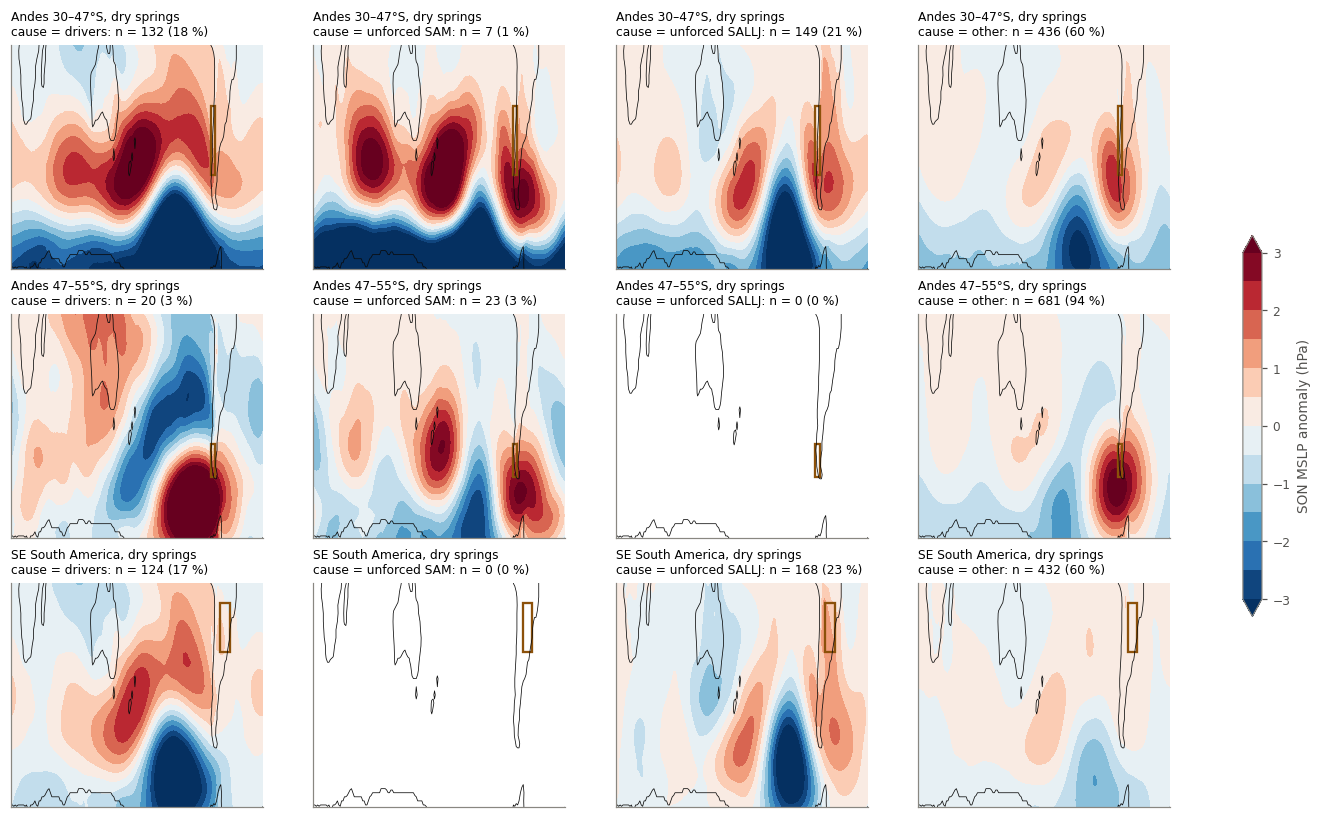

In [47]:
fig, axes = plt.subplots(NR, len(CAUSES), figsize=(17, 3 * NR))
lev = np.arange(-3, 3.5, 0.5)
OTHER = {}
for i, r in enumerate(REGIONS):
    for j, cz in enumerate(CAUSES):
        sel = df[f"dry_{r}"] & (df[f"{r}_cause"] == cz)
        c = composite(df[sel])
        OTHER[(r, cz)] = c
        ax = axes[i, j]
        cf = ax.contourf(lon_m, lat_m, c.values, levels=lev, cmap="RdBu_r", extend="both")
        ax.contour(lon_m, lat_m, land, levels=[0.5], colors=INK, linewidths=0.5)
        b = REGIONS[r]
        ax.add_patch(plt.Rectangle((b["lon"][0], b["lat"][0]), b["lon"][1] - b["lon"][0], b["lat"][1] - b["lat"][0],
                                   fill=False, ec="#8c510a", lw=1.5))
        ax.set_ylim(-70, -15); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{REGIONS[r]['name']}, dry springs\ncause = {cz}: n = {sel.sum()} "
                     f"({100 * sel.sum() / df[f'dry_{r}'].sum():.0f} %)", loc="left", fontsize=8)
fig.colorbar(cf, ax=axes, shrink=0.5, label="SON MSLP anomaly (hPa)")
savefig(fig, "fig21_dry_springs_by_cause_mslp")

obs_cause = {}
for r in REGIONS:
    o = obs.dropna(subset=[f"{m}_z" for m in MEDS])
    drv = o[f"{r}_direct"] + sum(o[f"{r}_{m} forced"] for m in MEDS)
    unf = o[f"{r}_S_SAM unforced"] + o[f"{r}_A_SAM unforced"]
    terms = pd.DataFrame({"drivers": drv, "unforced SAM": unf, "unforced SALLJ": o[f"{r}_SALLJ unforced"], 
                          "other": o[f"{r}_residual"]})
    dry = o[f"P_{r}_z"] < obs[f"P_{r}_z"].quantile(DRY_Q)
    obs_cause[r] = terms[dry].assign(P=o.loc[dry, f"P_{r}_z"], cause=terms[dry].idxmin(axis=1)).round(2)
    oth = obs_cause[r].index[obs_cause[r].cause == "other"]
    if len(oth):
        print(f"{r}: ERA5 'other' dry springs {list(oth)}; pattern r with the SEAS5 'other' composite:",
              [round(pattern_corr(OTHER[(r, 'other')], e5_a.sel(year=y)), 2) for y in oth])
pd.concat(obs_cause, names=["region", "year"])

**Most dry springs are not made by ENSO, IOD or SPV, and how many depends on the region.** The drivers (with their effect through
the SAM and the SACZ) supply **20 % of the dry anomaly in the northern Andes and 21 % in SESA, but only 5 % in the southern Andes**.
The residual is the largest drying term in 76 % (northern Andes), 95 % (southern Andes) and 83 % (SESA) of the dry springs.
**The SACZ does not account for the "other" dry springs**: its unforced part is the largest drying term in at most 2 % of them
(the unforced SAM in at most 2 %). In ERA5, 6 of 9 observed northern-Andes dry springs are residual-dominated (1998 and 2020 are
driver-made, 1983 unforced SACZ), all 9 southern-Andes ones (including 2015) and 7 of 9 in SESA (including 2020; 1988 and 2022 are
driver-made).
(A caution: the residual has the largest variance, so it tends to be the largest term in any spring; the share of the anomaly is
the more robust number.)

**The "other" dry springs have a clear local circulation** (fig21, right): a ridge over central-southern Chile for the northern
Andes, a closed high over southern Patagonia for the southern Andes, each with a trough to the south-west. They are regional, not
the zonally symmetric SAM, so neither S-SAM nor A-SAM captures them. Most ERA5 "other" springs resemble them (pattern r up to 0.53
in the north and 0.54 in the south, a few near 0). In SESA the "other" composite is weak (≤ 1.5 hPa) and the ERA5 matches are mixed
(−0.44 to 0.63), closer to noise plus several causes.

**Is there a predictable source behind the "other" dry springs?** The part of P that ENSO, IOD and SPV do not explain,
$P - \hat P_D$ (unforced SAM + residual), is correlated with SEAS5 SON SST at every ocean point, over the 3618 springs.
Two versions:

* **between forecasts**: the ensemble means of each forecast (126 = 42 years × 3 inits). A pattern here is a signal shared by
  all members of a forecast, i.e. something the forecast *can* predict — a candidate extra driver;
* **within forecasts**: each member's deviation from its own ensemble mean. A pattern here is unpredictable at these leads
  (it differs between members); it is usually the ocean responding to the same atmospheric anomaly.

Contours/shading: correlation; dots: 90 % bootstrap interval over years excludes 0 (between-forecast map only).
SEAS5 SST: `storylines_data/sst_son_seas5_SH_1981-2022.nc` (made by `Codes/extract_msl_seas5.py --var sst --n_members 51 --years 1981 2022`), 30°N–90°S.

AndesN         AndesS           SESA       
                           between within between within between within
max r                         0.50   0.25    0.50   0.40    0.68   0.21
min r                        -0.41  -0.41   -0.45  -0.44   -0.46  -0.27
share of ocean significant    0.19    NaN    0.28    NaN    0.40    NaN

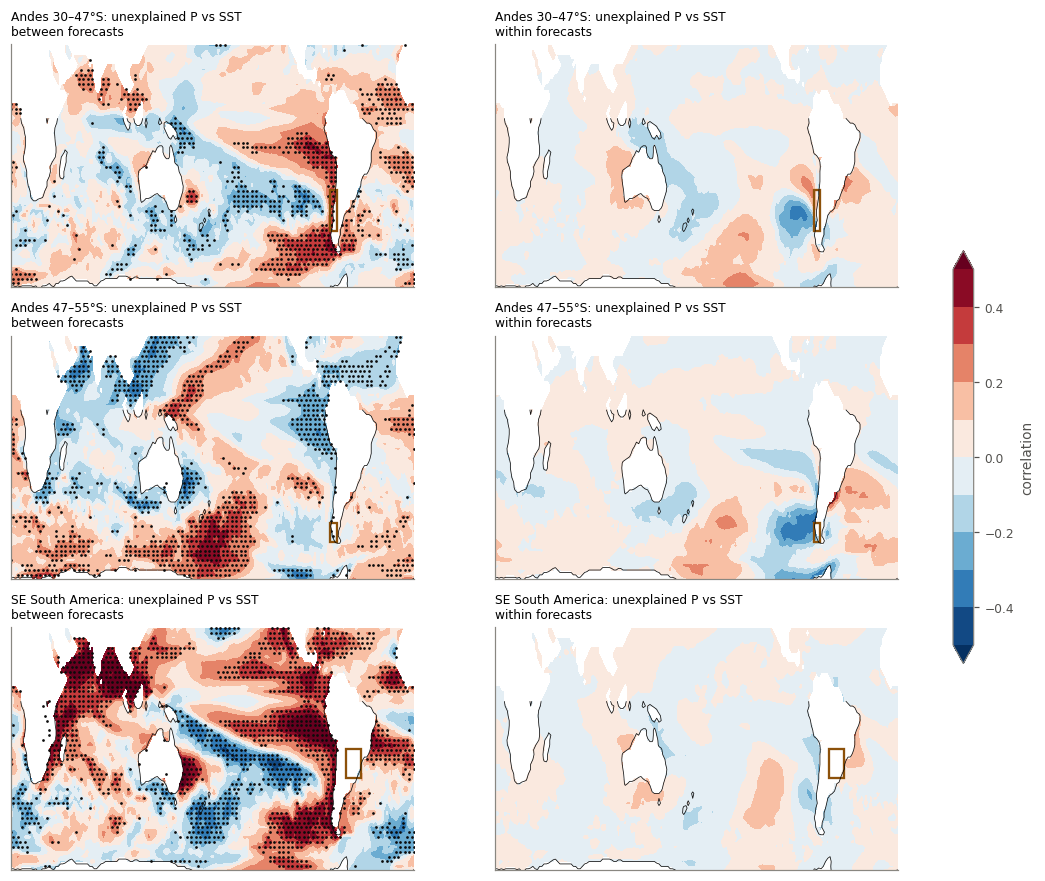

In [48]:
sst = xr.open_dataset(DATA / "sst_son_seas5_SH_1981-2022.nc")["sst"]
sst = sst.assign_coords(year=("forecast_reference_time", sst.init_year.values))
s_st = sst.stack(s=("forecast_reference_time", "number")).transpose("s", "latitude", "longitude")
key = pd.MultiIndex.from_arrays([s_st.year.values, s_st.init_month.values, s_st.number.values],
                                names=["year", "init_month", "number"])
S_ = pd.DataFrame(s_st.values.reshape(len(key), -1), index=key).reindex(df.index)
ocean = S_.notna().all().values
S_ = S_.loc[:, ocean]
# detrended anomaly per init month (as all other variables)
yrs = df.index.get_level_values("year").values.astype(float)
for m in INITS:
    rows_m = df.index.get_level_values("init_month") == m
    A = S_.values[rows_m]
    X1 = np.column_stack([np.ones(rows_m.sum()), yrs[rows_m]])
    beta, *_ = np.linalg.lstsq(X1, A, rcond=None)
    S_.values[rows_m] = A - X1 @ beta
FC = ["year", "init_month"]                    # one forecast = one year and init month
nlat, nlon = s_st.sizes["latitude"], s_st.sizes["longitude"]


def corr_map(x, A):
    x = (x - x.mean()) / x.std()
    A = (A - A.mean(0)) / A.std(0)
    return x @ A / len(x)


def to_grid(v):
    g = np.full(nlat * nlon, np.nan); g[ocean] = v
    return g.reshape(nlat, nlon)


SSTMAP = {}
for r in REGIONS:
    u = (df[f"P_{r}_z"] - df[f"{r}_drivers_all"]).values
    em_u = pd.Series(u, index=df.index).groupby(level=FC).transform("mean").values
    em_S = S_.groupby(level=FC).transform("mean").values
    between_x = pd.Series(u, index=df.index).groupby(level=FC).mean()
    between_A = S_.groupby(level=FC).mean()
    rb = corr_map(between_x.values, between_A.values)
    yrs_b = between_x.index.get_level_values("year").values
    boots = []
    for _ in range(200):
        pick = np.concatenate([np.where(yrs_b == y)[0] for y in RNG.choice(uyears, len(uyears))])
        boots.append(corr_map(between_x.values[pick], between_A.values[pick]))
    lo, hi = np.percentile(boots, [5, 95], axis=0)
    rw = corr_map(u - em_u, S_.values - em_S)
    SSTMAP[r] = dict(between=to_grid(rb), sig=to_grid(((lo > 0) | (hi < 0)).astype(float)), within=to_grid(rw))

fig, axes = plt.subplots(NR, 2, figsize=(13, 3.25 * NR))
levs = np.arange(-0.5, 0.55, 0.1)
for i, r in enumerate(REGIONS):
    for j, kind in enumerate(["between", "within"]):
        ax = axes[i, j]
        cf = ax.contourf(s_st.longitude, s_st.latitude, SSTMAP[r][kind], levels=levs, cmap="RdBu_r", extend="both")
        if kind == "between":
            yy, xx = np.where(SSTMAP[r]["sig"] == 1)
            ax.scatter(s_st.longitude.values[xx][::2], s_st.latitude.values[yy][::2], s=0.6, color=INK)
        ax.contour(lon_m, lat_m, land, levels=[0.5], colors=INK, linewidths=0.5)
        b = REGIONS[r]
        ax.add_patch(plt.Rectangle((b["lon"][0], b["lat"][0]), b["lon"][1] - b["lon"][0], b["lat"][1] - b["lat"][0],
                                   fill=False, ec="#8c510a", lw=1.5))
        ax.set_ylim(-70, 30); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{REGIONS[r]['name']}: unexplained P vs SST\n{kind} forecasts", loc="left", fontsize=8)
fig.colorbar(cf, ax=axes, shrink=0.5, label="correlation")
savefig(fig, "fig22_unexplained_P_vs_sst")
pd.DataFrame({(r, k): [np.nanmax(SSTMAP[r][k]), np.nanmin(SSTMAP[r][k]),
                       np.nanmean(SSTMAP[r]["sig"]) if k == "between" else np.nan]
              for r in REGIONS for k in ["between", "within"]}, index=["max r", "min r", "share of ocean significant"]).round(2)

**Candidate extra drivers.** Box-mean SST indices where fig22 shows significant between-forecast correlation, tested as
additions to ENSO, IOD, SPV and the SAM: the partial correlation with P after all five (SEAS5 pooled springs, and between
forecasts), and the same in observations (ERSSTv5 SON, 40 springs with observed SAM; |r| > 0.31 is significant at 5 %).

* **Niño1+2** (0–10°S, 90–80°W): the eastern-Pacific / coastal flavour of ENSO, which the relative Niño3.4 index does not carry;
* **tropical Indian Ocean basin** (10°S–10°N, 50–100°E): basin-wide warming rather than the dipole;
* **SW Atlantic** (25–40°S, 50–35°W): local SST off SESA.
* **SE Pacific** (40–55°S, 100–75°W): SST upstream of the Andes boxes.

In [49]:
SSTBOX = {"Nino12": ((-10, 0), (270, 280)), "TIO": ((-10, 10), (50, 100)), "SWAtl": ((-40, -25), (310, 325)),
          "SEPac": ((-55, -40), (260, 285))}
slat, slon = s_st.latitude.values, s_st.longitude.values
SLA, SLO = np.meshgrid(slat, slon, indexing="ij")
wts = np.cos(np.deg2rad(SLA)).ravel()[ocean]
for k, ((la0, la1), (lo0, lo1)) in SSTBOX.items():
    msk = ((SLA >= la0) & (SLA <= la1) & (SLO >= lo0) & (SLO <= lo1)).ravel()[ocean]
    v = (S_.values[:, msk] * wts[msk]).sum(1) / wts[msk].sum()
    df[f"{k}_z"] = pd.Series(v, index=df.index).groupby(level="init_month").transform(lambda x: (x - x.mean()) / x.std())

ersst = xr.open_dataset(DATA / "ersst5_sst.mnmean.nc")["sst"]
ersst = ersst.sel(time=ersst["time.month"].isin(SON)).groupby("time.year").mean().sel(year=obs.index.values)
for k, ((la0, la1), (lo0, lo1)) in SSTBOX.items():
    box = ersst.sel(lat=slice(la1, la0) if ersst.lat[0] > ersst.lat[-1] else slice(la0, la1), lon=slice(lo0, lo1))
    v = box.weighted(np.cos(np.deg2rad(box.lat))).mean(["lat", "lon"]).values
    obs[f"{k}_z"] = detrend_std(v, obs.index.values)


def partial_r(d, y, x, ctrl):
    X1 = np.column_stack([np.ones(len(d)), d[ctrl].values])
    ry = d[y].values - X1 @ np.linalg.lstsq(X1, d[y].values, rcond=None)[0]
    rx = d[x].values - X1 @ np.linalg.lstsq(X1, d[x].values, rcond=None)[0]
    return np.corrcoef(ry, rx)[0, 1]


CTRL = [f"{v}_z" for v in DRIVERS + MEDS]
cand = {}
for r in REGIONS:
    for k in SSTBOX:
        em = df.groupby(level=FC)[[f"P_{r}_z", f"{k}_z"] + CTRL].mean()
        cand[(r, k)] = dict(r_total_SEAS5=df[f"P_{r}_z"].corr(df[f"{k}_z"]),
                            partial_SEAS5=partial_r(df, f"P_{r}_z", f"{k}_z", CTRL),
                            partial_SEAS5_between=partial_r(em, f"P_{r}_z", f"{k}_z", CTRL),
                            r_total_obs=obs[f"P_{r}_z"].corr(obs[f"{k}_z"]),
                            partial_obs=partial_r(obs.dropna(subset=CTRL), f"P_{r}_z", f"{k}_z", CTRL),
                            r_with_ENSO_SEAS5=df[f"{k}_z"].corr(df.ENSO_z))
pd.DataFrame(cand).T.round(2)

r_total_SEAS5  partial_SEAS5  partial_SEAS5_between  \
AndesN Nino12           0.31           0.06                   0.14   
       TIO              0.05          -0.07                  -0.23   
       SWAtl            0.22           0.03                  -0.08   
       SEPac           -0.08          -0.13                   0.03   
AndesS Nino12          -0.23          -0.08                  -0.15   
       TIO             -0.06          -0.03                  -0.01   
       SWAtl            0.11           0.15                  -0.01   
       SEPac           -0.24          -0.26                   0.08   
SESA   Nino12           0.46           0.10                   0.50   
       TIO              0.20           0.10                   0.44   
       SWAtl            0.19          -0.06                  -0.20   
       SEPac            0.06           0.08                   0.16   

               r_total_obs  partial_obs  r_with_ENSO_SEAS5  
AndesN Nino12         0.38        -0.09               0.77  
       TIO            0.16        -0.29               0.17  
       SWAtl          0.13        -0.20               0.26  
       SEPac         -0.05         0.02              -0.03  
AndesS Nino12        -0.29         0.04               0.77  
       TIO           -0.09         0.12               0.17  
       SWAtl          0.01         0.02               0.26  
       SEPac         -0.20        -0.22              -0.03  
SESA   Nino12         0.57         0.29               0.77  
       TIO            0.25         0.01               0.17  
       SWAtl          0.15        -0.12               0.26  
       SEPac         -0.13         0.07              -0.03

**Interpretation** (ERSST partial correlations with 40 springs: |r| > 0.31 is significant at 5 %).

* **Northern Andes: no robust extra driver.** Between forecasts the unexplained precipitation correlates with SST off Peru and in the
  SE Pacific (fig22, top left), and Niño1+2 adds in SEAS5 (partial r 0.42 between forecasts), but not in ERSST (−0.06). The tropical
  Indian Ocean basin is borderline in ERSST (−0.30) but adds nothing in SEAS5. Within forecasts the unexplained precipitation
  correlates with SST under the ridge off Chile (r ≈ −0.4), the ocean responding to the same anomaly.
* **Southern Andes: SE Pacific SST.** Warm SST in the SE Pacific (40–55°S, 100–75°W) goes with drier springs beyond the drivers and
  the SAM in SEAS5 (partial r −0.26 pooled, −0.18 between forecasts) and in ERSST (−0.26, just under the 5 % threshold). Part of this
  is the ocean under the blocking high (within forecasts r ≈ −0.4), but the between-forecast part makes it a candidate predictable driver.
* **SESA: a missing predictable driver, the eastern-Pacific flavour of ENSO.** The unexplained SESA precipitation correlates strongly
  *between* forecasts with SST in the far-eastern tropical Pacific, the tropical Indian Ocean and the South Pacific Convergence Zone
  (negative) (fig22, bottom left; 40 % of the ocean significant). Niño1+2 adds to relative Niño3.4, IOD, SPV and the SAM in SEAS5
  (partial r = 0.18 pooled, 0.74 between forecasts) and in observations (0.25, below the 5 % threshold). The tropical Indian Ocean
  basin index adds in SEAS5 (0.58 between forecasts) but not in ERA5 (−0.07), so it may be a model feature. The SW Atlantic adds nothing.
  A dry SESA spring is more likely when the far-eastern Pacific is cold, beyond what Niño3.4 says (coastal La Niña).

## 11. Maps: where do the driver storylines explain the dry springs?

Everything so far used box means. A box that mixes points with opposite responses (for example a wet ENSO signal in one part
and a dry one in another) would hide a strong local signal. Here the same diagnostics are computed at every land grid point
(1°, SEAS5, the same 3618 springs; precipitation detrended and standardised per init month, as for the boxes):

* **variance explained by the drivers**: $R^2$ of P on ENSO, IOD and SPV (all pathways, including through the SAM);
  in bits, $I = -\tfrac12\log_2(1-R^2)$;
* **share of the dry anomaly from the drivers**: over the dry springs of that point (below its 20th percentile),
  $\sum \hat P_D / \sum P$ (Section 10.3);
* **driest storyline**: the largest P(dry) among the 12 storylines (ENSO phase × IOD–SPV quadrant), as a risk ratio
  (P(dry) / 0.2), dotted where its 90 % bootstrap interval (over years) lies above 0.2; and which storyline it is;
* **unforced SAM**: the partial $R^2$ of S-SAM and A-SAM after the drivers (what the SAM adds beyond ENSO/IOD/SPV);
* **regression coefficients** of P on ENSO, IOD and SPV jointly, SEAS5 against ERA5 (42 springs), to see whether the
  boxes cut across sign changes.

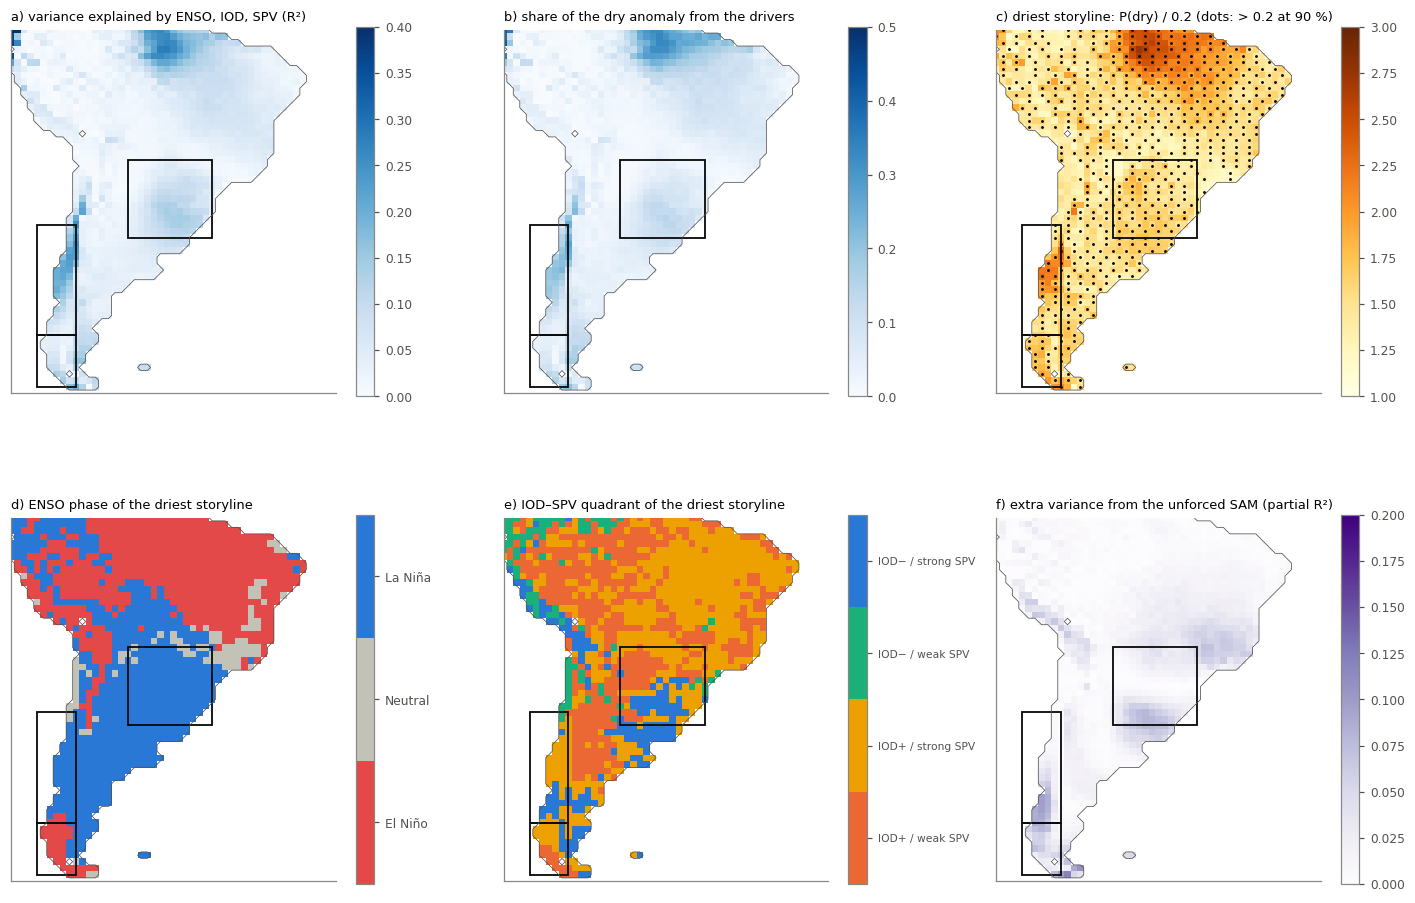

In [50]:
tp = reg["tp"].assign_coords(year=("forecast_reference_time", frt[use].year),
                             init_month=("forecast_reference_time", frt[use].month))
landm = reg["land"].values
glat, glon = reg.latitude.values, reg.longitude.values
st = tp.stack(s=("forecast_reference_time", "number")).transpose("s", "latitude", "longitude")
gkey = pd.MultiIndex.from_arrays([st.year.values, st.init_month.values, st.number.values],
                                 names=["year", "init_month", "number"])
GP = pd.DataFrame(st.values.reshape(len(gkey), -1)[:, landm.ravel()], index=gkey).reindex(df.index)
for m in INITS:                                               # detrend and standardise per init month
    rows_m = (df.index.get_level_values("init_month") == m)
    A = GP.values[rows_m]
    X1 = np.column_stack([np.ones(rows_m.sum()), yrs[rows_m]])
    beta, *_ = np.linalg.lstsq(X1, A, rcond=None)
    A = A - X1 @ beta
    GP.values[rows_m] = A / A.std(0)
Z = GP.values
ng = Z.shape[1]


def grid(v):
    g = np.full(landm.size, np.nan); g[landm.ravel()] = v
    return g.reshape(landm.shape)


XD = np.column_stack([np.ones(len(df)), df[ZV].values])
XDM = np.column_stack([XD, df[[f"{s_}_z" for s_ in SAMS]].values])
bD, *_ = np.linalg.lstsq(XD, Z, rcond=None)
bDM, *_ = np.linalg.lstsq(XDM, Z, rcond=None)
pD = XD @ bD
r2D = 1 - ((Z - pD) ** 2).sum(0) / (Z ** 2).sum(0)
r2DM = 1 - ((Z - XDM @ bDM) ** 2).sum(0) / (Z ** 2).sum(0)
pr2_sam = (r2DM - r2D) / (1 - r2D)
dryG = Z < np.quantile(Z, DRY_Q, axis=0)
dry_share = (pD * dryG).sum(0) / (Z * dryG).sum(0)

# storyline P(dry) at every point, with a year bootstrap for the driest one
onehot = pd.get_dummies(df.story).reindex(columns=STORIES, fill_value=False).values.astype(float)
cnts = onehot.sum(0)[:, None]
pdry_st = onehot.T @ dryG / cnts                               # 12 x points
best = np.nanargmax(np.where(cnts >= 50, pdry_st, np.nan), axis=0)
best_p = pdry_st[best, np.arange(ng)]
bsel = np.zeros(ng)
for ix in BOOT_IDX[:200]:
    oh, dg = onehot[ix], dryG[ix]
    pb = (oh.T @ dg) / np.maximum(oh.sum(0)[:, None], 1)
    bsel += pb[best, np.arange(ng)] > DRY_Q
sig_best = bsel / 200 >= 0.95

MAPS_ = dict(r2D=grid(r2D), dry_share=grid(dry_share), best_rr=grid(best_p / DRY_Q), best_sig=grid(sig_best.astype(float)),
             best_phase=grid(np.array([PH3.index(STORIES[b].split(" | ")[0]) for b in best], float)),
             best_quad=grid(np.array([QUADS.index(STORIES[b].split(" | ")[1]) for b in best], float)),
             pr2_sam=grid(pr2_sam))
for k, v in zip(["ENSO", "IOD", "SPV"], bD[1:]):
    MAPS_[f"b_{k}"] = grid(v)

# ERA5: the same regression on the 42 observed springs
eo = era["tp"].sel(year=obs.index.values).values.reshape(len(obs), -1)[:, landm.ravel()]
eo = eo - np.column_stack([np.ones(len(obs)), obs.index.values]) @ np.linalg.lstsq(
    np.column_stack([np.ones(len(obs)), obs.index.values]), eo, rcond=None)[0]
eo = eo / eo.std(0)
XO = np.column_stack([np.ones(len(obs)), obs[ZV].values])
bO, *_ = np.linalg.lstsq(XO, eo, rcond=None)
r2O = 1 - ((eo - XO @ bO) ** 2).sum(0) / (eo ** 2).sum(0)
for k, v in zip(["ENSO", "IOD", "SPV"], bO[1:]):
    MAPS_[f"bO_{k}"] = grid(v)
MAPS_["r2O"] = grid(r2O)


def draw_boxes(ax):
    for r, b in REGIONS.items():
        ax.add_patch(plt.Rectangle((b["lon"][0], b["lat"][0]), b["lon"][1] - b["lon"][0], b["lat"][1] - b["lat"][0],
                                   fill=False, ec=INK, lw=1.2))


def map_ax(ax, field, title, **kw):
    pcm = ax.pcolormesh(glon, glat, field, shading="nearest", **kw)
    ax.contour(glon, glat, landm.astype(float), levels=[0.5], colors="#52514e", linewidths=0.5)
    draw_boxes(ax)
    ax.set_xlim(280, 330); ax.set_ylim(-56, 0); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, loc="left", fontsize=8.5)
    return pcm


fig, axes = plt.subplots(2, 3, figsize=(13, 9.5))
pc = map_ax(axes[0, 0], MAPS_["r2D"], "a) variance explained by ENSO, IOD, SPV (R²)", cmap="Blues", vmin=0, vmax=0.4)
fig.colorbar(pc, ax=axes[0, 0], shrink=0.7)
pc = map_ax(axes[0, 1], MAPS_["dry_share"], "b) share of the dry anomaly from the drivers", cmap="Blues", vmin=0, vmax=0.5)
fig.colorbar(pc, ax=axes[0, 1], shrink=0.7)
pc = map_ax(axes[0, 2], MAPS_["best_rr"], "c) driest storyline: P(dry) / 0.2 (dots: > 0.2 at 90 %)",
            cmap="YlOrBr", vmin=1, vmax=3)
yy, xx = np.where(MAPS_["best_sig"] == 1)
axes[0, 2].scatter(glon[xx][::2], glat[yy][::2], s=0.8, color=INK)
fig.colorbar(pc, ax=axes[0, 2], shrink=0.7)
pc = map_ax(axes[1, 0], MAPS_["best_phase"], "d) ENSO phase of the driest storyline",
            cmap=mcolors.ListedColormap([PCOL["El Niño"], "#c3c2b7", PCOL["La Niña"]]), vmin=-0.5, vmax=2.5)
cb = fig.colorbar(pc, ax=axes[1, 0], shrink=0.7, ticks=[0, 1, 2]); cb.ax.set_yticklabels(PH3)
pc = map_ax(axes[1, 1], MAPS_["best_quad"], "e) IOD–SPV quadrant of the driest storyline",
            cmap=mcolors.ListedColormap([QCOL[q] for q in QUADS]), vmin=-0.5, vmax=3.5)
cb = fig.colorbar(pc, ax=axes[1, 1], shrink=0.7, ticks=range(4)); cb.ax.set_yticklabels(QUADS, fontsize=7)
pc = map_ax(axes[1, 2], MAPS_["pr2_sam"], "f) extra variance from the unforced SAM (partial R²)", cmap="Purples",
            vmin=0, vmax=0.2)
fig.colorbar(pc, ax=axes[1, 2], shrink=0.7)
fig.tight_layout(); savefig(fig, "fig23_driver_storyline_maps")

**Regression maps, SEAS5 against ERA5** (P on ENSO, IOD and SPV jointly; σ of P per σ of the driver). Boxes: northern and southern
Andes (west) and SESA (north-east). Bottom right: R² of the drivers in ERA5 (42 springs; values below ~0.18 are not distinguishable from 0).

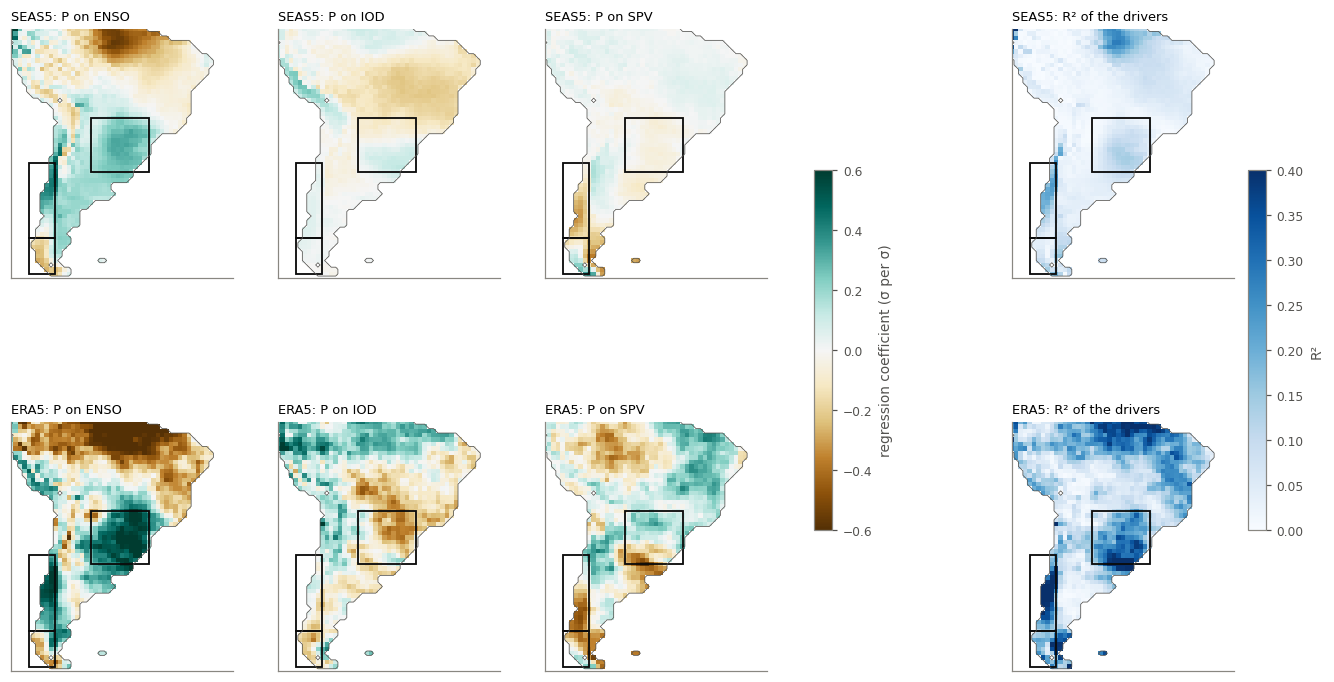

In [51]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8.5))
for j, k in enumerate(["ENSO", "IOD", "SPV"]):
    for i, (src, lab) in enumerate([("b_", "SEAS5"), ("bO_", "ERA5")]):
        pc = map_ax(axes[i, j], MAPS_[f"{src}{k}"], f"{lab}: P on {k}", cmap="BrBG", vmin=-0.6, vmax=0.6)
fig.colorbar(pc, ax=axes[:, :3], shrink=0.5, label="regression coefficient (σ per σ)")
pc = map_ax(axes[0, 3], MAPS_["r2D"], "SEAS5: R² of the drivers", cmap="Blues", vmin=0, vmax=0.4)
map_ax(axes[1, 3], MAPS_["r2O"], "ERA5: R² of the drivers", cmap="Blues", vmin=0, vmax=0.4)
fig.colorbar(pc, ax=axes[:, 3], shrink=0.5, label="R²")
savefig(fig, "fig24_regression_maps_seas5_era5")

**Do the boxes hide opposite signals?** For each box: the share of its land points where each coefficient is positive, the mean
point R² against the R² of the box mean, and the best point in the box.

In [52]:
box_tab = {}
for r, b in REGIONS.items():
    LA, LO = np.meshgrid(glat, glon, indexing="ij")
    inb = landm & (LA >= b["lat"][0]) & (LA <= b["lat"][1]) & (LO >= b["lon"][0]) & (LO <= b["lon"][1])
    row = {f"{src}{k} > 0": (MAPS_[f"{src}{k}"][inb] > 0).mean() for src in ["b_", "bO_"] for k in ["ENSO", "IOD", "SPV"]}
    row.update(points=int(inb.sum()), mean_point_R2=np.nanmean(MAPS_["r2D"][inb]), max_point_R2=np.nanmax(MAPS_["r2D"][inb]),
               box_mean_R2=1 - np.var(df[f"P_{r}_z"] - XD @ np.linalg.lstsq(XD, df[f"P_{r}_z"].values, rcond=None)[0])
               / np.var(df[f"P_{r}_z"]),
               mean_point_dry_share=np.nanmean(MAPS_["dry_share"][inb]),
               max_point_dry_share=np.nanmax(MAPS_["dry_share"][inb]))
    box_tab[r] = row
pd.DataFrame(box_tab).round(2)

,AndesN,AndesS,SESA
b_ENSO > 0,0.89,0.28,1.00
b_IOD > 0,0.97,0.82,0.52
b_SPV > 0,0.03,0.38,0.13
bO_ENSO > 0,0.98,0.40,0.95
bO_IOD > 0,0.37,0.20,0.21
bO_SPV > 0,0.21,0.25,0.64
points,62.00,40.00,172.00
mean_point_R2,0.13,0.07,0.07
max_point_R2,0.25,0.20,0.14
box_mean_R2,0.20,0.05,0.25


**Interpretation.**

* **The split Andes boxes hold one sign each.** In the northern Andes (30–47°S) 89 % of the points have a positive ENSO
  coefficient (ERA5 98 %) and 97 % a negative SPV coefficient; the box mean has R² 0.20, more than its average point (0.13).
  In the southern Andes (47–55°S) ENSO is mostly negative (72 % of points) but weak: R² is 0.05 for the box and at most 0.20 at a
  point. The driest storyline flips between the two boxes: La Niña in the north, El Niño in the south (fig23d).
* **SESA is not hurt by the box.** Every SESA point has a positive ENSO coefficient (ERA5 95 %); the box mean has R² 0.25, higher than
  any single point (≤ 0.14), because averaging removes local noise. The highest values are in the south of the box (Uruguay,
  Rio Grande do Sul).
* **Where the storylines work best** (fig23a–c): central Chile (R² up to about 0.25, driest storyline La Niña with a strong vortex,
  risk ratio 2–2.4), southern SESA (La Niña; 2–2.3) and northern South America (El Niño; up to 2.8). Most of Argentina
  and Patagonia have R² < 0.05.
* **The unforced SAM matters in southern Chile and around the Río de la Plata** (fig23f, partial R² up to about 0.1).
* **SEAS5 against ERA5** (fig24): the patterns agree in sign in most places, but ERA5 coefficients are larger in central Chile
  (ENSO) and over the Andes south of 40°S (SPV). The observed IOD map dries SESA and the southern Andes, which SEAS5 does not do.
  (With 42 springs and three drivers, ERA5 R² below ~0.18 is noise.)

## 12. Summary

One row per storyline: its probability within the ENSO phase, P(dry) in each region (both from Section 4, without the inner
20 % of IOD and SPV), the mean anomaly split into
direct / S-SAM forced / A-SAM forced / S-SAM unforced / A-SAM unforced terms and the extra P(dry) from each unforced SAM
(Section 6, plain sign quadrants), and
the ERA5 analogue spring.

In [53]:
summ = story[["phase", "storyline", "n", "prob"]].copy()
for r in REGIONS:
    summ[f"Pdry_{r}"] = story[f"Pdry_{r}"]
    for t in TERMS[:-1]:
        summ[f"{r}: {t}"] = [dec.loc[(p, q), f"{r}_{t}"] for p, q in zip(story.phase, story.storyline)]
    for s_ in MEDS:
        summ[f"{r}: extra Pdry unforced {s_}"] = [samdry.loc[(r, s_, p, q), "extra_Pdry_from_unforced"]
                                                  for p, q in zip(story.phase, story.storyline)]
summ["ERA5 analogue"] = [analog[(p, q)][0] for p, q in zip(story.phase, story.storyline)]
summ.to_csv(OUT / "enso_sam_storylines_table.csv", index=False)
summ.round(2)

,phase,storyline,n,prob,Pdry_AndesN,AndesN: direct,AndesN: S_SAM forced,AndesN: A_SAM forced,AndesN: SALLJ forced,AndesN: S_SAM unforced,...,SESA: S_SAM forced,SESA: A_SAM forced,SESA: SALLJ forced,SESA: S_SAM unforced,SESA: A_SAM unforced,SESA: SALLJ unforced,SESA: extra Pdry unforced S_SAM,SESA: extra Pdry unforced A_SAM,SESA: extra Pdry unforced SALLJ,ERA5 analogue
0,El Niño,IOD+ / weak SPV,226,0.46,0.04,0.02,0.26,0.04,0.44,0.04,...,0.05,-0.13,0.49,0.01,-0.00,-0.00,0.00,0.00,0.03,1994
1,El Niño,IOD+ / strong SPV,193,0.39,0.13,0.02,-0.10,0.02,0.37,-0.01,...,-0.02,-0.06,0.41,-0.00,0.00,0.07,0.00,0.00,-0.01,2015
2,El Niño,IOD− / weak SPV,32,0.07,0.03,-0.00,0.20,0.02,0.25,0.05,...,0.03,-0.08,0.28,0.01,-0.02,0.01,0.00,0.01,0.01,1991
3,El Niño,IOD− / strong SPV,38,0.08,0.21,-0.00,-0.13,0.01,0.21,-0.02,...,-0.02,-0.03,0.24,-0.00,-0.01,-0.01,0.01,-0.01,0.02,1986
4,La Niña,IOD+ / weak SPV,104,0.15,0.16,0.01,0.22,-0.00,-0.17,-0.01,...,0.04,0.01,-0.19,-0.00,-0.01,0.04,0.01,0.01,0.04,1988
5,La Niña,IOD+ / strong SPV,78,0.11,0.35,0.01,-0.21,-0.02,-0.25,0.02,...,-0.04,0.08,-0.28,0.00,0.01,-0.01,0.01,0.01,0.08,2021
6,La Niña,IOD− / weak SPV,209,0.29,0.17,-0.01,0.16,-0.01,-0.24,-0.02,...,0.03,0.03,-0.26,-0.00,0.00,0.05,-0.01,-0.01,0.00,1988
7,La Niña,IOD− / strong SPV,321,0.45,0.40,-0.02,-0.22,-0.03,-0.33,0.01,...,-0.04,0.10,-0.37,0.00,0.00,0.03,0.00,0.00,0.01,2021


## 13. Results in brief (run of 20 Oct 2026, 1981–2022; numbers from the cells above)

Regions: northern Andes (30–47°S), southern Andes (47–55°S), both 76–70°W, and SESA. The 1981–2016 version of these results is in
`02_enso_storylines_sam_pathways_1981-2016.ipynb`; the conclusions are the same unless noted (**changed**).

**Fidelity.** ERA5 lies inside the 95 % range of the hindcast sub-samples for all four moments, **except the SESA standard deviation**
(ERA5 0.83 mm/day against 0.51–0.77): the 2017–2022 springs (and the 0.25° ERA5 product) make observed SESA more variable than
SEAS5 (**changed**). 24 (northern Andes), 29 (southern Andes) and 24 (SESA) of 42 observed springs are within ±1σ of their hindcast
distribution. Median member-pair Spearman: 0.18–0.20, 0.05–0.11 and 0.24–0.28 (the ENSO signal, not member dependence). **SEAS5
underestimates the teleconnections**: northern Andes r(ENSO, P) = 0.33 against 0.56 in ERA5, r(SPV, P) = −0.31 against −0.41;
southern Andes ENSO −0.22 against −0.34, IOD −0.08 against −0.31; SESA ENSO 0.49 against 0.58.

**Storylines (Section 4; neutral springs and the inner 20 % of IOD and SPV left out).** *Northern Andes*: P(dry) is 0.10 in El Niño
and 0.29 in La Niña; **La Niña with a strong vortex is the dry storyline** (IOD−: 0.40 [0.33, 0.47], significantly drier than La Niña
overall; IOD+: 0.35 [0.28, 0.41]); in El Niño, the strong-vortex storylines (0.13 and 0.21) are drier than the phase (0.10).
*Southern Andes*: the reverse, P(dry) 0.29 in El Niño and 0.15 in La Niña; El Niño IOD+/strong SPV is the driest storyline (0.36
[0.28, 0.44]) but **no longer significantly drier than El Niño overall** (**changed**; 0.41 in 1981–2016). *SESA*: ENSO decides,
P(dry) 0.05 in El Niño and 0.33 in La Niña; IOD+ storylines drier (0.31–0.37) but not significantly.

**Pathways (Section 5; mediators S-SAM, A-SAM and SACZ).** *Northern Andes*: ENSO's total +0.33 is +0.19 direct, +0.05 through
S-SAM, +0.06 through A-SAM and +0.03 through the SACZ (consistent mediation; 42 % through the mediators). The SPV's −0.30 goes almost
entirely through S-SAM (−0.25; proportion mediated 0.83), with −0.04 through A-SAM and −0.01 through the SACZ. So **the vortex acts
through S-SAM**. *Southern Andes*: ENSO's −0.22 is −0.40 direct against +0.19 through the SAM (mostly A-SAM, +0.16): inconsistent
mediation; the SPV's direct (+0.26) and through-SAM (−0.26) effects cancel; the SACZ plays no role. *SESA*: ENSO acts directly
(0.47 of 0.49). **The SACZ is mostly unforced** in SEAS5; an active SACZ dries the northern Andes (−0.23) and SESA (−0.17, the seesaw);
in ERA5 none of the SACZ → P arrows is significant, and for SESA the sign is reversed.

**Extra drying from the SAM and SACZ beyond the drivers (Section 6).** On average almost none: removing any unforced mediator changes
P(dry) by at most 0.06 in any storyline. In information: northern Andes, drivers 0.156 bits (direct 0.049, through S-SAM 0.070,
A-SAM 0.024, SACZ 0.013) and unforced mediators 0.110 bits (41 % of the total: S-SAM 0.043, A-SAM 0.020, **SACZ 0.046**); **southern
Andes, drivers 0.031 bits and unforced mediators 0.051 bits (63 %)**, mostly A-SAM (0.032); SESA, unforced SACZ 0.024 bits (11 %),
the SAM ≤ 0.002. The unforced SAM widens the storylines: northern Andes La Niña IOD−/strong SPV, P(dry) 0.51 / 0.22 in the drying /
wetting tercile of the unforced S-SAM; southern Andes El Niño IOD+, 0.45–0.47 / 0.21–0.23 for A-SAM.

**Forecast mode, init June (Section 8).** About 4.4 of the 12 storylines stay plausible and 7.6 are discarded. The observed storyline
was plausible in 36 of 42 springs (86 %), against 45 % for a climatological set of the same size, while the ensemble-mean storyline was
right only 33 % of the time. Discarded storylines occurred 1.9 % of the time. The ENSO phase is decided (≥ 80 % of members) in 55 % of
June forecasts and the IOD sign in 38 %, the **SPV sign never**. The drought springs 2019–2022 were all plausible in June (2019:
21 of 51 members; 2020: 25; 2021: 6; 2022: 11); 2017 (La Niña with IOD+) was the one recent miss. In poor-ensemble-mean years the
observed-storyline mean beats the ensemble mean and random sub-ensembles in both Andes boxes (errors 1.42 and 1.16 against 1.54–1.57 and
1.45–1.46); SESA shows no gain. Of the 6 June driver misses, 5 are ENSO and 1 the IOD (1985). Springs with precipitation outside the
5–95 % range are **not** explained by mispredicted drivers (≤ 3 % of the squared error).

**Bottom-up storylines (Section 9).** No distinct clusters (silhouette ≤ 0.33). 77 % of northern-Andes dry springs fall in strong-vortex
clusters; the southern Andes dry routes are El Niño with IOD+ and La Niña or neutral with a strong vortex; SESA dry clusters all have
ENSO ≤ 0. Starting from one ENSO phase finds only 32–48 % of the dry springs.

**Top-down vs bottom-up reliability (Section 9.1).** Both are reliable at the low end (they discard safely) and give the same
dry-spring skill (BSS 0.06–0.12 against ERA5, intervals overlapping); both beat the raw ensemble in the Andes in the perfect model.
Against ERA5 the storyline probabilities score the same (BSS 0.15–0.20); in the perfect model the bottom-up ones score higher
(0.23–0.28 against 0.20), because the clusters follow the predictable ENSO/IOD direction (**changed**: in 1981–2016 bottom-up also
scored higher against ERA5).

**Gaps (Section 10).** Driest storylines: El Niño IOD+/strong vortex in the southern Andes (very-dry risk 2.8 times climatology; 3.5 with a
drying unforced SAM), La Niña with a strong vortex in the northern Andes (2.1–2.2; 3.5) and La Niña in SESA (1.8–2.2). Gaps:
(1) **strong-vortex corners** (La Niña for the northern Andes, El Niño for the southern Andes: 2015, 2020–2022), nearly empty in the
hindcast; (2) **La Niña with IOD+** (SESA, northern Andes), very-dry springs from 6–9 years; (3) the **tail within the storylines**:
the observed SESA spring of 2020 (−2.6σ) is at the hindcast's 0.4th percentile. Experiments: E1 nudged strong vortex, E2 La Niña + IOD+
pacemaker, E3 ensemble boosting, E4 eastern-Pacific (SESA) and SE-Pacific (southern Andes) SST arms.

**Dry springs with other causes (Section 10.3).** The drivers supply 20 % (northern Andes), 5 % (southern Andes) and 21 % (SESA) of
the dry anomaly; the unforced SAM and SACZ almost never dominate; the rest comes with local blocking ridges/highs west of the Andes.
Candidate extra drivers: **Niño1+2 for SESA** (partial r 0.18 SEAS5 / 0.25 observed) and **SE Pacific SST for the southern Andes**
(−0.26 / −0.26); with 40 observed springs neither observed value reaches the 5 % threshold (**changed**: the SE Pacific was
significant in 1981–2016).

**Maps (Section 11).** The split boxes hold one sign each (northern box R² 0.20, more than its average point). The storylines work best
in central Chile, southern SESA and northern South America; in Patagonia the drivers explain little.

**Caveats.** The weak SEAS5 teleconnections mean the drivers' share is probably underestimated. The path model is linear and fitted
on the pooled hindcast; 2017–2022 have 51 members, so those six years weigh about twice as much as the others in the pooled statistics.
The observed S-/A-SAM are missing for 2002 and 2019. With 42 years, the forecast-mode rates have wide uncertainty (one year = 2.4 %).